# Giros Tesorales

In [ ]:
#from google.colab import drive
#drive.mount('/content/drive')

Mounted at /content/drive


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.ticker as mtick
from scipy.stats import chisquare, ks_2samp


In [2]:
crp = []
lista_df = []
lista_outliers = []

In [3]:
df = pd.read_csv("giros.csv", sep=";")

C:\Users\DVadeus\AppData\Local\Temp\ipykernel_10300\3658427298.py:1: DtypeWarning: Columns (38,39,40,41) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv("giros.csv", sep=";")


In [4]:
df.head(20)

,Vigencia,ID_Giro,Número de orden de pago,Orden de pago,ID_Tercero,Fecha Giro,Número de cuenta,Banco,Tipo de giro,Razon_Social,...,Valor Neto,Cuenta contable,Debito,Credito,ID_Soporte,Pagado,Valor sanción,Valor Intereses,Valor Multas,Valor Reconexion
0,2021,ORDEN DE PAGO,2991,SI,1088259568,3/02/2021,1.272702e+11,BANCO DAVIVIENDA S.A.,Transferencia,YONNY ANDRES CRUZ BENJUMEA,...,$ 1.499.478,1110,NaN,$ 1.499.478,2991,SI,$ -,$ -,$ -,$ -
1,2021,ORDEN DE PAGO,2992,SI,1088259568,3/02/2021,1.272702e+11,BANCO DAVIVIENDA S.A.,Transferencia,YONNY ANDRES CRUZ BENJUMEA,...,$ 312.500,1110,NaN,$ 312.500,2992,SI,$ -,$ -,$ -,$ -
2,2021,ORDEN DE PAGO,3001,SI,52539367,4/02/2021,5.700089e+14,BANCO DAVIVIENDA S.A.,Transferencia,ALEXANDRA VARGAS PINILLA,...,$ 7.290.786,1110,NaN,$ 7.290.786,3001,SI,$ -,$ -,$ -,$ -
3,2021,ORDEN DE PAGO,3047,SI,1094938732,8/02/2021,1.202372e+08,BANCOLOMBIA S A,Transferencia,MARIA ALEJANDRA LONDOÑO JIMENEZ,...,$ 1.447.500,1110,NaN,$ 1.447.500,3047,SI,$ -,$ -,$ -,$ -
4,2021,ORDEN DE PAGO,3053,SI,1093773164,8/02/2021,5.704574e+14,BANCO DAVIVIENDA S.A.,Transferencia,JURGEN DANIEL TOLOZA DELGADO,...,$ 6.184.861,1110,NaN,$ 6.184.861,3053,SI,$ -,$ -,$ -,$ -
5,2021,ORDEN DE PAGO,3065,SI,1088303099,9/02/2021,2.700005e+10,BANCOLOMBIA S A,Transferencia,SILVIA ABAD HERNANDEZ,...,$ 4.866.140,1110,NaN,$ 4.866.140,3065,SI,$ -,$ -,$ -,$ -
6,2021,ORDEN DE PAGO,3067,SI,7515099,9/02/2021,4.654375e+10,BANCOLOMBIA S A,Transferencia,LUIS EDUARDO HERNANDEZ SAENZ,...,$ 6.039.863,1110,NaN,$ 6.039.863,3067,SI,$ -,$ -,$ -,$ -
7,2021,ORDEN DE PAGO,3068,SI,4520638,9/02/2021,7.214361e+10,BANCOLOMBIA S A,Transferencia,JHONATAN FELIPE SALDARRIAGA MEJIA,...,$ 3.649.605,1110,NaN,$ 3.649.605,3068,SI,$ -,$ -,$ -,$ -
8,2021,ORDEN DE PAGO,3069,SI,25181384,9/02/2021,4.510566e+08,BANCO BILBAO VIZCAYA ARGENTARIA COLOMBIA S A,Transferencia,MARIA ANDREA VILLALBA YATE,...,$ 4.866.140,1110,NaN,$ 4.866.140,3069,SI,$ -,$ -,$ -,$ -
9,2021,ORDEN DE PAGO,3070,SI,24644591,9/02/2021,2.595133e+08,BANCO DAVIVIENDA S.A.,Transferencia,PATRICIA ELENA MONTES GIRALDO,...,$ 4.866.140,1110,NaN,$ 4.866.140,3070,SI,$ -,$ -,$ -,$ -


## Descripción de los datos

In [5]:
df.dtypes

Vigencia                        int64
ID_Giro                        object
Número de orden de pago         int64
Orden de pago                  object
ID_Tercero                      int64
Fecha Giro                     object
Número de cuenta              float64
Banco                          object
Tipo de giro                   object
Razon_Social                   object
Tipo de persona                object
Tipo de gasto                  object
Fecha CRP                      object
CRP                             int64
Fecha CDP                      object
CDP                             int64
Anulado                        object
Valor Bruto                    object
IVA                            object
Actividad gravada IVA          object
Porcentaje ICA                 object
ICA                            object
Actividad gravada ICA          object
Porcentaje ReteFte             object
ReteFte                        object
ReteICA                        object
ReteIVA     

#### Datos nulos

In [6]:
df.isnull().sum()

Vigencia                          0
ID_Giro                           0
Número de orden de pago           0
Orden de pago                     0
ID_Tercero                        0
Fecha Giro                        0
Número de cuenta                415
Banco                           415
Tipo de giro                      0
Razon_Social                      0
Tipo de persona                   0
Tipo de gasto                     0
Fecha CRP                         0
CRP                               0
Fecha CDP                         0
CDP                               0
Anulado                        4687
Valor Bruto                       0
IVA                               0
Actividad gravada IVA         16272
Porcentaje ICA                 2468
ICA                               0
Actividad gravada ICA          4303
Porcentaje ReteFte                0
ReteFte                           0
ReteICA                           0
ReteIVA                           0
Estampilla                  

In [7]:
len(df)

16900

## Fase 0 - Entendimiento y limpieza

In [8]:
df.describe()

,Vigencia,Número de orden de pago,ID_Tercero,Número de cuenta,CRP,CDP,Cuenta contable,Debito,ID_Soporte
count,16900.000000,16900.000000,1.690000e+04,1.648500e+04,16900.000000,16900.000000,16900.0,0.0,16900.000000
mean,2022.299822,5257.367929,5.225799e+08,1.758401e+14,1158.881775,822.403373,1110.0,NaN,5257.367929
std,0.897485,3307.084036,5.017273e+08,3.215965e+15,870.650874,555.367156,0.0,NaN,3307.084036
min,2021.000000,1.000000,2.631771e+06,3.210000e+03,1.000000,1.000000,1110.0,NaN,1.000000
25%,2022.000000,2390.000000,4.549553e+07,5.832006e+09,481.750000,349.000000,1110.0,NaN,2390.000000
50%,2022.000000,5110.500000,8.087536e+07,2.410796e+10,976.000000,780.000000,1110.0,NaN,5110.500000
75%,2023.000000,7781.000000,1.051679e+09,9.122909e+10,1583.000000,1156.000000,1110.0,NaN,7781.000000
max,2024.000000,12801.000000,1.238339e+09,1.307030e+17,4222.000000,2785.000000,1110.0,NaN,12801.000000


#### Observaciones

- Número de cuenta: Los números de cuentas bancarías son generalmente entre 10 a 20 dígitos. Sin embargo encontramos una cuenta bancaria de 4 dígitos.
- Todos los giros fueron registrados en la cuenta 1110 Bancos

### Eliminación de características

Enumeración de características

In [9]:
df.columns

Index(['Vigencia', 'ID_Giro', 'Número de orden de pago', 'Orden de pago',
       'ID_Tercero', 'Fecha Giro', 'Número de cuenta', 'Banco', 'Tipo de giro',
       'Razon_Social', 'Tipo de persona', 'Tipo de gasto', 'Fecha CRP', 'CRP',
       'Fecha CDP', 'CDP', 'Anulado', 'Valor Bruto', 'IVA',
       'Actividad gravada IVA', 'Porcentaje ICA', 'ICA',
       'Actividad gravada ICA', 'Porcentaje ReteFte', 'ReteFte', 'ReteICA',
       'ReteIVA', 'Estampilla', 'Estampilla Universidad FJC', 'Adulto mayor',
       'Otros descuentos', 'Total descuentos', 'Valor Neto', 'Cuenta contable',
       'Debito', 'Credito', 'ID_Soporte', 'Pagado', 'Valor sanción',
       'Valor Intereses', 'Valor Multas', 'Valor Reconexion'],
      dtype='object')

De los 16900 giros presentes en el set de datos encontramos que las siguientes características:

- Debito: No contiene datos
- Actividad gravada IVA: 16.272 datos nulos, solo 628 datos tienen actividad gravada en IVA
- Anulado: 4.687 datos nulos
- Banco y Número de cuenta: **415** Datos nulos
- Sanción, Intereses, Multas y Reconexión: A pesar de que aparezcan con datos, únicamente contienen el siguiente dato: ``' $ -   '``

In [10]:
print(f"ID_Giros: {df["ID_Giro"].unique()}")
print(f"Orden de pago: {df["Orden de pago"].unique()}")
print(f"Tipo de giro: {df["Tipo de giro"].unique()}")
print(f"Anulado: {df["Anulado"].unique()}")
print(f"Valor sanción: {df["Valor sanción"].unique()}")
print(f"Valor Intereses: {df["Valor Intereses"].unique()}")
print(f"Valor Multas: {df["Valor Multas"].unique()}")
print(f"Valor Reconexion: {df["Valor Reconexion"].unique()}")
print(f"Debito: {df["Debito"].unique()}")
print(f"Pagado: {df["Pagado"].unique()}")

ID_Giros: ['ORDEN DE PAGO']
Orden de pago: ['SI']
Tipo de giro: ['Transferencia']
Anulado: ['NO' nan]
Valor sanción: [' $ -   ' nan]
Valor Intereses: [' $ -   ' nan]
Valor Multas: [' $ -   ' nan]
Valor Reconexion: [' $ -   ' nan]
Debito: [nan]
Pagado: ['SI']


In [11]:
col_eliminar = [
    "ID_Giro",
    "Orden de pago",
    "Tipo de giro",
    "Anulado",
    "Valor sanción",
    "Valor Intereses",
    "Valor Multas",
    "Valor Reconexion",
    "Debito",
    "Pagado"
]

df.drop(col_eliminar, axis = 1, inplace = True)

### Transformación de tipos de columna

#### Verificación de que todos los ``ID_Tercero`` sean de tipo número

In [12]:
df['ID_Tercero'].isnull().any()

np.False_

In [13]:
is_all_numeric = pd.to_numeric(df['ID_Tercero'], errors='coerce').notnull().all()
is_all_numeric

np.True_

In [14]:
df['ID_Tercero'].dtype

dtype('int64')

In [15]:
df["ID_Tercero"] = df["ID_Tercero"].astype(int)

#### Columnas de tipo número

In [16]:
numeric_cols = [
    "Valor Bruto",
    "IVA",
    "ICA",
    "ReteFte",
    "ReteICA",
    "ReteIVA",
    "Estampilla",
    "Estampilla Universidad FJC",
    "Adulto mayor",
    "Otros descuentos",
    "Total descuentos",
    "Valor Neto",
    "Credito"
]

In [17]:
for col in numeric_cols:
        if col in df.columns:
            print(f"Modificando: {col}")
            df[col] = df[col].str.replace('$', '', regex = False).str.strip()
            df[col] = df[col].str.replace('.','', regex = False)
            df[col] = pd.to_numeric(df[col], errors = "coerce")

Modificando: Valor Bruto
Modificando: IVA
Modificando: ICA
Modificando: ReteFte
Modificando: ReteICA
Modificando: ReteIVA
Modificando: Estampilla
Modificando: Estampilla Universidad FJC
Modificando: Adulto mayor
Modificando: Otros descuentos
Modificando: Total descuentos
Modificando: Valor Neto
Modificando: Credito


#### Columnas de tipo fecha

En la característica ``"Fecha CRP"`` existen 2 registros con el dato ``"#N/D"``

In [18]:
df[df["Fecha CRP"] == "#N/D"]

,Vigencia,Número de orden de pago,ID_Tercero,Fecha Giro,Número de cuenta,Banco,Razon_Social,Tipo de persona,Tipo de gasto,Fecha CRP,...,ReteIVA,Estampilla,Estampilla Universidad FJC,Adulto mayor,Otros descuentos,Total descuentos,Valor Neto,Cuenta contable,Credito,ID_Soporte
3560,2022,7449,1018424802,3/03/2022,6.027118e+10,BANCOLOMBIA S A,LIZ YORLENY RODRIGUEZ GOMEZ,NATURAL,SERVICIOS,#N/D,...,NaN,5833.0,NaN,23333.0,NaN,30093.0,1136573,1110,1136573,7449
3856,2022,8046,80192761,24/06/2022,2.452748e+10,BANCO CAJA SOCIAL S.A.,AGAPITO CASTRO CASTRO,NATURAL,SERVICIOS,#N/D,...,NaN,4167.0,NaN,16667.0,NaN,20834.0,812499,1110,812499,8046


Será reemplazado por `NA`

In [19]:
df["Fecha CRP"] = df["Fecha CRP"].replace("#N/D", pd.NA)

#### ✅ Agregar los giros a la lista



In [20]:
lista_df.append(df[df["Fecha CRP"].isna()])

#### Transformación de fechas al formato día/mes/año

In [21]:
fecha_cols = [
    'Fecha Giro',
    'Fecha CRP',
    'Fecha CDP']

for fecha in fecha_cols:
    if fecha in df.columns:
        df[fecha] = pd.to_datetime(df[fecha], format='%d/%m/%Y')

#### Transformación de columnas a tipo categórica

In [22]:
categ_col = [
    'Tipo de persona',
    'Tipo de gasto',
    'Actividad gravada IVA',
    'Actividad gravada ICA'
]

In [23]:
for categ in categ_col:
    if categ in df.columns:
        df[categ] = df[categ].astype('category')

#### Transformación Número de Cuenta a String

In [24]:
df["Número de cuenta"] = df["Número de cuenta"].replace(np.nan, pd.NA)
def to_str(x):
    if x is pd.NA:
        return pd.NA
    return str(int(x))

df["Número de cuenta"] = df["Número de cuenta"].apply(to_str)

### Transformación de datos

#### Porcentajes de ICA y RteFte

In [25]:
set(df['Porcentaje ReteFte'])

{' $ -   ',
 ' HONORARIOS 11% ',
 ' RETEFUENTE ARRIENDOS 3.5% ',
 ' RETEFUENTE ARRIENDOS 4.0% ',
 ' RETEFUENTE COMPRAS 2.5% ',
 ' RETEFUENTE CONSULTORIA 11% ',
 ' RETEFUENTE EMPLEADOS ART. 383 E.T. ',
 ' RETEFUENTE SERVICIOS DE TRANSPORTE 3.5% ',
 ' SERVICIOS 2% ',
 ' SERVICIOS 4% ',
 '0',
 'HONORARIOS 10%',
 'HONORARIOS 11%',
 'HONORARIOS LEY 1450 2011',
 'RETEFUENTE A TRABAJADORES POR CUENTA PROPIA',
 'RETEFUENTE ARRIENDOS 3.5%',
 'RETEFUENTE COMPRAS 2.5%',
 'RETEFUENTE COMPRAS 3.5%',
 'RETEFUENTE CONSULTORIA 11%',
 'RETEFUENTE EMPLEADOS ART. 383 E.T.',
 'RETEFUENTE SERVICIOS DE TRANSPORTE 3.5%',
 'SERVICIOS 1%',
 'SERVICIOS 2%',
 'SERVICIOS 3.5%',
 'SERVICIOS 4%'}

In [26]:
df['Porcentaje ReteFte'] = df['Porcentaje ReteFte'].replace(' $ -   ', pd.NA)
df['Porcentaje ReteFte'] = df['Porcentaje ReteFte'].replace('0', pd.NA)

In [27]:
set(df['Porcentaje ReteFte'])

{' HONORARIOS 11% ',
 ' RETEFUENTE ARRIENDOS 3.5% ',
 ' RETEFUENTE ARRIENDOS 4.0% ',
 ' RETEFUENTE COMPRAS 2.5% ',
 ' RETEFUENTE CONSULTORIA 11% ',
 ' RETEFUENTE EMPLEADOS ART. 383 E.T. ',
 ' RETEFUENTE SERVICIOS DE TRANSPORTE 3.5% ',
 ' SERVICIOS 2% ',
 ' SERVICIOS 4% ',
 <NA>,
 'HONORARIOS 10%',
 'HONORARIOS 11%',
 'HONORARIOS LEY 1450 2011',
 'RETEFUENTE A TRABAJADORES POR CUENTA PROPIA',
 'RETEFUENTE ARRIENDOS 3.5%',
 'RETEFUENTE COMPRAS 2.5%',
 'RETEFUENTE COMPRAS 3.5%',
 'RETEFUENTE CONSULTORIA 11%',
 'RETEFUENTE EMPLEADOS ART. 383 E.T.',
 'RETEFUENTE SERVICIOS DE TRANSPORTE 3.5%',
 'SERVICIOS 1%',
 'SERVICIOS 2%',
 'SERVICIOS 3.5%',
 'SERVICIOS 4%'}

In [28]:
set(df['Porcentaje ICA'])


{'0',
 'RETEICA - ARMENIA - PROFESIONAL Y TÉCNICO',
 'RETEICA - ARMENIA - SERVICIO TRANSPORTE',
 'RETEICA - CTGENA ARRENDAMIENTO',
 'RETEICA - CTGENA SERV. TEC. Y PROF.',
 'RETEICA - CTGENA SERV. TRANSPORTE',
 'RETEICA - CTGENA VIGILANCIA Y TEMPORALES',
 'RETEICA - DOSQUEBRADAS SERV. TEC Y PROF.',
 'RETEICA - DOSQUEBRADAS SERVICIO TRANSPORTE',
 'RETEICA - GENERAL 0.5',
 'RETEICA - GENERAL 0.8',
 'RETEICA - PEREIRA ARRENDAMIENTOS',
 'RETEICA - PEREIRA SERV. PROFESIONALES',
 'RETEICA - PEREIRA SERV. TECNICOS',
 'RETEICA - PEREIRA SERV. TRANSPORTE',
 'RETEICA - SERVICIOS - SEGUROS GENERALES',
 'RETEICA 11.04% BIENES',
 'RETEICA 13.8% SERVICIOS',
 'RETEICA 6.9% BIENES',
 'RETEICA 6.9% SERVICIOS',
 'RETEICA 7.66% SERVICIOS',
 'RETEICA 8.66% SERVICIOS',
 'RETEICA 9.66% BIENES',
 'RETEICA 9.66% SERVICIOS',
 'RETEICA PALMIRA ARRENDAMIENTOS',
 'RETEICA PALMIRA SERV. TEC. Y PROF.',
 'RETEICA PALMIRA SERVICIOS',
 'RETEICA PALMIRA TRANSPORTE',
 'RETEICA S. ROSA DE CABAL ARRENDAMIENTO',
 'RETEICA S

In [29]:
df['Porcentaje ICA'] = df['Porcentaje ICA'].replace('0', pd.NA)
df['Porcentaje ICA'] = df['Porcentaje ICA'].fillna(pd.NA)

In [30]:
set(df['Porcentaje ICA'])

{<NA>,
 'RETEICA - ARMENIA - PROFESIONAL Y TÉCNICO',
 'RETEICA - ARMENIA - SERVICIO TRANSPORTE',
 'RETEICA - CTGENA ARRENDAMIENTO',
 'RETEICA - CTGENA SERV. TEC. Y PROF.',
 'RETEICA - CTGENA SERV. TRANSPORTE',
 'RETEICA - CTGENA VIGILANCIA Y TEMPORALES',
 'RETEICA - DOSQUEBRADAS SERV. TEC Y PROF.',
 'RETEICA - DOSQUEBRADAS SERVICIO TRANSPORTE',
 'RETEICA - GENERAL 0.5',
 'RETEICA - GENERAL 0.8',
 'RETEICA - PEREIRA ARRENDAMIENTOS',
 'RETEICA - PEREIRA SERV. PROFESIONALES',
 'RETEICA - PEREIRA SERV. TECNICOS',
 'RETEICA - PEREIRA SERV. TRANSPORTE',
 'RETEICA - SERVICIOS - SEGUROS GENERALES',
 'RETEICA 11.04% BIENES',
 'RETEICA 13.8% SERVICIOS',
 'RETEICA 6.9% BIENES',
 'RETEICA 6.9% SERVICIOS',
 'RETEICA 7.66% SERVICIOS',
 'RETEICA 8.66% SERVICIOS',
 'RETEICA 9.66% BIENES',
 'RETEICA 9.66% SERVICIOS',
 'RETEICA PALMIRA ARRENDAMIENTOS',
 'RETEICA PALMIRA SERV. TEC. Y PROF.',
 'RETEICA PALMIRA SERVICIOS',
 'RETEICA PALMIRA TRANSPORTE',
 'RETEICA S. ROSA DE CABAL ARRENDAMIENTO',
 'RETEICA 

La columna ``"Actividad gravada IVA"`` cuenta con datos con espacios en blanco generando duplicidad artificial. Serán arreglados.

In [31]:
print(f"Actividad gravada IVA: {set(df["Actividad gravada IVA"])}")

Actividad gravada IVA: {nan, 'BIENES', 'SERVICIOS', ' ARRENDAMIENTO ', ' SERVICIOS ', 'ARRENDAMIENTO'}


In [32]:
df["Actividad gravada IVA"] = df["Actividad gravada IVA"].str.replace(' ', '')

In [33]:
print(f"Actividad gravada IVA: {set(df["Actividad gravada IVA"])}")

Actividad gravada IVA: {nan, 'BIENES', 'SERVICIOS', 'ARRENDAMIENTO'}


#### Rellenar datos nulos con 0

Para las características:

- IVA
- ICA
- ReteFte
- ReteICA
- ReteIVA
- Estampilla
- Estampilla Universidad FJC
- Adulto mayor
- Otros descuentos
- Total descuentos


In [34]:
rellenar_col = [
    'IVA',
    'ICA',
    'ReteFte',
    'ReteICA',
    'ReteIVA',
    'Estampilla',
    'Estampilla Universidad FJC',
    'Adulto mayor',
    'Otros descuentos',
    'Total descuentos'
]

In [35]:
for rellenar in rellenar_col:
    if rellenar in df.columns:
        df[rellenar] = df[rellenar].fillna(0)

### Creación de ID Compuesto

No existe un identificador único para cada giro tesoral, es por ello que se creará uno apartir de las siguientes características:

In [36]:
df["id_unico"] = (
    df["Número de orden de pago"].astype(str) + "_" +
    df["ID_Tercero"].astype(str) + "_"
)

## Fase 1 - Análisis descriptivo

In [37]:
df.describe()

,Vigencia,Número de orden de pago,ID_Tercero,Fecha Giro,Fecha CRP,CRP,Fecha CDP,CDP,Valor Bruto,IVA,...,ReteIVA,Estampilla,Estampilla Universidad FJC,Adulto mayor,Otros descuentos,Total descuentos,Valor Neto,Cuenta contable,Credito,ID_Soporte
count,16900.000000,16900.000000,1.690000e+04,16900,16898,16900.000000,16900,16900.000000,1.690000e+04,1.690000e+04,...,1.690000e+04,1.690000e+04,1.690000e+04,1.690000e+04,16900.000000,1.690000e+04,1.690000e+04,16900.0,1.690000e+04,16900.000000
mean,2022.299822,5257.367929,5.225799e+08,2022-12-02 01:08:35.502958592,2022-09-09 10:11:41.337436416,1158.881775,2022-04-27 09:36:56.236686592,822.403373,5.877725e+06,2.284172e+04,...,2.548412e+04,2.013478e+04,8.993479e+03,8.054960e+04,0.761243,2.856534e+05,5.592072e+06,1110.0,5.592072e+06,5257.367929
min,2021.000000,1.000000,2.631771e+06,2021-01-22 00:00:00,2021-01-21 00:00:00,1.000000,2021-01-04 00:00:00,1.000000,2.000000e+00,0.000000e+00,...,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000,0.000000e+00,2.000000e+00,1110.0,2.000000e+00,1.000000
25%,2022.000000,2390.000000,4.549553e+07,2022-04-06 00:00:00,2022-01-28 00:00:00,481.750000,2022-01-04 00:00:00,349.000000,1.933920e+06,0.000000e+00,...,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000,4.344000e+04,1.877514e+06,1110.0,1.877514e+06,2390.000000
50%,2022.000000,5110.500000,8.087536e+07,2022-11-11 00:00:00,2022-08-03 00:00:00,976.000000,2022-06-03 00:00:00,780.000000,3.500000e+06,0.000000e+00,...,0.000000e+00,1.350800e+04,0.000000e+00,5.403300e+04,0.000000,1.055540e+05,3.381490e+06,1110.0,3.381490e+06,5110.500000
75%,2023.000000,7781.000000,1.051679e+09,2023-08-03 00:00:00,2023-03-08 00:00:00,1583.000000,2022-06-24 00:00:00,1156.000000,5.145984e+06,0.000000e+00,...,0.000000e+00,2.315700e+04,0.000000e+00,9.262800e+04,0.000000,1.596790e+05,4.982409e+06,1110.0,4.982409e+06,7781.000000
max,2024.000000,12801.000000,1.238339e+09,2024-12-30 00:00:00,2024-12-26 00:00:00,4222.000000,2024-10-03 00:00:00,2785.000000,1.975339e+09,7.249007e+06,...,7.249007e+06,7.493740e+06,5.423418e+06,2.997496e+07,12865.000000,5.339692e+07,1.958420e+09,1110.0,1.958420e+09,12801.000000
std,0.897485,3307.084036,5.017273e+08,NaN,NaN,870.650874,NaN,555.367156,3.553053e+07,2.498619e+05,...,2.543437e+05,9.051015e+04,1.182126e+05,3.620412e+05,98.961538,1.561749e+06,3.456304e+07,0.0,3.456304e+07,3307.084036


### Volumen de giros

#### Total giros por Año

In [38]:
df["año"] = df["Fecha Giro"].dt.year
df["mes"] = df["Fecha Giro"].dt.month

In [39]:
giro_anio = df.groupby(["año"])['Valor Neto'].sum().reset_index(name = 'Valor neto total')
giro_anio

,año,Valor neto total
0,2021,17033502564
1,2022,43654379673
2,2023,25701594635
3,2024,8116535412


Hay una distribución anormal en los datos para la característica ``"Valor Neto Total"`` cruzuado con ``"Año"``.
- Presentando al año 2022 con el gasto tesoral más elevado de los 4 años

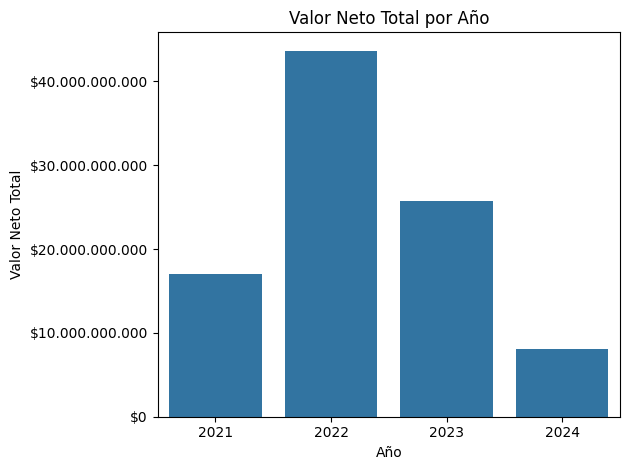

In [40]:
plt.figure()
ax = sns.barplot(data=giro_anio, x="año", y="Valor neto total")

def formato_moneda(x, _):
  return f"${x:,.0f}".replace(",", ".")

ax.yaxis.set_major_formatter(mtick.FuncFormatter(formato_moneda))

plt.title("Valor Neto Total por Año")
plt.xlabel("Año")
plt.ylabel("Valor Neto Total")
plt.tight_layout()
plt.show()

#### Análisis porcentual

In [41]:
giro_anio["variacion_%"] = giro_anio["Valor neto total"].pct_change() * 100
giro_anio["variacion_%"]

0           NaN
1    156.285397
2    -41.124820
3    -68.420110
Name: variacion_%, dtype: float64

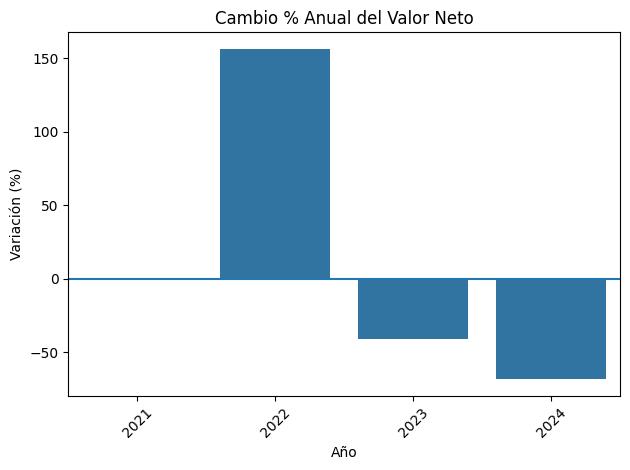

In [42]:
plt.figure()
sns.barplot(data=giro_anio, x="año", y="variacion_%")

plt.title("Cambio % Anual del Valor Neto")
plt.xlabel("Año")
plt.ylabel("Variación (%)")

plt.axhline(0)  # línea base
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Revisando la variación porcentual encontramos:

- Un crecimiento en el año 2022 de un 156.28% con respecto al año 2021.
- Un decremento en el año 2023 de un 41.12% con respecto al año 2022.
- Un decremento en el año 2024 de un 68.42% con respecto al año 2023.

#### Análisis temporal mes - año

In [43]:
giro_mes = df.groupby(["año", "mes"])['Valor Neto'].sum().reset_index(name = 'Valor neto total').sort_values(by="Valor neto total", ascending = False)
giro_mes

,año,mes,Valor neto total
23,2022,12,7584518073
17,2022,6,6053916064
11,2021,12,5406914028
21,2022,10,4647836428
35,2023,12,4622897688
22,2022,11,4360182456
34,2023,11,4331713418
20,2022,9,3683509423
18,2022,7,3626672374
32,2023,9,3332172194


#### 🚨 Alerta

Se presenta una concentración anormal de giros tesorales en el mes de diciembre (fin de año) por lo que se presumen cierres apresurados.

Se describen los siguientes meses específicos claves a auditar:

Para los años 2021, 2022 y 2023

Para el año 2021:

- Se presenta un pico en el mes 4 y el mes 12

Para el año 2022:

- Se presenta un pico en el mes 6 y el mes 12. Además de presentar cambios de actividad en los meses 5 y 8.

Para el año 2023:

- Es el año más volátil. Con inactividad en el mes 5, 8 y 10. Y Picos drásticos en el mes 4, 7, 9 y 12.

Para el año 2024:

- Los datos presentan estabilidad y congruencia con respecto a cada mes.

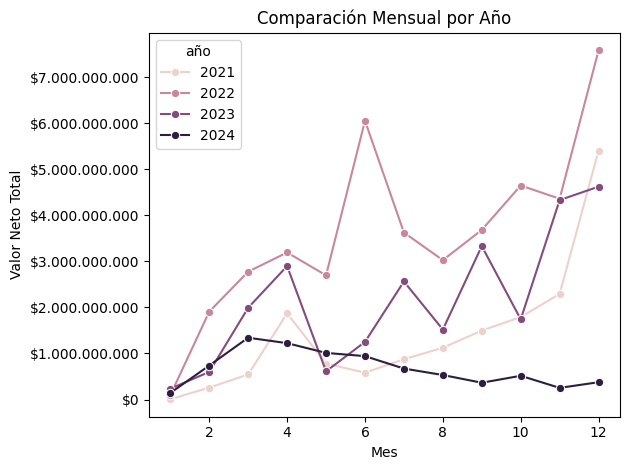

In [44]:
fig, ax = plt.subplots()

def formato_moneda(x, _):
  return f"${x:,.0f}".replace(",", ".")

ax.yaxis.set_major_formatter(mtick.FuncFormatter(formato_moneda))

sns.lineplot(data=giro_mes, x="mes", y="Valor neto total", hue="año", marker="o")

plt.title("Comparación Mensual por Año")
plt.xlabel("Mes")
plt.ylabel("Valor Neto Total")

plt.tight_layout()
plt.show()

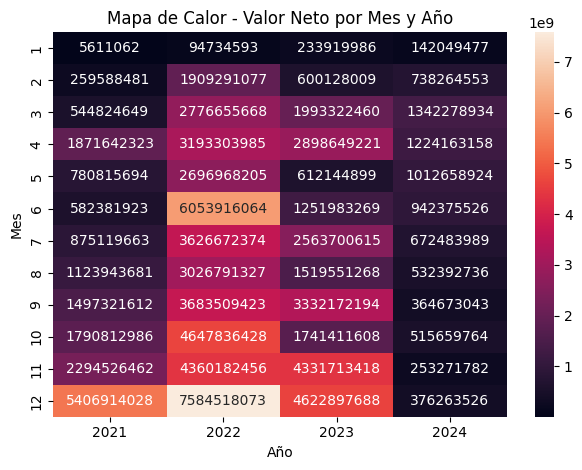

In [45]:
pivot = giro_mes.pivot(index="mes", columns="año", values="Valor neto total")

plt.figure()
sns.heatmap(pivot, annot=True, fmt=".0f")

plt.title("Mapa de Calor - Valor Neto por Mes y Año")
plt.xlabel("Año")
plt.ylabel("Mes")

plt.tight_layout()
plt.show()

In [46]:
giro_mes.pivot(index="mes", columns="año", values="Valor neto total")


año,2021,2022,2023,2024
mes,,,,
1,5611062,94734593,233919986,142049477
2,259588481,1909291077,600128009,738264553
3,544824649,2776655668,1993322460,1342278934
4,1871642323,3193303985,2898649221,1224163158
5,780815694,2696968205,612144899,1012658924
6,582381923,6053916064,1251983269,942375526
7,875119663,3626672374,2563700615,672483989
8,1123943681,3026791327,1519551268,532392736
9,1497321612,3683509423,3332172194,364673043


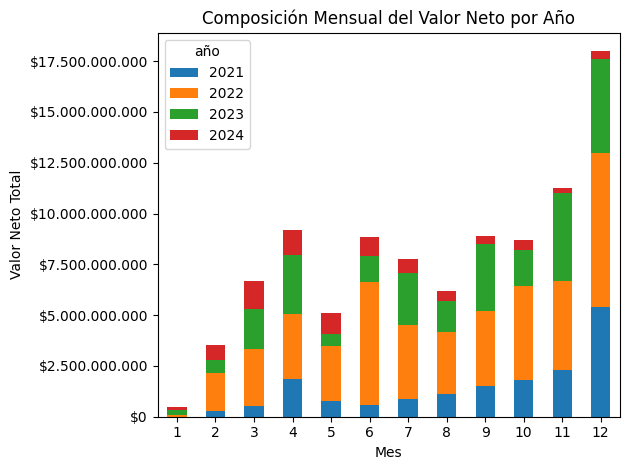

In [47]:
fig, ax = plt.subplots()

pivot.plot(kind="bar", stacked=True, ax = ax)

def formato_moneda(x, _):
  return f"${x:,.0f}".replace(",", ".")

ax.yaxis.set_major_formatter(mtick.FuncFormatter(formato_moneda))

plt.title("Composición Mensual del Valor Neto por Año")
plt.xlabel("Mes")
plt.ylabel("Valor Neto Total")

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

#### ✅ Selección de muestra atípica para futuro análisis

En base a estos valores atípicos se procede a extraer los datos de estos periodos de tiempo y guardarlos en un DataFrame para posterior análisis en detalle.

In [48]:
parejas = [
    (2021, 4),
    (2021, 12),
    (2022, 6),
    (2022, 12),
    (2023, 4),
    (2023, 7),
    (2023, 9),
    (2023, 11),
    (2023, 12)
]

df_parejas = pd.DataFrame(parejas, columns=['año', 'mes'])
df_parejas

,año,mes
0,2021,4
1,2021,12
2,2022,6
3,2022,12
4,2023,4
5,2023,7
6,2023,9
7,2023,11
8,2023,12


In [49]:
df_alerta = df.merge(df_parejas, on=['año', 'mes'], how='inner')
df_alerta

,Vigencia,Número de orden de pago,ID_Tercero,Fecha Giro,Número de cuenta,Banco,Razon_Social,Tipo de persona,Tipo de gasto,Fecha CRP,...,Adulto mayor,Otros descuentos,Total descuentos,Valor Neto,Cuenta contable,Credito,ID_Soporte,id_unico,año,mes
0,2021,3582,25164277,2021-04-13,24513984181,BANCO CAJA SOCIAL S.A.,MARIA EUGENIA RAMIREZ OSORIO,NATURAL,SERVICIOS,2021-06-21,...,50000.0,0.0,84911.0,2415089,1110,2415089,3582,3582_25164277_,2021,4
1,2021,3584,1006295849,2021-04-13,3007669107,BANCOLOMBIA S A,CLAUDIA PATRICIA GONZALEZ GONZALEZ,NATURAL,SERVICIOS,2021-06-18,...,37500.0,0.0,63036.0,1811964,1110,1811964,3584,3584_1006295849_,2021,4
2,2021,3589,1110474405,2021-04-14,453179244,BANCO BILBAO VIZCAYA ARGENTARIA COLOMBIA S A,HAROLD JOHANNY ARANGO BUENAVENTURA,NATURAL,SERVICIOS,2021-06-18,...,50000.0,0.0,84650.0,2415350,1110,2415350,3589,3589_1110474405_,2021,4
3,2021,3590,6767712,2021-04-14,24098964215,BANCO CAJA SOCIAL S.A.,JOSE FERNANDO RAMIREZ PULIDO,NATURAL,SERVICIOS,2021-06-18,...,100000.0,0.0,133860.0,4866140,1110,4866140,3590,3590_6767712_,2021,4
4,2021,3591,79864985,2021-04-14,69529683553,BANCOLOMBIA S A,EDWUARD ANDRES REYES ALVARADO,NATURAL,SERVICIOS,2021-06-17,...,100000.0,0.0,133860.0,4866140,1110,4866140,3591,3591_79864985_,2021,4
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5633,2023,9747,79955134,2023-12-29,18011784999,BANCOLOMBIA S A,JOHN WALTHER RUBIO NARANJO,NATURAL,SERVICIOS,2023-05-10,...,0.0,0.0,40316.0,1429965,1110,1429965,9747,9747_79955134_,2023,12
5634,2023,9748,1026591864,2023-12-29,24109396077,BANCO CAJA SOCIAL S.A.,ANDRES FELIPE PAEZ USTARIZ,NATURAL,SERVICIOS,2023-11-10,...,0.0,0.0,136355.0,4274489,1110,4274489,9748,9748_1026591864_,2023,12
5635,2023,9749,1022434463,2023-12-29,302098686,BANCO DE BOGOTA,JOSE DAVID OVALLE FERNANDEZ,NATURAL,SERVICIOS,2023-11-14,...,0.0,0.0,136355.0,4274489,1110,4274489,9749,9749_1022434463_,2023,12
5636,2023,9750,91012881,2023-12-29,5100103133,BANCO DAVIVIENDA S.A.,FLORINDO COY COY,NATURAL,SERVICIOS,2023-09-22,...,0.0,0.0,145431.0,4612761,1110,4612761,9750,9750_91012881_,2023,12


### Distribución de montos

Se observan distribuciones muy sesgadas con colas muy largas a la derecha, lo que sugiere pocos pagos muy altos y un alto riesgo de concentración. Esto demuestra giros muy por encima del rango normal. Sugiere realizar una revisión individual a los pagos con estos montos.

Los giros muestran una alta disperción lo que sugiere una falta de control o estandarización.

Se observa un pico para ambas distribuciones en montos pequeños.

#### Histograma de Valor Bruto

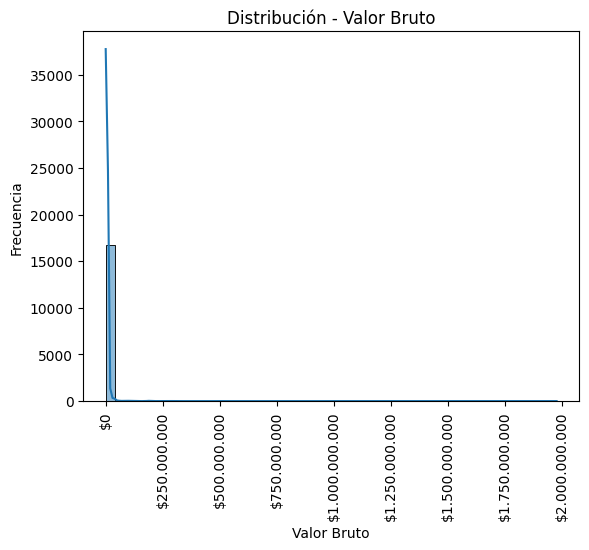

In [50]:
fig, ax = plt.subplots()

def formato_moneda(x, _):
  return f"${x:,.0f}".replace(",", ".")

ax.xaxis.set_major_formatter(mtick.FuncFormatter(formato_moneda))

sns.histplot(data=df, x = "Valor Bruto", bins = 50, kde = True)

plt.title("Distribución - Valor Bruto")
plt.xlabel("Valor Bruto")
plt.ylabel("Frecuencia")
plt.xticks(rotation=90)
plt.show()

#### Histograma de Valor Neto

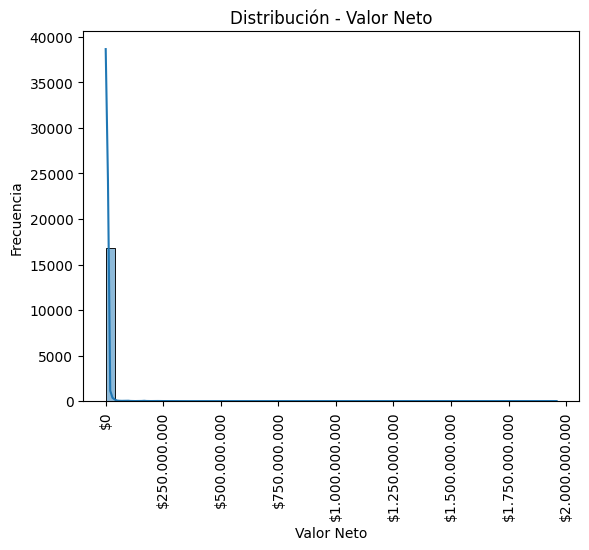

In [51]:
fig, ax = plt.subplots()

def formato_moneda(x, _):
  return f"${x:,.0f}".replace(",", ".")

ax.xaxis.set_major_formatter(mtick.FuncFormatter(formato_moneda))

sns.histplot(data = df, x = "Valor Neto", bins=50, kde=True)

plt.title("Distribución - Valor Neto")
plt.xlabel("Valor Neto")
plt.xticks(rotation=90)
plt.ylabel("Frecuencia")

plt.show()

#### 🚨 Alerta

Se observa que el 4.82% de los giros (aquellos superiores a 10 millones de pesos) concentran el 42.50% del valor bruto total, evidenciando una alta concentración del gasto público en un número reducido de operaciones, lo cual constituye un punto crítico de control y análisis en el proceso de auditoría.

C:\Users\DVadeus\AppData\Local\Temp\ipykernel_10300\1058063289.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=categorias, y=valores_c, ax=axes[0], palette = colors)


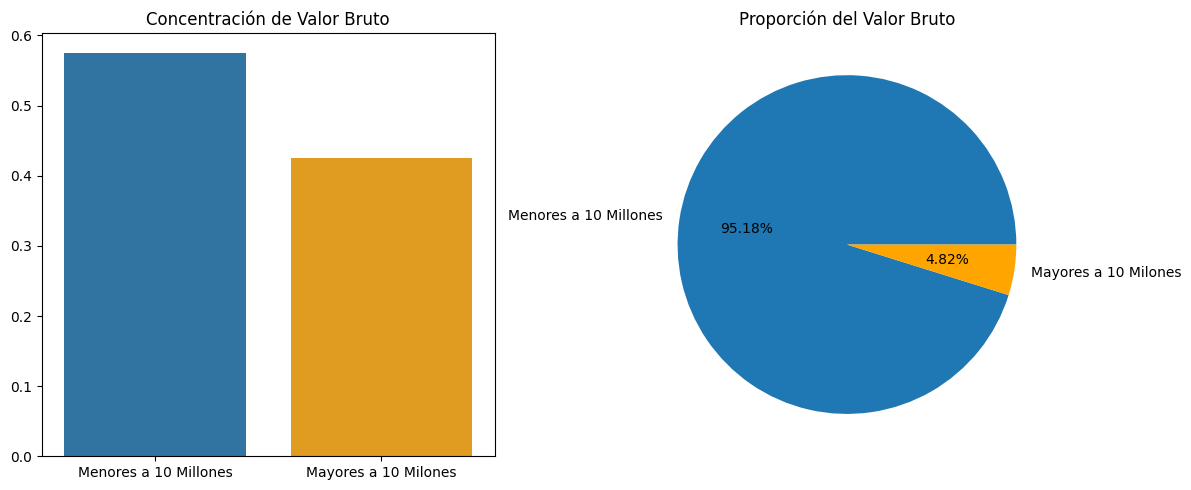

In [52]:
concentrancion = df[df["Valor Bruto"] > 10_000_000]["Valor Bruto"].sum() / df["Valor Bruto"].sum()
proporcion = df[df["Valor Bruto"] > 10_000_000]["Valor Bruto"].count() / df["Valor Bruto"].count()

categorias = ['Menores a 10 Millones', 'Mayores a 10 Milones']
valores_c = [1 - concentrancion, concentrancion]
valores_p = [1 - proporcion, proporcion]

colors = ["#1f77b4", "#FFA500"]

fig, axes = plt.subplots(1, 2, figsize=(12, 5))


sns.barplot(x=categorias, y=valores_c, ax=axes[0], palette = colors)
axes[0].set_title("Concentración de Valor Bruto")

axes[1].pie(valores_p, labels=categorias, autopct='%1.2f%%', colors = colors)
axes[1].set_title("Proporción del Valor Bruto")

plt.tight_layout()

plt.show()

In [53]:
print(f"Giros de más de 10 millones: {df[df["Valor Bruto"] > 10_000_000]["Valor Bruto"].count()}")

Giros de más de 10 millones: 815


#### Boxplot Tipo de Gasto

Se presentan una gran cantidad de valores atípicos en los tipos de gasto ``"Servicios"`` y ``"Contrato"``

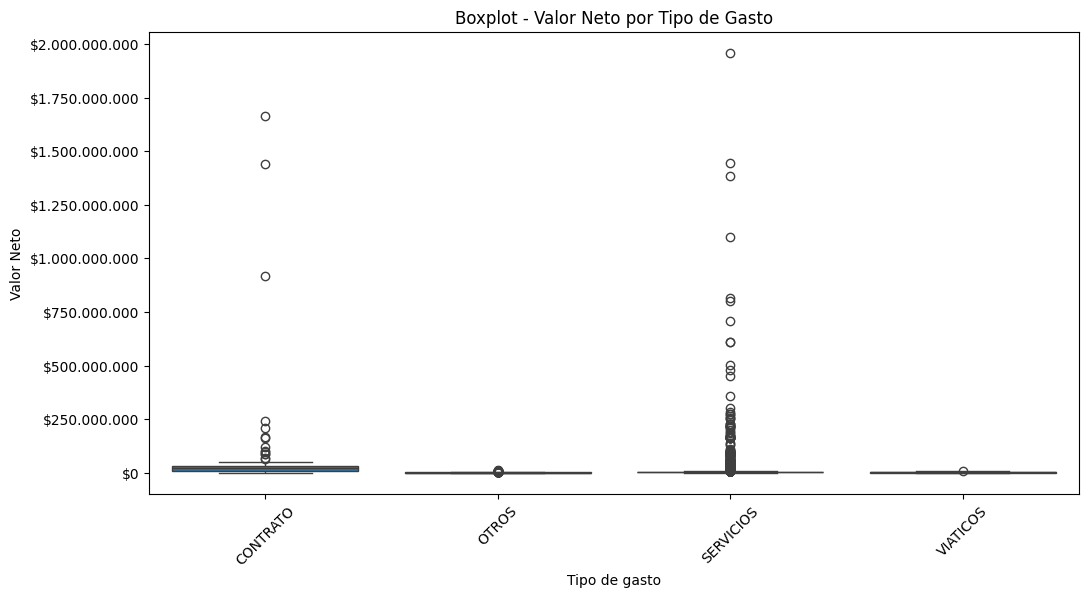

In [54]:
fig,ax = plt.subplots(figsize=(12,6))

def formato_moneda(x, _):
  return f"${x:,.0f}".replace(",", ".")

ax.yaxis.set_major_formatter(mtick.FuncFormatter(formato_moneda))

sns.boxplot(data=df, x = "Tipo de gasto", y = "Valor Neto")
plt.xticks(rotation=45)
plt.title("Boxplot - Valor Neto por Tipo de Gasto")
plt.xlabel("Tipo de gasto")
plt.ylabel("Valor Neto")

plt.show()

#### Boxplot Banco

Se presentan una gran cantidad de valores atípicos en los bancos ``"Bancolombia"``, ``"BBVA"``, ``"Banco de Occidente"``, ``"Banco de Bogotá"`` y ``"Citibank"``

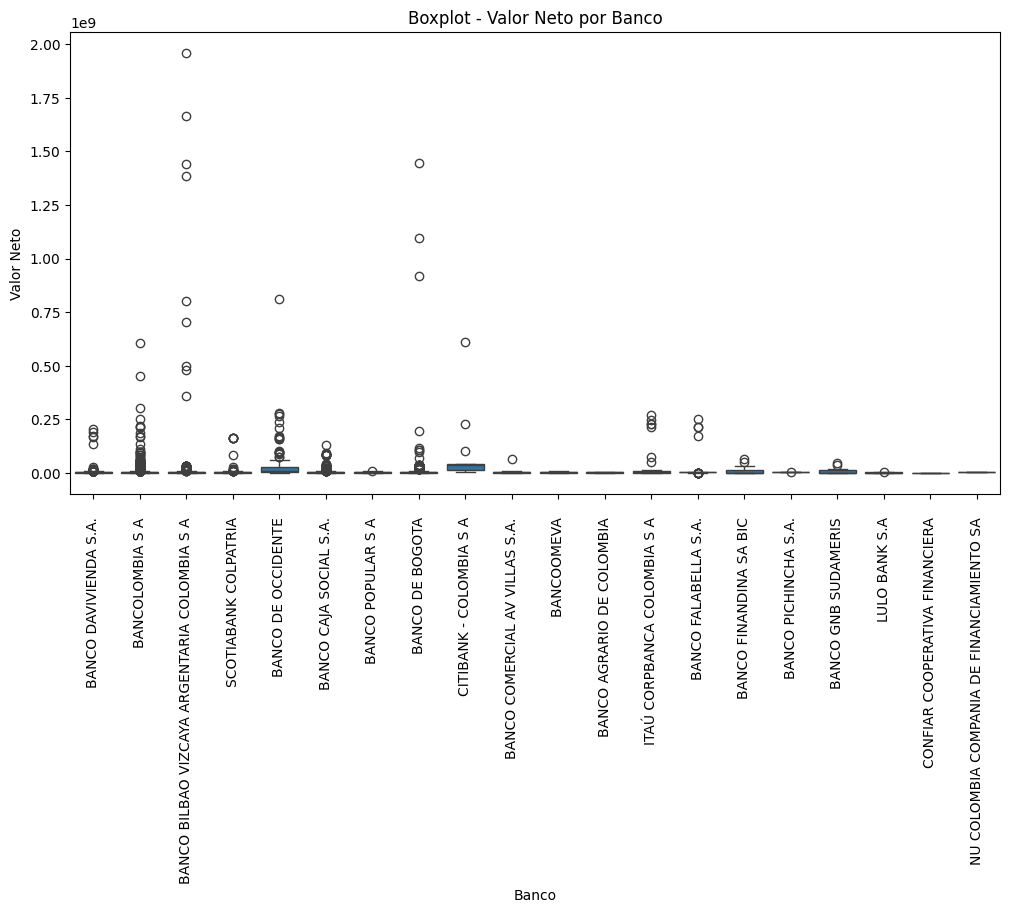

In [55]:
plt.figure(figsize=(12,6))
sns.boxplot(data=df, x="Banco", y="Valor Neto")

plt.xticks(rotation=90)
plt.title("Boxplot - Valor Neto por Banco")
plt.xlabel("Banco")
plt.ylabel("Valor Neto")

plt.show()

#### Extracción de outliers por banco

Utilizando el método estándar (IQR) mediante:
$$
valor<Q1−1.5∗ IQR \hspace{10pt} {o} \hspace{10pt} valor > Q3 + 1.5 ∗ IQR
$$

In [56]:
def detectar_outliers_por_grupo(df, grupo_col, valor_col) -> pd.DataFrame:

    outliers_list = []

    for grupo, data in df.groupby(grupo_col):

        Q1 = data[valor_col].quantile(0.25)
        Q3 = data[valor_col].quantile(0.75)
        IQR = Q3 - Q1

        lower_bound = Q1 - 1.5 * IQR
        upper_bound = Q3 + 1.5 * IQR

        outliers = data[
            (data[valor_col] < lower_bound) |
            (data[valor_col] > upper_bound)
        ]

        outliers_list.append(outliers)

    return pd.concat(outliers_list)

In [57]:
outliers_banco = detectar_outliers_por_grupo(
    df,
    grupo_col="Banco",
    valor_col="Valor Neto"
)

outliers_banco.head(40)

,Vigencia,Número de orden de pago,ID_Tercero,Fecha Giro,Número de cuenta,Banco,Razon_Social,Tipo de persona,Tipo de gasto,Fecha CRP,...,Adulto mayor,Otros descuentos,Total descuentos,Valor Neto,Cuenta contable,Credito,ID_Soporte,id_unico,año,mes
512,2021,946,28627633,2021-06-10,807039771,BANCO BILBAO VIZCAYA ARGENTARIA COLOMBIA S A,MAGDA CRISTINA MONTAÑA MURILLO,NATURAL,SERVICIOS,2021-04-12,...,232820.0,0.0,1474049.0,12378741,1110,12378741,946,946_28627633_,2021,6
617,2021,1406,28627633,2021-07-09,807039771,BANCO BILBAO VIZCAYA ARGENTARIA COLOMBIA S A,MAGDA CRISTINA MONTAÑA MURILLO,NATURAL,SERVICIOS,2021-04-12,...,232820.0,0.0,1355407.0,12497383,1110,12497383,1406,1406_28627633_,2021,7
843,2021,2050,28627633,2021-08-10,807039771,BANCO BILBAO VIZCAYA ARGENTARIA COLOMBIA S A,MAGDA CRISTINA MONTAÑA MURILLO,NATURAL,SERVICIOS,2021-04-12,...,232820.0,0.0,1355407.0,12497383,1110,12497383,2050,2050_28627633_,2021,8
1045,2021,2395,28627633,2021-09-02,807039771,BANCO BILBAO VIZCAYA ARGENTARIA COLOMBIA S A,MAGDA CRISTINA MONTAÑA MURILLO,NATURAL,SERVICIOS,2021-04-12,...,232820.0,0.0,1355407.0,12497383,1110,12497383,2395,2395_28627633_,2021,9
1508,2021,3402,41520944,2021-10-08,138121710,BANCO BILBAO VIZCAYA ARGENTARIA COLOMBIA S A,MARTHA LUCIA FERNANDEZ SARMIENTO,NATURAL,SERVICIOS,2021-05-20,...,689824.0,0.0,5627587.0,35416964,1110,35416964,3402,3402_41520944_,2021,10
1606,2021,3607,28627633,2021-10-12,807039771,BANCO BILBAO VIZCAYA ARGENTARIA COLOMBIA S A,MAGDA CRISTINA MONTAÑA MURILLO,NATURAL,SERVICIOS,2021-04-12,...,232820.0,0.0,1355407.0,12497383,1110,12497383,3607,3607_28627633_,2021,10
1782,2021,3865,41520944,2021-10-27,138121710,BANCO BILBAO VIZCAYA ARGENTARIA COLOMBIA S A,MARTHA LUCIA FERNANDEZ SARMIENTO,NATURAL,SERVICIOS,2021-05-20,...,579501.0,0.0,4727568.0,29752730,1110,29752730,3865,3865_41520944_,2021,10
1801,2021,3884,41520944,2021-10-27,138121710,BANCO BILBAO VIZCAYA ARGENTARIA COLOMBIA S A,MARTHA LUCIA FERNANDEZ SARMIENTO,NATURAL,SERVICIOS,2021-05-20,...,543131.0,0.0,4430860.0,27885408,1110,27885408,3884,3884_41520944_,2021,10
1983,2021,4349,28627633,2021-11-09,807039771,BANCO BILBAO VIZCAYA ARGENTARIA COLOMBIA S A,MAGDA CRISTINA MONTAÑA MURILLO,NATURAL,SERVICIOS,2021-04-12,...,232820.0,0.0,1355408.0,12497382,1110,12497382,4349,4349_28627633_,2021,11
1994,2021,4376,41520944,2021-11-10,138121710,BANCO BILBAO VIZCAYA ARGENTARIA COLOMBIA S A,MARTHA LUCIA FERNANDEZ SARMIENTO,NATURAL,SERVICIOS,2021-05-20,...,484938.0,0.0,3943008.0,24910803,1110,24910803,4376,4376_41520944_,2021,11


#### Extracción de muestra por Banco

#### ✅ Agregar dataframe a lista de outliers

In [58]:
lista_outliers.append(outliers_banco)

#### Extracción de outliers por Tipo de Gasto

In [59]:
outliers_tipo_gasto = detectar_outliers_por_grupo(
    df,
    grupo_col="Tipo de gasto",
    valor_col="Valor Neto"
)

outliers_tipo_gasto.head(60)

C:\Users\DVadeus\AppData\Local\Temp\ipykernel_10300\2489942074.py:5: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  for grupo, data in df.groupby(grupo_col):


,Vigencia,Número de orden de pago,ID_Tercero,Fecha Giro,Número de cuenta,Banco,Razon_Social,Tipo de persona,Tipo de gasto,Fecha CRP,...,Adulto mayor,Otros descuentos,Total descuentos,Valor Neto,Cuenta contable,Credito,ID_Soporte,id_unico,año,mes
3686,2022,7660,900292243,2022-03-17,4751000060,SCOTIABANK COLPATRIA,ISATECH CORPORATION S.A.S,JURIDICA,CONTRATO,2022-01-20,...,3206316.0,0.0,27760281.0,163015503,1110,163015503,7660,7660_900292243_,2022,3
3699,2022,7675,900431030,2022-03-17,805163078,BANCO COMERCIAL AV VILLAS S.A.,INGENIERIAS Y CONSTRUCCIONES NISSI S.A.S.,JURIDICA,CONTRATO,2022-03-17,...,1299323.0,0.0,11249538.0,66060177,1110,66060177,7675,7675_900431030_,2022,3
3748,2022,7758,830047444,2022-04-13,61003099895,BANCOLOMBIA S A,SERVICIOS ESPECIALIZADOS DE TECNOLOGÍA E INFOR...,JURIDICA,CONTRATO,2022-07-27,...,1774593.0,0.0,2830476.0,85899190,1110,85899190,7758,7758_830047444_,2022,4
3816,2022,7939,830047444,2022-05-23,61003099895,BANCOLOMBIA S A,SERVICIOS ESPECIALIZADOS DE TECNOLOGÍA E INFOR...,JURIDICA,CONTRATO,2022-07-27,...,1784650.0,0.0,2846516.0,86385968,1110,86385968,7939,7939_830047444_,2022,5
4726,2022,1772,830122983,2022-05-24,184150,BANCO DE BOGOTA,ESRI COLOMBIA S.A.S,JURIDICA,CONTRATO,2022-03-15,...,19001855.0,0.0,32930215.0,917162557,1110,917162557,1772,1772_830122983_,2022,5
5069,2022,2482,901023218,2022-06-16,833025943,BANCO BILBAO VIZCAYA ARGENTARIA COLOMBIA S A,HQ5 SAS,JURIDICA,CONTRATO,2022-02-26,...,0.0,0.0,0.0,1439307910,1110,1439307910,2482,2482_901023218_,2022,6
5359,2022,3313,901023218,2022-07-29,833025943,BANCO BILBAO VIZCAYA ARGENTARIA COLOMBIA S A,HQ5 SAS,JURIDICA,CONTRATO,2022-02-26,...,3232922.0,0.0,16004401.0,1663963717,1110,1663963717,3313,3313_901023218_,2022,7
8752,2022,8473,900391059,2022-11-16,405089921,BANCO DE OCCIDENTE,QUINTA GENERACIÓN S.A.S,JURIDICA,CONTRATO,2022-06-14,...,2175331.0,0.0,9316942.0,99449590,1110,99449590,8473,8473_900391059_,2022,11
9015,2022,8825,901542513,2022-12-01,678532,BANCO DE BOGOTA,UNION TEMPORAL SOAIN THINK IT,JURIDICA,CONTRATO,2022-09-09,...,1553417.0,0.0,6264931.0,71405931,1110,71405931,8825,8825_901542513_,2022,12
9016,2022,8826,901542513,2022-12-01,678532,BANCO DE BOGOTA,UNION TEMPORAL SOAIN THINK IT,JURIDICA,CONTRATO,2022-09-09,...,2591345.0,0.0,10450895.0,119116357,1110,119116357,8826,8826_901542513_,2022,12


#### ✅ Agregar dataframe a la lista de outliers

In [60]:
lista_outliers.append(outliers_tipo_gasto)

### Top Actores

Se procede a realizar un análsis de los beneficiarios, para efectos de obtener una mejor distribución de los datos a analizar se dividirá el análisis por ``Tipo de Persona``.

In [61]:
set(df["Tipo de persona"])

{'JURIDICA', 'NATURAL'}

#### Por Beneficiario

🚨 Revisando la concentración de giros por beneficiario se encuentra unos montos considerablemente altos a pocas empresas como a personas naturales, por lo que se realizará un análisis de detección estadística por medio de Z-Score y Feature Engineering

In [62]:
df_juridico = df[df["Tipo de persona"] == "JURIDICA"]

df_natural = df[df["Tipo de persona"] == "NATURAL"]

In [63]:
df_juridico

,Vigencia,Número de orden de pago,ID_Tercero,Fecha Giro,Número de cuenta,Banco,Razon_Social,Tipo de persona,Tipo de gasto,Fecha CRP,...,Adulto mayor,Otros descuentos,Total descuentos,Valor Neto,Cuenta contable,Credito,ID_Soporte,id_unico,año,mes
66,2021,3438,800103052,2021-03-12,5063182011,CITIBANK - COLOMBIA S A,ORACLE COLOMBIA LTDA,JURIDICA,SERVICIOS,2021-05-13,...,180099.0,0.0,312112.0,10403795,1110,10403795,3438,3438_800103052_,2021,3
110,2021,3551,800103052,2021-03-23,5063182011,CITIBANK - COLOMBIA S A,ORACLE COLOMBIA LTDA,JURIDICA,SERVICIOS,2021-05-13,...,146624.0,0.0,254099.0,8470012,1110,8470012,3551,3551_800103052_,2021,3
111,2021,3552,860002184,2021-03-23,121072874,SCOTIABANK COLPATRIA,AXA COLPATRIA SEGUROS S.A.,JURIDICA,SERVICIOS,2021-05-12,...,390425.0,0.0,703546.0,18817706,1110,18817706,3552,3552_860002184_,2021,3
157,2021,3767,800103052,2021-05-21,5063182011,CITIBANK - COLOMBIA S A,ORACLE COLOMBIA LTDA,JURIDICA,SERVICIOS,2021-05-13,...,1751502.0,0.0,3035352.0,101179006,1110,101179006,3767,3767_800103052_,2021,5
158,2021,3785,830505521,2021-05-25,291014785,BANCO DE OCCIDENTE,SOLUCIONES TECNOLOGIA Y SERVICIOS S.A. STS S.A...,JURIDICA,SERVICIOS,2021-06-23,...,5004807.0,0.0,24563593.0,266862527,1110,266862527,3785,3785_830505521_,2021,5
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
16808,2024,3781,830118348,2024-11-26,4969998238,BANCO DAVIVIENDA S.A.,UNIPAR ALQUILERES DE COMPUTADORES S A,JURIDICA,SERVICIOS,2024-05-30,...,12435.0,0.0,70980.0,668922,1110,668922,3781,3781_830118348_,2024,11
16840,2024,4111,890400048,2024-12-12,50450127135,BANCOLOMBIA S A,ARAUJO & SEGOVIA S.A.,JURIDICA,CONTRATO,2024-03-01,...,463347.0,0.0,2305153.0,25264005,1110,25264005,4111,4111_890400048_,2024,12
16890,2024,4603,901677477,2024-12-27,9600301361,BANCO DAVIVIENDA S.A.,UNION TEMPORAL R&J 2022,JURIDICA,SERVICIOS,2024-04-26,...,10232.0,0.0,45532.0,5679170,1110,5679170,4603,4603_901677477_,2024,12
16891,2024,4604,901677477,2024-12-27,9600301361,BANCO DAVIVIENDA S.A.,UNION TEMPORAL R&J 2022,JURIDICA,SERVICIOS,2024-04-26,...,33124.0,0.0,112772.0,1572018,1110,1572018,4604,4604_901677477_,2024,12


In [64]:
df_natural

,Vigencia,Número de orden de pago,ID_Tercero,Fecha Giro,Número de cuenta,Banco,Razon_Social,Tipo de persona,Tipo de gasto,Fecha CRP,...,Adulto mayor,Otros descuentos,Total descuentos,Valor Neto,Cuenta contable,Credito,ID_Soporte,id_unico,año,mes
0,2021,2991,1088259568,2021-02-03,127270151591,BANCO DAVIVIENDA S.A.,YONNY ANDRES CRUZ BENJUMEA,NATURAL,SERVICIOS,2021-04-26,...,37500.0,0.0,63022.0,1499478,1110,1499478,2991,2991_1088259568_,2021,2
1,2021,2992,1088259568,2021-02-03,127270151591,BANCO DAVIVIENDA S.A.,YONNY ANDRES CRUZ BENJUMEA,NATURAL,SERVICIOS,2021-06-21,...,0.0,0.0,0.0,312500,1110,312500,2992,2992_1088259568_,2021,2
2,2021,3001,52539367,2021-02-04,570008870331215,BANCO DAVIVIENDA S.A.,ALEXANDRA VARGAS PINILLA,NATURAL,SERVICIOS,2021-05-12,...,156740.0,0.0,546214.0,7290786,1110,7290786,3001,3001_52539367_,2021,2
3,2021,3047,1094938732,2021-02-08,120237187,BANCOLOMBIA S A,MARIA ALEJANDRA LONDOÑO JIMENEZ,NATURAL,SERVICIOS,2021-06-21,...,30000.0,0.0,52500.0,1447500,1110,1447500,3047,3047_1094938732_,2021,2
4,2021,3053,1093773164,2021-02-08,570457370201248,BANCO DAVIVIENDA S.A.,JURGEN DANIEL TOLOZA DELGADO,NATURAL,SERVICIOS,2021-06-03,...,109680.0,0.0,341099.0,6184861,1110,6184861,3053,3053_1093773164_,2021,2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
16895,2024,4624,1113512793,2024-12-28,85821640704,BANCOLOMBIA S A,MARY YULIANA JARAMILLO,NATURAL,SERVICIOS,2024-02-01,...,138942.0,0.0,189766.0,6757313,1110,6757313,4624,4624_1113512793_,2024,12
16896,2024,4640,1143338180,2024-12-29,78800010080,BANCOLOMBIA S A,YELIZA MERCEDES PEREZ LICONA,NATURAL,SERVICIOS,2024-02-01,...,54033.0,0.0,73423.0,2628219,1110,2628219,4640,4640_1143338180_,2024,12
16897,2024,4641,1047368991,2024-12-29,56600181756,BANCO DAVIVIENDA S.A.,LUISA FERNANDA LARIOS DIAZ,NATURAL,SERVICIOS,2024-01-29,...,54033.0,0.0,74534.0,2627108,1110,2627108,4641,4641_1047368991_,2024,12
16898,2024,4653,64564800,2024-12-30,57700132848,BANCO DAVIVIENDA S.A.,SALMA ELENA CALDAS OTERO,NATURAL,SERVICIOS,2024-02-01,...,0.0,0.0,0.0,2,1110,2,4653,4653_64564800_,2024,12


##### Jurídico

In [65]:
juridico = df_juridico.groupby("Razon_Social")["Valor Neto"].sum().reset_index(name = 'Valor neto total').sort_values(by="Valor neto total", ascending = False)
juridico

,Razon_Social,Valor neto total
35,HQ5 SAS,9297260925
30,ESRI COLOMBIA S.A.S,3523222901
42,QUINTA GENERACIÓN S.A.S,2838962107
13,CHALJUB RESTREPO & CIA S.C.A.,2084653726
7,BUSINESSMIND COLOMBIA S.A.,1579869727
...,...,...
17,COMUNICACION CELULAR S A COMCEL S A,2025046
47,SERVIRED LMA COMUNICACIONES S.A.S.,1180619
0,A Y A RADIOCOMUNICACIONES S.A.S,880000
25,EMPRESA DE ACUEDUCTO Y ALCANTARILLADO DE PEREI...,697020


In [66]:
df_benef_j = df_juridico.groupby("Razon_Social").agg(
    Valor_Neto_Total = ('Valor Neto', 'sum'),
    Cantidad = ('Valor Neto', 'count'),
    Promedio = ('Valor Neto', 'mean')
).sort_values(by = "Valor_Neto_Total", ascending = False)
df_benef_j

,Valor_Neto_Total,Cantidad,Promedio
Razon_Social,,,
HQ5 SAS,9297260925,10,9.297261e+08
ESRI COLOMBIA S.A.S,3523222901,5,7.046446e+08
QUINTA GENERACIÓN S.A.S,2838962107,33,8.602915e+07
CHALJUB RESTREPO & CIA S.C.A.,2084653726,79,2.638802e+07
BUSINESSMIND COLOMBIA S.A.,1579869727,4,3.949674e+08
...,...,...,...
COMUNICACION CELULAR S A COMCEL S A,2025046,28,7.232307e+04
SERVIRED LMA COMUNICACIONES S.A.S.,1180619,4,2.951548e+05
A Y A RADIOCOMUNICACIONES S.A.S,880000,2,4.400000e+05


#### Evaluación de impacto del top 10 jurídicos

Se evidencia una concentración del 25.44% del `Valor_Neto` en 10 Terceros de tipo `Jurídico`.

Esto da evidencia a una dependencia excesiva. Pudiendo llegar a ser riesgoso a largo plazo.

In [67]:
valor_top_10 = df_benef_j.head(10)["Valor_Neto_Total"].sum().item()
valor_neto_total = df["Valor Neto"].sum().item()

format(valor_top_10/valor_neto_total, ".2%")

'25.44%'

In [68]:
top_10 = df_benef_j.head(10).index.to_list()
top_10 = df[df["Razon_Social"].isin(top_10)]
top_10["Año"] = top_10["Fecha Giro"].dt.year
top_10.groupby(["Razon_Social","Año"]).agg(
    Valor_Neto = ("Valor Neto", "sum")
).reset_index().sort_values(by="Valor_Neto", ascending = False)

C:\Users\DVadeus\AppData\Local\Temp\ipykernel_10300\506765359.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  top_10["Año"] = top_10["Fecha Giro"].dt.year


,Razon_Social,Año,Valor_Neto
14,HQ5 SAS,2022,8436233937
18,QUINTA GENERACIÓN S.A.S,2022,2513818736
2,BUSINESSMIND COLOMBIA S.A.,2023,1579869727
9,ESRI COLOMBIA S.A.S,2021,1446801300
11,ESRI COLOMBIA S.A.S,2023,1098378966
10,ESRI COLOMBIA S.A.S,2022,939807923
4,CHALJUB RESTREPO & CIA S.C.A.,2022,926702392
13,HQ5 SAS,2021,861026988
8,COMWARE S. A.,2024,823912624
25,SERVICIOS POSTALES NACIONALES S A,2022,813074946


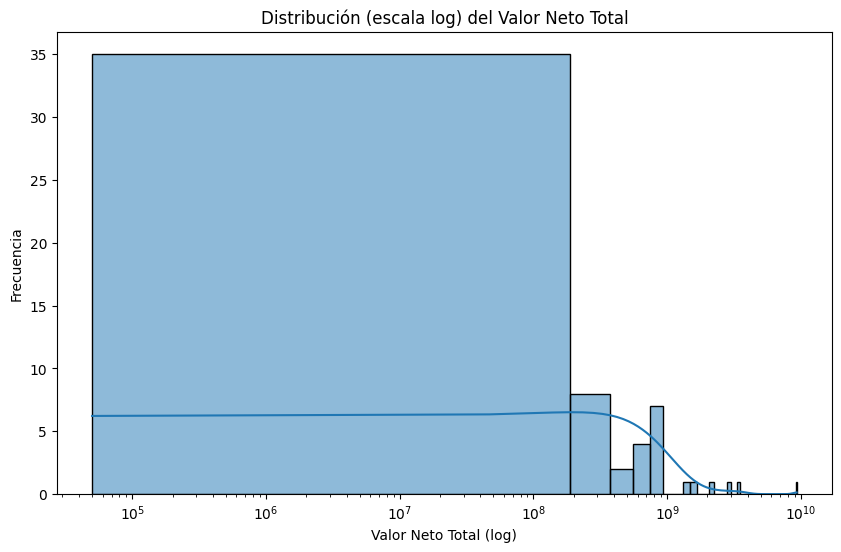

In [69]:
plt.figure(figsize=(10,6))
sns.histplot(data = df_benef_j, x = "Valor_Neto_Total", bins=50, kde=True)
plt.xscale("log")

plt.title("Distribución (escala log) del Valor Neto Total")
plt.xlabel("Valor Neto Total (log)")
plt.ylabel("Frecuencia")

plt.show()

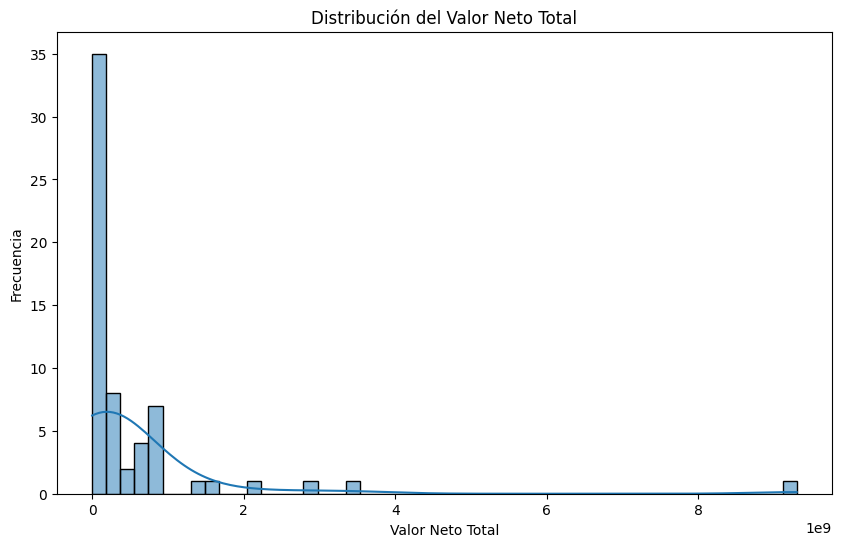

In [70]:
plt.figure(figsize=(10,6))
sns.histplot(data = df_benef_j, x = "Valor_Neto_Total", bins=50, kde=True)
plt.xscale("linear")

plt.title("Distribución del Valor Neto Total")
plt.xlabel("Valor Neto Total")
plt.ylabel("Frecuencia")

plt.show()

#### ⚠️ Por revisar

Se observa mediante el gráfico de Histógrama en escala logarítmica que la mayoría de los beneficiarios están en valores relativamente bajos. Y que unos pocos beneficiarios concentran montos muy grandes.

Se observa una distribución más extrema que Pareto, posiblemente:

- 5-10 % beneficiarios concentran el 70-90% del dinero

Lo que podría indicar contratistas dominantes o concentración indebida

Además, se encuentran anomalías extremas que llegan incluso a $10^{10}$

#### Cálculo del coeficiente de Gini

In [71]:
def gini(array):
    array = np.array(array)

    # Evitar negativos o ceros problemáticos
    array = array[array >= 0]

    if np.amin(array) == 0:
        array = array + 1e-9  # evitar división por cero

    array = np.sort(array)
    n = len(array)

    index = np.arange(1, n + 1)

    return (np.sum((2 * index - n - 1) * array)) / (n * np.sum(array))

In [72]:
gini_valor = gini(df_benef_j["Valor_Neto_Total"])
print(f"Gini: {gini_valor:.4f}")

Gini: 0.7592


El cálculo del coeficiente de Gini mide la desigualdad de los datos. Siendo:
- 0 = Distribución perfecta de igualdad
- 1 = Máxima desigualdad

Con un resultado de ``0.7592`` se observa una **muy alta concentración de desigualdad**

#### Curva de Lorenz

In [73]:
def curva_lorenz(valores, x_ref, y_ref):
    valores = np.sort(valores)
    acumulado = np.cumsum(valores)
    acumulado = np.insert(acumulado, 0, 0)
    acumulado = acumulado / acumulado[-1]

    x = np.linspace(0, 1, len(acumulado))

    plt.figure(figsize=(6,6))
    plt.plot(x, acumulado, label="Curva de Lorenz")
    plt.plot([0,1], [0,1], linestyle='--', label="Igualdad perfecta")

    x_ref = x_ref
    y_ref = y_ref

    plt.axvline(x = x_ref, linestyle='--')
    plt.axhline(y = y_ref, linestyle='--')

    plt.scatter(x_ref, y_ref)

    plt.title("Curva de Lorenz - Distribución de Pagos")
    plt.xlabel("Proporción de beneficiarios")
    plt.ylabel("Proporción del valor acumulado")
    plt.legend()

    plt.show()

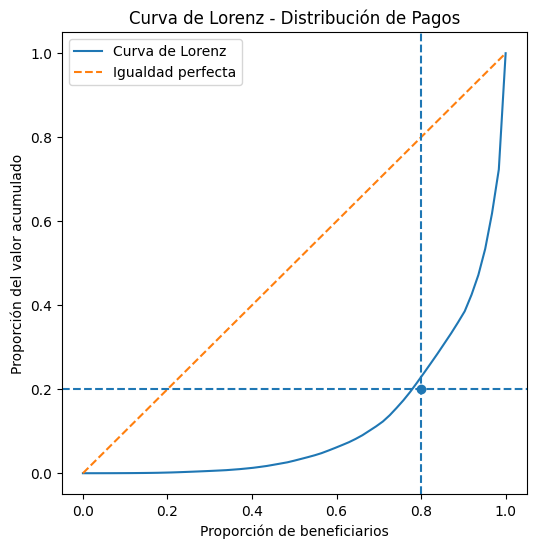

In [74]:
curva_lorenz(df_benef_j["Valor_Neto_Total"], 0.8, 0.2)

Según la curva de Lorenz, observamos que la mayoría de los beneficiarios reciben muy poco del total de giros tesorales. Por lo que el dinero se acomula en pocos beneficiarios.

- Cerca del 80% de beneficiarios apenas llegal al 20% del valor Neto Total de los giros
- El 20% restante concentra más del 80% de los giros tesorales.

Por lo tanto, se determina un patrón Pareto muy fuerte.

De ser producto de una concentración indebida podría representar un **riesgo alto**.

### Creación de ranking de riesgo por tipo de persona Jurídica

In [75]:
df_benef_j["log_valor"] = np.log1p(df_benef_j["Valor_Neto_Total"])
df_benef_j["log_cantidad"] = np.log1p(df_benef_j["Cantidad"])
df_benef_j["log_promedio"] = np.log1p(df_benef_j["Promedio"])

In [76]:
# Z-Score Robusto
# (Valor - Promedio) / Desviación Estándar

for col in ["log_valor", "log_cantidad", "log_promedio"]:
    #df_benef_j[f"z_{col}"] = (df_benef_j[col] - df_benef_j[col].mean()) / df_benef_j[col].std()
    IQR = df_benef_j[col].quantile(0.75) - df_benef_j[col].quantile(0.25)

    if IQR == 0:
        df_benef_j[f"z_{col}"] = 0
    else:    
        df_benef_j[f"z_{col}"] = (df_benef_j[col] - df_benef_j[col].median()) / IQR

In [77]:
# Penalización
# El criterio se basa en que el riesgo es alto cuando:
# - Valor total alto
# - Promedio alto
# - Pocos giros

df_benef_j["riesgo_score"] = (
    0.5 * df_benef_j["z_log_valor"] +
    0.3 * df_benef_j["z_log_promedio"] -
    0.2 * df_benef_j["z_log_cantidad"]  # Menos riesgo por muchos giros
)

In [78]:
# Ranking

df_benef_j.sort_values(by="riesgo_score", ascending=False)

,Valor_Neto_Total,Cantidad,Promedio,log_valor,log_cantidad,log_promedio,z_log_valor,z_log_cantidad,z_log_promedio,riesgo_score
Razon_Social,,,,,,,,,,
HQ5 SAS,9297260925,10,9.297261e+08,22.952986,2.397895,20.650401,1.264440,0.093430,1.223417,0.980559
ESRI COLOMBIA S.A.S,3523222901,5,7.046446e+08,21.982642,1.791759,20.373204,0.974123,-0.262234,1.141231,0.881878
SERVICIOS POSTALES NACIONALES S A,813074946,1,8.130749e+08,20.516334,0.693147,20.516334,0.535420,-0.906869,1.183668,0.804184
UNION TEMPORAL SOFT IG.3,610983628,1,6.109836e+08,20.230581,0.693147,20.230581,0.449925,-0.906869,1.098945,0.736020
BUSINESSMIND COLOMBIA S.A.,1579869727,4,3.949674e+08,21.180608,1.609438,19.794314,0.734163,-0.369215,0.969597,0.731804
...,...,...,...,...,...,...,...,...,...,...
AQUAOCCIDENTE S.A. E.S.P,5230230,34,1.538303e+05,15.469966,3.555348,11.943612,-0.974399,0.772591,-1.358040,-1.049130
E.S.P. EMPRESA DE OBRAS SANITARIAS DE SANTA ROSA DE CABAL - E.I.C.E.,2948646,31,9.511761e+04,14.896857,3.465736,11.462880,-1.145867,0.720009,-1.500571,-1.167107
EMPRESAS PUBLICAS DE ARMENIA E S P,2490290,30,8.300967e+04,14.727910,3.433987,11.326724,-1.196415,0.701380,-1.540940,-1.200765


In [79]:
# Clasificación por niveles

def clasificar_riesgo(score):
    if score > 1.5:
        return "ALTO"
    elif score > 0.5:
        return "MEDIO"
    else:
        return "BAJO"

df_benef_j["nivel_riesgo"] = df_benef_j["riesgo_score"].apply(clasificar_riesgo)

Luego de obtener el indicador de riesgo y el score de riesgo, se procede a extraer los giros del top 5 de ``Tipo de Persona`` jurídica con mayor riesgo

In [80]:
df_riesgo_benef_j = df_benef_j[(df_benef_j["nivel_riesgo"] == "ALTO") | (df_benef_j["nivel_riesgo"] == "MEDIO")].reset_index()

benef_j = df_riesgo_benef_j.sort_values(by="riesgo_score", ascending = False).head(10)
benef_j

,Razon_Social,Valor_Neto_Total,Cantidad,Promedio,log_valor,log_cantidad,log_promedio,z_log_valor,z_log_cantidad,z_log_promedio,riesgo_score,nivel_riesgo
0,HQ5 SAS,9297260925,10,9.297261e+08,22.952986,2.397895,20.650401,1.264440,0.093430,1.223417,0.980559,MEDIO
1,ESRI COLOMBIA S.A.S,3523222901,5,7.046446e+08,21.982642,1.791759,20.373204,0.974123,-0.262234,1.141231,0.881878,MEDIO
6,SERVICIOS POSTALES NACIONALES S A,813074946,1,8.130749e+08,20.516334,0.693147,20.516334,0.535420,-0.906869,1.183668,0.804184,MEDIO
7,UNION TEMPORAL SOFT IG.3,610983628,1,6.109836e+08,20.230581,0.693147,20.230581,0.449925,-0.906869,1.098945,0.736020,MEDIO
2,BUSINESSMIND COLOMBIA S.A.,1579869727,4,3.949674e+08,21.180608,1.609438,19.794314,0.734163,-0.369215,0.969597,0.731804,MEDIO
3,COMWARE S. A.,1319833518,7,1.885476e+08,21.000771,2.079442,19.054861,0.680358,-0.093430,0.750359,0.583973,MEDIO
8,SOLUCIONES TECNOLOGIA Y SERVICIOS S.A. STS S.A...,266862527,1,2.668625e+08,19.402244,0.693147,19.402244,0.202096,-0.906869,0.853354,0.538428,MEDIO
5,ISATECH CORPORATION S.A.S,815077515,5,1.630155e+08,20.518794,1.791759,18.909356,0.536156,-0.262234,0.707218,0.532690,MEDIO
4,AEROESTUDIOS S.A.S,906849279,6,1.511415e+08,20.625487,1.945910,18.833727,0.568077,-0.171782,0.684795,0.523834,MEDIO


In [81]:
df_giros_juridicos = df[df["Razon_Social"].isin(benef_j["Razon_Social"])]
df_giros_juridicos

,Vigencia,Número de orden de pago,ID_Tercero,Fecha Giro,Número de cuenta,Banco,Razon_Social,Tipo de persona,Tipo de gasto,Fecha CRP,...,Adulto mayor,Otros descuentos,Total descuentos,Valor Neto,Cuenta contable,Credito,ID_Soporte,id_unico,año,mes
158,2021,3785,830505521,2021-05-25,291014785,BANCO DE OCCIDENTE,SOLUCIONES TECNOLOGIA Y SERVICIOS S.A. STS S.A...,JURIDICA,SERVICIOS,2021-06-23,...,5004807.0,0.0,24563593.0,266862527,1110,266862527,3785,3785_830505521_,2021,5
300,2021,194,830122983,2021-04-15,184150,BANCO DE BOGOTA,ESRI COLOMBIA S.A.S,JURIDICA,SERVICIOS,2021-03-13,...,29974958.0,0.0,51946603.0,1446801300,1110,1446801300,194,194_830122983_,2021,4
2232,2021,4743,900292243,2021-11-18,4751000060,SCOTIABANK COLPATRIA,ISATECH CORPORATION S.A.S,JURIDICA,SERVICIOS,2021-03-12,...,3206316.0,0.0,27760281.0,163015503,1110,163015503,4743,4743_900292243_,2021,11
2233,2021,4744,900292243,2021-11-18,4751000060,SCOTIABANK COLPATRIA,ISATECH CORPORATION S.A.S,JURIDICA,SERVICIOS,2021-03-12,...,3206316.0,0.0,27760281.0,163015503,1110,163015503,4744,4744_900292243_,2021,11
2335,2021,4959,900292243,2021-12-02,4751000060,SCOTIABANK COLPATRIA,ISATECH CORPORATION S.A.S,JURIDICA,SERVICIOS,2021-03-12,...,3206316.0,0.0,27760281.0,163015503,1110,163015503,4959,4959_900292243_,2021,12
2706,2021,5698,901023218,2021-12-15,833025943,BANCO BILBAO VIZCAYA ARGENTARIA COLOMBIA S A,HQ5 SAS,JURIDICA,SERVICIOS,2021-09-30,...,645447.0,0.0,3026249.0,359514020,1110,359514020,5698,5698_901023218_,2021,12
2880,2021,6107,900292243,2021-12-21,4751000060,SCOTIABANK COLPATRIA,ISATECH CORPORATION S.A.S,JURIDICA,SERVICIOS,2021-03-12,...,3206316.0,0.0,27760281.0,163015503,1110,163015503,6107,6107_900292243_,2021,12
3112,2021,6699,901023218,2021-12-27,833025943,BANCO BILBAO VIZCAYA ARGENTARIA COLOMBIA S A,HQ5 SAS,JURIDICA,SERVICIOS,2021-09-30,...,930343.0,0.0,4603248.0,501512968,1110,501512968,6699,6699_901023218_,2021,12
3493,2022,7380,901023218,2022-02-23,833025943,BANCO BILBAO VIZCAYA ARGENTARIA COLOMBIA S A,HQ5 SAS,JURIDICA,SERVICIOS,2022-06-30,...,917189.0,0.0,4140476.0,480890168,1110,480890168,7380,7380_901023218_,2022,2
3685,2022,7658,901023218,2022-03-17,833025943,BANCO BILBAO VIZCAYA ARGENTARIA COLOMBIA S A,HQ5 SAS,JURIDICA,SERVICIOS,2022-06-30,...,1511242.0,0.0,6149367.0,802914548,1110,802914548,7658,7658_901023218_,2022,3


#### ✅ Agregar indices al diccionario de giros

In [82]:
lista_df.append(df_giros_juridicos)

##### Natural

In [83]:
natural = df_natural.groupby("Razon_Social")["Valor Neto"].sum().reset_index(name = 'Valor neto total').sort_values(by="Valor neto total", ascending = False)
natural

,Razon_Social,Valor neto total
679,JORGE ELIECER GAITAN TORRES,1149730864
288,DAGOBERTO ROBAYO GUTIERREZ,858307540
994,MARIA GLADIS OCAMPO,699873493
948,MAGDA CRISTINA MONTAÑA MURILLO,377350146
421,EDWUARD ANDRES REYES ALVARADO,327545567
...,...,...
648,JOHANNA CAROLINA MENDOZA BRAND,680816
1097,NATALIA SANCHEZ MORALES,644035
339,DAVID GUSTAVO RODRIGUEZ MEDINA,518438
831,LAURA CAROLINA DIAZ BARRIOS,375000


In [84]:
df_benef_n = df_natural.groupby("Razon_Social").agg(
    Valor_Neto_Total = ('Valor Neto', 'sum'),
    Cantidad = ('Valor Neto', 'count'),
    Promedio = ('Valor Neto', 'mean')
).sort_values(by = "Valor_Neto_Total", ascending = False)
df_benef_n

,Valor_Neto_Total,Cantidad,Promedio
Razon_Social,,,
JORGE ELIECER GAITAN TORRES,1149730864,9,1.277479e+08
DAGOBERTO ROBAYO GUTIERREZ,858307540,4,2.145769e+08
MARIA GLADIS OCAMPO,699873493,61,1.147334e+07
MAGDA CRISTINA MONTAÑA MURILLO,377350146,35,1.078143e+07
EDWUARD ANDRES REYES ALVARADO,327545567,55,5.955374e+06
...,...,...,...
JOHANNA CAROLINA MENDOZA BRAND,680816,1,6.808160e+05
NATALIA SANCHEZ MORALES,644035,1,6.440350e+05
DAVID GUSTAVO RODRIGUEZ MEDINA,518438,2,2.592190e+05


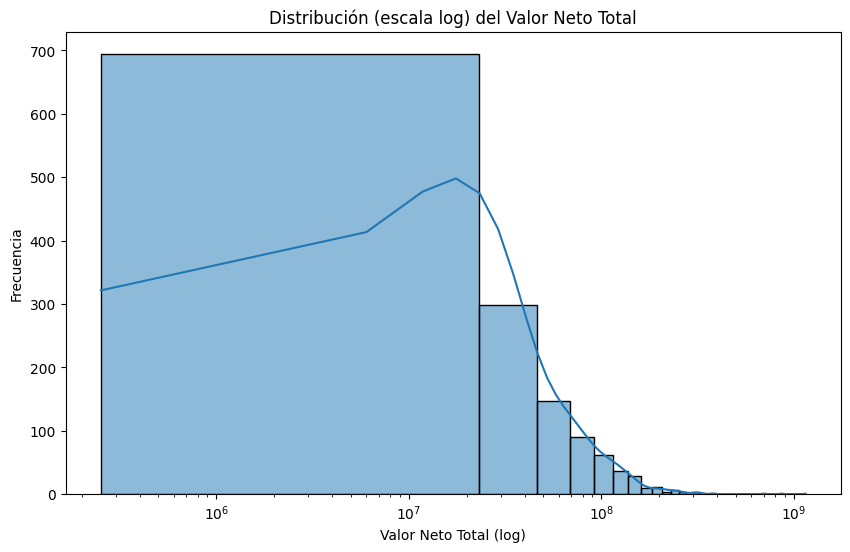

In [85]:
plt.figure(figsize=(10,6))
sns.histplot(data = df_benef_n, x = "Valor_Neto_Total", bins=50, kde=True)
plt.xscale("log")

plt.title("Distribución (escala log) del Valor Neto Total")
plt.xlabel("Valor Neto Total (log)")
plt.ylabel("Frecuencia")

plt.show()

#### ⚠️ Por revisar

Al igual que en histograma en escala logarítmica del Valor Neto Total por el tipo de persona Jurídica, en este caso se observa un comportamiento similar. La mayoría de los beneficiarios están en valores relativamente bajos. Y unos pocos beneficiarios concentran montos muy grandes en órdenes de magnitud. Además la curva KDE no es simétrica por lo que invalidad cualquier tipo de estadística clásica.

#### Cálculo del coeficiente de Gini

In [86]:
gini_valor = gini(df_benef_n["Valor_Neto_Total"])
print(f"Gini: {gini_valor:.4f}")

Gini: 0.5447


El cálculo del coeficiente de Gini mide la desigualdad de los datos. Siendo:
- 0 = Distribución perfecta de igualdad
- 1 = Máxima desigualdad

Con un resultado de ``0.5447`` se observa una **concentración moderada de desigualdad**

#### Curva de Lorenz

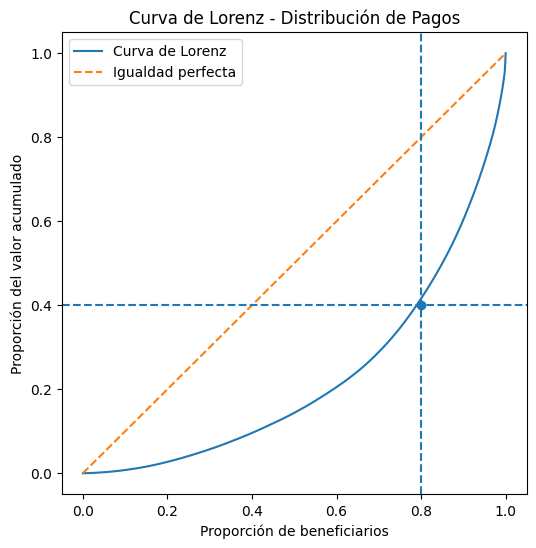

In [87]:
curva_lorenz(df_benef_n["Valor_Neto_Total"], 0.8, 0.4)

Según la curva de Lorenz, observamos que:

- Cerca del 80% de beneficiarios llegal al 40% del valor Neto Total de los giros
- El 20% restante concentra más del 60% de los giros tesorales.

Por lo tanto, se determina un patrón Pareto.

Esta concentración determina un riesgo medio.

#### ⚠️ Por revisar

- Existe una dependencia excesiva en beneficiarios específicos?
- Hay un posible direccionamiento de contratos?
- Hay giros atípicos?
    - Pocos giros de montos muy altos?
    - Muchos giros sistemáticos ?

### Creación de ranking de riesgo por tipo de persona Jurídica

In [88]:
# Variables de riesgo

df_benef_n["log_valor"] = np.log1p(df_benef_n["Valor_Neto_Total"])
df_benef_n["log_cantidad"] = np.log1p(df_benef_n["Cantidad"])
df_benef_n["log_promedio"] = np.log1p(df_benef_n["Promedio"])

In [89]:
# Z-Score Robusto
# (Valor - Promedio) / Desviación Estándar

for col in ["log_valor", "log_cantidad", "log_promedio"]:
    #df_benef_j[f"z_{col}"] = (df_benef_j[col] - df_benef_j[col].mean()) / df_benef_j[col].std()
    IQR = df_benef_n[col].quantile(0.75) - df_benef_n[col].quantile(0.25)

    if IQR == 0:
        df_benef_n[f"z_{col}"] = 0
    else:    
        df_benef_n[f"z_{col}"] = (df_benef_n[col] - df_benef_n[col].median()) / IQR

In [90]:
# Penalización
# El criterio se basa en que el riesgo es alto cuando:
# - Valor total alto
# - Promedio alto
# - Pocos giros

# Penalización
# El criterio se basa en que el riesgo es alto cuando:
# - Valor total alto
# - Promedio alto
# - Pocos giros

df_benef_n["riesgo_score"] = (
    df_benef_n["z_log_valor"].mul(0.5) +
    df_benef_n["z_log_promedio"].mul(0.3) -
    df_benef_n["z_log_cantidad"].mul(0.2)
)

In [91]:
# Ranking

df_benef_n.sort_values(by="riesgo_score", ascending=False)

,Valor_Neto_Total,Cantidad,Promedio,log_valor,log_cantidad,log_promedio,z_log_valor,z_log_cantidad,z_log_promedio,riesgo_score
Razon_Social,,,,,,,,,,
DAGOBERTO ROBAYO GUTIERREZ,858307540,4,2.145769e+08,20.570473,1.609438,19.184179,2.533796,-0.479190,7.649767,3.657666
JORGE ELIECER GAITAN TORRES,1149730864,9,1.277479e+08,20.862794,2.302585,18.665569,2.740176,0.227505,6.710038,3.337599
MARTHA LUCIA FERNANDEZ SARMIENTO,194673106,10,1.946731e+07,19.086832,2.397895,16.784247,1.486340,0.324678,3.301055,1.668551
MARIA GLADIS OCAMPO,699873493,61,1.147334e+07,20.366410,4.127134,16.255536,2.389727,2.087716,2.343023,1.480227
MAGDA CRISTINA MONTAÑA MURILLO,377350146,35,1.078143e+07,19.748684,3.583519,16.193336,1.953610,1.533475,2.230315,1.339204
...,...,...,...,...,...,...,...,...,...,...
LUIS ORLANDO BARRERA CEPEDA,1903817,5,3.807634e+05,14.459372,1.791759,12.849936,-1.780668,-0.293305,-3.827976,-1.980066
JUAN CARLOS LOZANO MUNEVAR,9873760,57,1.732239e+05,16.105391,4.060443,12.062346,-0.618571,2.019721,-5.255101,-2.289760
LAURA CAROLINA DIAZ BARRIOS,375000,1,3.750000e+05,12.834684,0.693147,12.834684,-2.927704,-1.413390,-3.855613,-2.337858


In [92]:
df[df["Razon_Social"] == "COMWARE S. A.   "]

,Vigencia,Número de orden de pago,ID_Tercero,Fecha Giro,Número de cuenta,Banco,Razon_Social,Tipo de persona,Tipo de gasto,Fecha CRP,...,Adulto mayor,Otros descuentos,Total descuentos,Valor Neto,Cuenta contable,Credito,ID_Soporte,id_unico,año,mes
15013,2023,9598,860045379,2023-12-28,54009329,ITAÚ CORPBANCA COLOMBIA S A,COMWARE S. A.,JURIDICA,SERVICIOS,2023-10-13,...,0.0,0.0,2381275.0,49771048,1110,49771048,9598,9598_860045379_,2023,12
15014,2023,9599,860045379,2023-12-28,54009329,ITAÚ CORPBANCA COLOMBIA S A,COMWARE S. A.,JURIDICA,SERVICIOS,2023-10-13,...,0.0,0.0,10387454.0,217108246,1110,217108246,9599,9599_860045379_,2023,12
15015,2023,9600,860045379,2023-12-28,54009329,ITAÚ CORPBANCA COLOMBIA S A,COMWARE S. A.,JURIDICA,SERVICIOS,2023-10-13,...,0.0,0.0,10958400.0,229041600,1110,229041600,9600,9600_860045379_,2023,12
15304,2024,10173,860045379,2024-03-02,54009329,ITAÚ CORPBANCA COLOMBIA S A,COMWARE S. A.,JURIDICA,SERVICIOS,2024-01-01,...,5723584.0,0.0,13066942.0,273112262,1110,273112262,10173,10173_860045379_,2024,3
15365,2024,10268,860045379,2024-03-15,54009329,ITAÚ CORPBANCA COLOMBIA S A,COMWARE S. A.,JURIDICA,SERVICIOS,2024-01-01,...,4788519.0,0.0,10932190.0,228493774,1110,228493774,10268,10268_860045379_,2024,3
15416,2024,10392,860045379,2024-04-10,54009329,ITAÚ CORPBANCA COLOMBIA S A,COMWARE S. A.,JURIDICA,SERVICIOS,2024-01-01,...,5229639.0,0.0,11939266.0,249542682,1110,249542682,10392,10392_860045379_,2024,4
15451,2024,10470,860045379,2024-05-16,54009329,ITAÚ CORPBANCA COLOMBIA S A,COMWARE S. A.,JURIDICA,SERVICIOS,2024-01-01,...,1524905.0,0.0,3481358.0,72763906,1110,72763906,10470,10470_860045379_,2024,5


In [93]:
# Clasificación por niveles

def clasificar_riesgo(score):
    if score > 1.5:
        return "ALTO"
    elif score > 0.5:
        return "MEDIO"
    else:
        return "BAJO"

df_benef_n["nivel_riesgo"] = df_benef_n["riesgo_score"].apply(clasificar_riesgo)

Luego de obtener el indicador de riesgo y el score de riesgo, se procede a extraer los giros del top 50 de ``Tipo de Persona`` natural con mayor riesgo

In [94]:
df_riesgo_benef_n = df_benef_n[(df_benef_n["nivel_riesgo"] == "ALTO") | (df_benef_n["nivel_riesgo"] == "MEDIO")].reset_index().head(10)

benef_n = df_riesgo_benef_n.sort_values(by="riesgo_score", ascending = False)
benef_n

,Razon_Social,Valor_Neto_Total,Cantidad,Promedio,log_valor,log_cantidad,log_promedio,z_log_valor,z_log_cantidad,z_log_promedio,riesgo_score,nivel_riesgo
1,DAGOBERTO ROBAYO GUTIERREZ,858307540,4,2.145769e+08,20.570473,1.609438,19.184179,2.533796,-0.479190,7.649767,3.657666,ALTO
0,JORGE ELIECER GAITAN TORRES,1149730864,9,1.277479e+08,20.862794,2.302585,18.665569,2.740176,0.227505,6.710038,3.337599,ALTO
2,MARIA GLADIS OCAMPO,699873493,61,1.147334e+07,20.366410,4.127134,16.255536,2.389727,2.087716,2.343023,1.480227,MEDIO
3,MAGDA CRISTINA MONTAÑA MURILLO,377350146,35,1.078143e+07,19.748684,3.583519,16.193336,1.953610,1.533475,2.230315,1.339204,MEDIO
7,AILEN PATRICIA ESPINOZA LUNA,307218099,37,8.303192e+06,19.543068,3.637586,15.932151,1.808444,1.588599,1.757043,1.113615,MEDIO
6,RICARDO MAURICIO RODRIGO VALENCIA TOVAR,311843773,38,8.206415e+06,19.558013,3.663562,15.920427,1.818995,1.615082,1.735799,1.107221,MEDIO
8,MARIA ROSARIO PINERES ESPINOSA,301697541,40,7.542439e+06,19.524936,3.713572,15.836056,1.795642,1.666070,1.582919,1.039483,MEDIO
5,DARLYNG VEGA PANAMEÑO,324254170,47,6.899025e+06,19.597038,3.871201,15.746891,1.846547,1.826780,1.421349,0.984322,MEDIO
9,JACK JONATHAN MEDINA ROJAS,274279959,42,6.530475e+06,19.429660,3.761200,15.691990,1.728377,1.714629,1.321869,0.917824,MEDIO
4,EDWUARD ANDRES REYES ALVARADO,327545567,55,5.955374e+06,19.607138,4.025352,15.599805,1.853678,1.983944,1.154827,0.876498,MEDIO


In [95]:
df_giros_naturales = df[df["Razon_Social"].isin(benef_n["Razon_Social"])]
df_giros_naturales

,Vigencia,Número de orden de pago,ID_Tercero,Fecha Giro,Número de cuenta,Banco,Razon_Social,Tipo de persona,Tipo de gasto,Fecha CRP,...,Adulto mayor,Otros descuentos,Total descuentos,Valor Neto,Cuenta contable,Credito,ID_Soporte,id_unico,año,mes
49,2021,3114,79864985,2021-02-11,69529683553,BANCOLOMBIA S A,EDWUARD ANDRES REYES ALVARADO,NATURAL,SERVICIOS,2021-06-17,...,76667.0,0.0,103501.0,3729832,1110,3729832,3114,3114_79864985_,2021,2
107,2021,3548,79864985,2021-03-23,69529683553,BANCOLOMBIA S A,EDWUARD ANDRES REYES ALVARADO,NATURAL,SERVICIOS,2021-06-17,...,100000.0,0.0,134126.0,4865874,1110,4865874,3548,3548_79864985_,2021,3
121,2021,3591,79864985,2021-04-14,69529683553,BANCOLOMBIA S A,EDWUARD ANDRES REYES ALVARADO,NATURAL,SERVICIOS,2021-06-17,...,100000.0,0.0,133860.0,4866140,1110,4866140,3591,3591_79864985_,2021,4
154,2021,3714,79864985,2021-05-11,69529683553,BANCOLOMBIA S A,EDWUARD ANDRES REYES ALVARADO,NATURAL,SERVICIOS,2021-06-17,...,23333.0,0.0,30359.0,1136308,1110,1136308,3714,3714_79864985_,2021,5
204,2021,72,1010191658,2021-03-13,42890091525,BANCOLOMBIA S A,JACK JONATHAN MEDINA ROJAS,NATURAL,SERVICIOS,2021-01-31,...,141060.0,0.0,482682.0,6570318,1110,6570318,72,72_1010191658_,2021,3
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
16139,2024,1082,51999560,2024-05-30,21080712453,BANCOLOMBIA S A,MARIA ROSARIO PINERES ESPINOSA,NATURAL,SERVICIOS,2024-01-24,...,273596.0,0.0,1343687.0,12336115,1110,12336115,1082,1082_51999560_,2024,5
16212,2024,1349,51999560,2024-06-13,21080712453,BANCOLOMBIA S A,MARIA ROSARIO PINERES ESPINOSA,NATURAL,SERVICIOS,2024-01-04,...,87234.0,0.0,117652.0,4244024,1110,4244024,1349,1349_51999560_,2024,6
16245,2024,1406,51999560,2024-06-17,21080712453,BANCOLOMBIA S A,MARIA ROSARIO PINERES ESPINOSA,NATURAL,SERVICIOS,2024-01-24,...,273596.0,0.0,1375925.0,12303877,1110,12303877,1406,1406_51999560_,2024,6
16246,2024,1407,51999560,2024-06-17,21080712453,BANCOLOMBIA S A,MARIA ROSARIO PINERES ESPINOSA,NATURAL,SERVICIOS,2024-01-24,...,273596.0,0.0,1375925.0,12303877,1110,12303877,1407,1407_51999560_,2024,6


#### ✅ Agregar indices al diccionario de giros

In [96]:
mas_grandes = df_giros_naturales.nlargest(10, "Valor Neto")
resto = df_giros_naturales.drop(mas_grandes.index)
aleatorios = resto.sample(20, random_state = 42)
df_giros_naturales = pd.concat([mas_grandes, aleatorios])


In [97]:
df_giros_naturales

,Vigencia,Número de orden de pago,ID_Tercero,Fecha Giro,Número de cuenta,Banco,Razon_Social,Tipo de persona,Tipo de gasto,Fecha CRP,...,Adulto mayor,Otros descuentos,Total descuentos,Valor Neto,Cuenta contable,Credito,ID_Soporte,id_unico,año,mes
10921,2023,12643,79548029,2023-07-11,59659635046,BANCOLOMBIA S A,JORGE ELIECER GAITAN TORRES,NATURAL,SERVICIOS,2023-12-29,...,4991514.0,0.0,43164310.0,253830772,1110,253830772,12643,12643_79548029_,2023,7
10904,2023,12525,79846882,2023-04-20,111160129026,BANCO FALABELLA S.A.,DAGOBERTO ROBAYO GUTIERREZ,NATURAL,SERVICIOS,2023-12-29,...,4991400.0,0.0,43477473.0,253510827,1110,253510827,12525,12525_79846882_,2023,4
8831,2022,8579,79548029,2022-11-17,59659635046,BANCOLOMBIA S A,JORGE ELIECER GAITAN TORRES,NATURAL,SERVICIOS,2022-08-16,...,4159595.0,0.0,31457771.0,216038132,1110,216038132,8579,8579_79548029_,2022,11
10349,2022,11276,79548029,2022-12-29,59659635046,BANCOLOMBIA S A,JORGE ELIECER GAITAN TORRES,NATURAL,SERVICIOS,2022-08-16,...,4159595.0,0.0,31457771.0,216038132,1110,216038132,11276,11276_79548029_,2022,12
8830,2022,8578,79846882,2022-11-17,111160129026,BANCO FALABELLA S.A.,DAGOBERTO ROBAYO GUTIERREZ,NATURAL,SERVICIOS,2022-08-16,...,4159500.0,0.0,31541071.0,215949179,1110,215949179,8578,8578_79846882_,2022,11
10348,2022,11275,79846882,2022-12-29,111160129026,BANCO FALABELLA S.A.,DAGOBERTO ROBAYO GUTIERREZ,NATURAL,SERVICIOS,2022-08-16,...,4159500.0,0.0,31541071.0,215949179,1110,215949179,11275,11275_79846882_,2022,12
6785,2022,5519,79548029,2022-09-13,59659635046,BANCOLOMBIA S A,JORGE ELIECER GAITAN TORRES,NATURAL,SERVICIOS,2022-08-16,...,3327676.0,0.0,23736328.0,174260394,1110,174260394,5519,5519_79548029_,2022,9
6659,2022,5369,79846882,2022-09-09,111160129026,BANCO FALABELLA S.A.,DAGOBERTO ROBAYO GUTIERREZ,NATURAL,SERVICIOS,2022-08-16,...,3327600.0,0.0,25093845.0,172898355,1110,172898355,5369,5369_79846882_,2022,9
14098,2023,7661,45495531,2023-11-09,59659635046,BANCOLOMBIA S A,JORGE ELIECER GAITAN TORRES,NATURAL,SERVICIOS,2023-04-04,...,0.0,0.0,19594991.0,111619009,1110,111619009,7661,7661_45495531_,2023,11
15347,2024,10244,79548029,2024-03-14,59659635046,BANCOLOMBIA S A,JORGE ELIECER GAITAN TORRES,NATURAL,SERVICIOS,2024-07-23,...,1214403.0,0.0,7298353.0,64958647,1110,64958647,10244,10244_79548029_,2024,3


In [98]:
lista_df.append(df_giros_naturales)

### Aplicación de la Ley de Benford 

En base a los resultados del coeficiente de Gini la Curva de Lorenz y la distribución anormal que se presentan en los años 2022 y 2023. Se analizará el valor bruto del universo aplicando la Ley de Benford. La cual afirma que el primer dígito de una fuente de datos común se distribuye en un modo específico.

Este método de análisis es muy usado en la gestión de fraude ya que demuestra la predictibilidad del comportamiento de una variable aleatoria de la vida real. Si este comportamiento varía con respecto a la distribucion de la Ley de Benford es muy probable que se hayan presentado cambios inducidos en los datos.

Para realizar este análisis se requierien cumplir ciertos requisitos:

- Mínimo 10.000 datos
- Datos que registren más de 4 dígitos
- Los datos no deben ser provenientes de distribuciones uniformes o normales.

Para este ejercicio se cuenta con:

- 16.875 datos
- Datos con más de 4 dígitos
- La distribución de los datos no es uniforme ni normal

In [126]:
def benford_analysis(df, column):
    """
    Evalúa la Ley de Benford sobre una columna numérica de un DataFrame.

    Parámetros:
    - df: DataFrame
    - column: nombre de la columna a analizar

    Retorna:
    - DataFrame con distribución observada vs esperada
    """

    # Limpiar datos
    data = df[df[column].apply(lambda x: len(str(x))) > 4]
    data = data[column].dropna()
    data = data[data != 0]
    data = data.abs()
    
    # Extraer primer dígito
    first_digits = data.astype(str).str[0]
    first_digits = first_digits[first_digits.isin(list('123456789'))]

    # Proporcion observada 
    observed = first_digits.value_counts(normalize=True).sort_index()

    # Frecuencia observada
    observed_f = first_digits.value_counts().sort_index()

    # Distribución esperada (Benford)
    digits = np.arange(1, 10)
    expected = np.log10(1 + 1 / digits)

    # Distribución transformada

    total = observed_f.sum()
    expected_f = expected * total

    benford_df = pd.DataFrame({
        "expected": expected,
        "observed": observed
    })

    # Métrica de desviación (MAD - Mean Absolute Deviation)
    benford_df["abs_diff"] = abs(benford_df["observed"] - benford_df["expected"])
    mad = benford_df["abs_diff"].mean()

    print(f"MAD (Mean Absolute Deviation): {mad:.6f}")

    # Chi cuadrado
    # “¿Qué tan lejos está lo observado de lo esperado, ponderado por el tamaño esperado?”

    chi2_stat, p_value = chisquare(f_obs = observed_f, f_exp = expected_f)
    print(f"Chi-cuadrado: {chi2_stat}")
    print(f"p-value: {p_value}")

    # Interpretación básica
    if mad < 0.006:
        print("Conformidad cercana a Benford")
    elif mad < 0.012:
        print("Conformidad aceptable")
    elif mad < 0.015:
        print("Posible desviación")
    else:
        print("Alta desviación (posibles anomalías)")

    plt.figure()
    plt.plot(digits, expected, marker='o', label='Esperado')
    plt.plot(digits, benford_df["observed"], marker='o', label='Observado')
    plt.xlabel("Dígito")
    plt.ylabel("Frecuencia")
    plt.title(f"Ley de Benford - {column}")
    plt.legend()
    plt.show()

    return benford_df

MAD (Mean Absolute Deviation): 0.041151
Chi-cuadrado: 3031.481199603415
p-value: 0.0
Alta desviación (posibles anomalías)


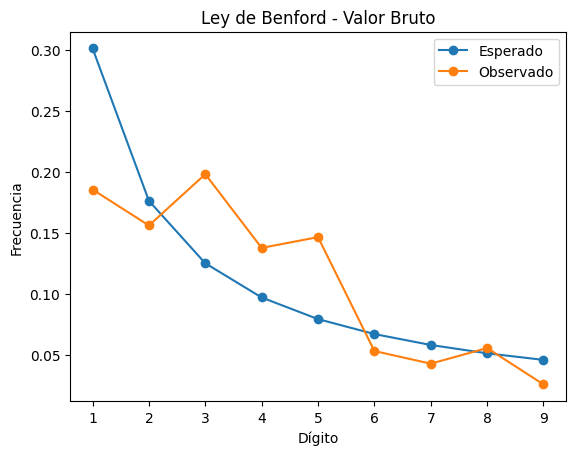

In [127]:
resultado = benford_analysis(df, "Valor Bruto")

El resultado de la comparación entre los valores observados y esperados de la Ley de Benford sugiere que:

Existen desviaciones sistemáticas, no aleatorias.

Puede haber riesgo de:

- Manipulación de valores.
- Datos generados o ajustados manualmente.
- Reglas de negocio que alteren la distribución.

Sin embargo aunque este resultado no permite concluir que exista fraude.

Si se evidencian desviaciones estadísticamente significativas (Chi² = 3031; p < 0.001; MAD = 0.041), lo cual sugiere la presencia de patrones no naturales en la distribución de los valores analizados. Se recomienda realizar pruebas sustantivas adicionales mediante segmentación de los datos para identificar posibles focos de riesgo.

MAD (Mean Absolute Deviation): 0.056862
Chi-cuadrado: 1334.2644672290235
p-value: 9.217033928240384e-283
Alta desviación (posibles anomalías)


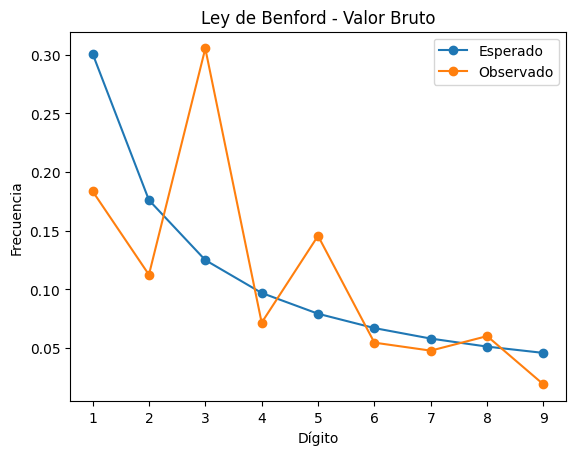

In [128]:
resultado_2024 = benford_analysis(df[df["año"] == 2021], "Valor Bruto")

### Análisis por Banco

In [103]:
banco_valor_total = df.groupby("Banco")["Valor Neto"].sum().reset_index(name = 'Valor neto total').sort_values(by="Valor neto total", ascending = False)
banco_valor_total

,Banco,Valor neto total
12,BANCOLOMBIA S A,28250881781
4,BANCO DAVIVIENDA S.A.,19864809973
1,BANCO BILBAO VIZCAYA ARGENTARIA COLOMBIA S A,13417017537
5,BANCO DE BOGOTA,8960995770
2,BANCO CAJA SOCIAL S.A.,6996568847
19,SCOTIABANK COLPATRIA,5217461687
6,BANCO DE OCCIDENTE,5175643061
16,ITAÚ CORPBANCA COLOMBIA S A,1733616690
14,CITIBANK - COLOMBIA S A,1185508563
7,BANCO FALABELLA S.A.,1118739882


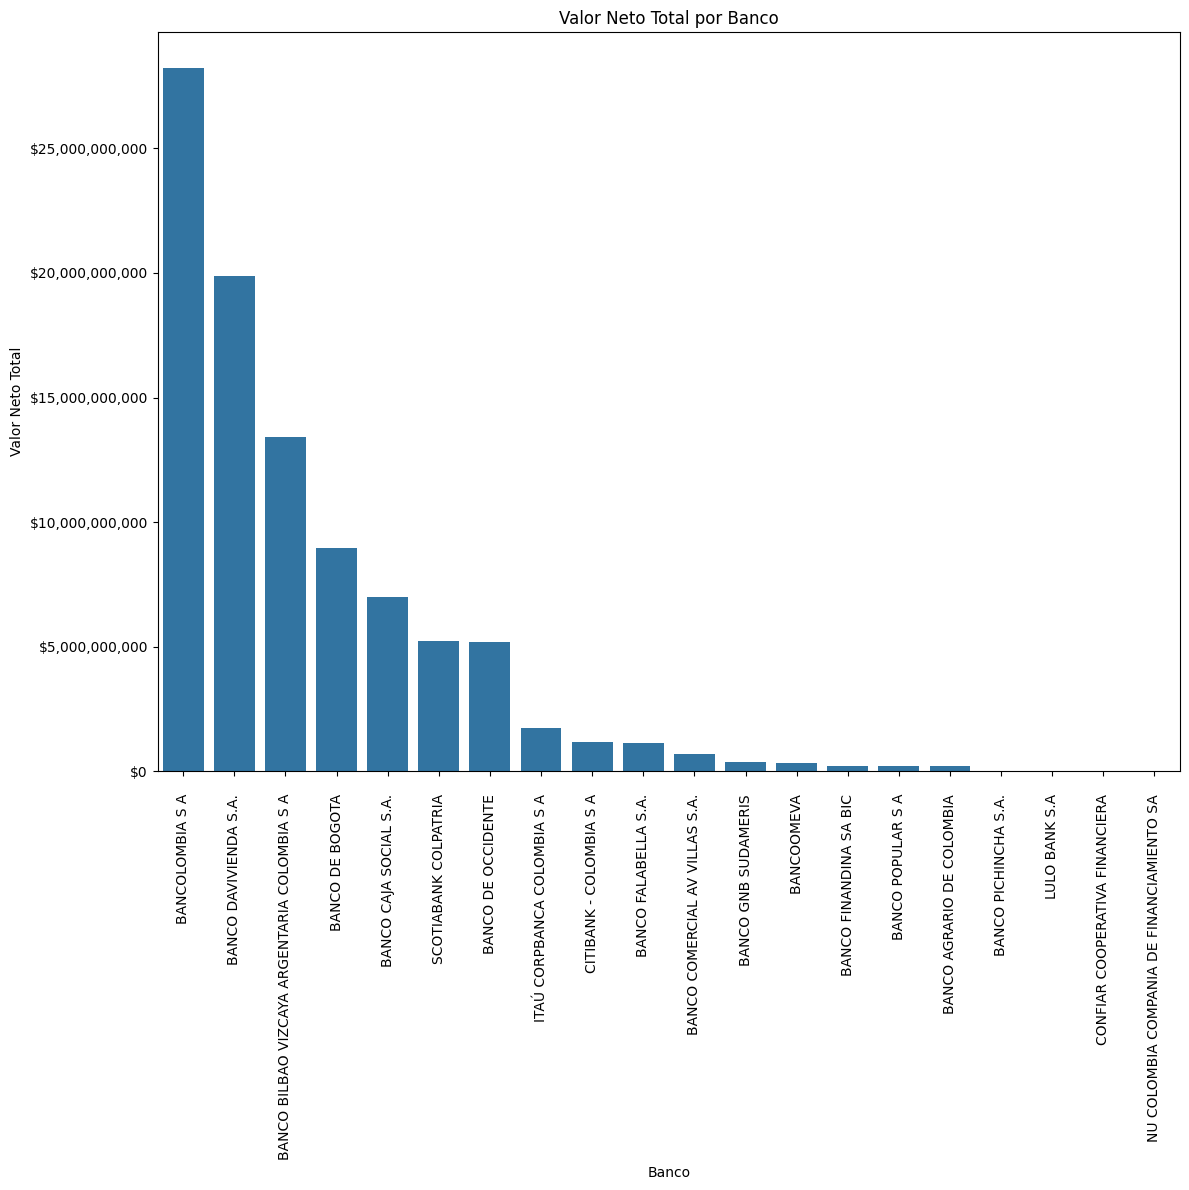

In [104]:
plt.figure(figsize=(12,12))
ax = sns.barplot(data=banco_valor_total, x="Banco", y="Valor neto total")

ax.yaxis.set_major_formatter(mtick.StrMethodFormatter('${x:,.0f}'))

plt.title("Valor Neto Total por Banco")
plt.xlabel("Banco")
plt.ylabel("Valor Neto Total")

plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

### Verificación de columnas duplicadas

Se verifica si las características ``"Número de orden de pago"`` y `"ID_Soporte"` tienen exactamente los mismos datos.

In [105]:
df["Número de orden de pago"].equals(df["ID_Soporte"])

True

Al ser verdad. Se procede a eliminar la columna duplicada: `"ID_Soporte"`

In [106]:
df.drop(columns = ["ID_Soporte"], inplace = True)

#### Verificación de ``Número de orden de pago``

Verificar si ``Número de orden de pago`` es único para cada giro tesoral

In [107]:
df["Número de orden de pago"].is_unique

False

Debido a que no son únicos, se procede a evaluar el impacto:

In [ ]:
#df[df.groupby("Número de orden de pago")["Número de orden de pago"].transform("count") > 1]
duplicados_orden_pago = df[df.duplicated(subset=["Número de orden de pago"], keep = False)]
duplicados_orden_pago

,Vigencia,Número de orden de pago,ID_Tercero,Fecha Giro,Número de cuenta,Banco,Razon_Social,Tipo de persona,Tipo de gasto,Fecha CRP,...,Estampilla Universidad FJC,Adulto mayor,Otros descuentos,Total descuentos,Valor Neto,Cuenta contable,Credito,id_unico,año,mes
0,2021,2991,1088259568,2021-02-03,127270151591,BANCO DAVIVIENDA S.A.,YONNY ANDRES CRUZ BENJUMEA,NATURAL,SERVICIOS,2021-04-26,...,0.0,37500.0,0.0,63022.0,1499478,1110,1499478,2991_1088259568_,2021,2
1,2021,2992,1088259568,2021-02-03,127270151591,BANCO DAVIVIENDA S.A.,YONNY ANDRES CRUZ BENJUMEA,NATURAL,SERVICIOS,2021-06-21,...,0.0,0.0,0.0,0.0,312500,1110,312500,2992_1088259568_,2021,2
2,2021,3001,52539367,2021-02-04,570008870331215,BANCO DAVIVIENDA S.A.,ALEXANDRA VARGAS PINILLA,NATURAL,SERVICIOS,2021-05-12,...,0.0,156740.0,0.0,546214.0,7290786,1110,7290786,3001_52539367_,2021,2
3,2021,3047,1094938732,2021-02-08,120237187,BANCOLOMBIA S A,MARIA ALEJANDRA LONDOÑO JIMENEZ,NATURAL,SERVICIOS,2021-06-21,...,0.0,30000.0,0.0,52500.0,1447500,1110,1447500,3047_1094938732_,2021,2
4,2021,3053,1093773164,2021-02-08,570457370201248,BANCO DAVIVIENDA S.A.,JURGEN DANIEL TOLOZA DELGADO,NATURAL,SERVICIOS,2021-06-03,...,0.0,109680.0,0.0,341099.0,6184861,1110,6184861,3053_1093773164_,2021,2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
16895,2024,4624,1113512793,2024-12-28,85821640704,BANCOLOMBIA S A,MARY YULIANA JARAMILLO,NATURAL,SERVICIOS,2024-02-01,...,0.0,138942.0,0.0,189766.0,6757313,1110,6757313,4624_1113512793_,2024,12
16896,2024,4640,1143338180,2024-12-29,78800010080,BANCOLOMBIA S A,YELIZA MERCEDES PEREZ LICONA,NATURAL,SERVICIOS,2024-02-01,...,0.0,54033.0,0.0,73423.0,2628219,1110,2628219,4640_1143338180_,2024,12
16897,2024,4641,1047368991,2024-12-29,56600181756,BANCO DAVIVIENDA S.A.,LUISA FERNANDA LARIOS DIAZ,NATURAL,SERVICIOS,2024-01-29,...,0.0,54033.0,0.0,74534.0,2627108,1110,2627108,4641_1047368991_,2024,12
16898,2024,4653,64564800,2024-12-30,57700132848,BANCO DAVIVIENDA S.A.,SALMA ELENA CALDAS OTERO,NATURAL,SERVICIOS,2024-02-01,...,0.0,0.0,0.0,0.0,2,1110,2,4653_64564800_,2024,12


Existen ``11.883`` giros con órdenes de pago iguales.
Obteniendo un impacto en la característica ``órdenes de pago`` de:

In [109]:
print("Impacto del:{0:8.2f}%".format((len(duplicados_orden_pago))/len(df)* 100))

Impacto del:   70.31%


#### ⚠️ Por revisar

Se ha identificado que el 71.31% de los registros presentan repetición en el número de orden de pago. Esta situación podría obedecer a la existencia de múltiples giros asociados a una misma orden, sin embargo, se requiere validar la consistencia de estos registros para descartar duplicidades indebidas o errores en el procesamiento.

El máximo número de órdenes por giro es de 5.

In [135]:
df.groupby("Número de orden de pago").size()#.value_counts()

Número de orden de pago
1        2
2        3
3        2
4        2
5        2
        ..
12786    1
12788    1
12790    1
12791    1
12801    1
Length: 10192, dtype: int64

In [110]:
conteo_orden = df.groupby("Número de orden de pago").size()
conteo_orden.describe()

count    10192.000000
mean         1.658163
std          0.750563
min          1.000000
25%          1.000000
50%          2.000000
75%          2.000000
max          5.000000
dtype: float64

In [111]:
ordenes_sospechosas = conteo_orden[conteo_orden > 3]
ordenes_sospechosas.sort_values(ascending=False)

Número de orden de pago
3092    5
17      4
18      4
20      4
13      4
       ..
4480    4
4521    4
4524    4
4605    4
4640    4
Length: 189, dtype: int64

Se hace revisión de la órden de pago número 3092, y se encuentra que esta órden fue usada para giros efectuados en fechas diferentes.

In [112]:
df[df["Número de orden de pago"] == 3092]

,Vigencia,Número de orden de pago,ID_Tercero,Fecha Giro,Número de cuenta,Banco,Razon_Social,Tipo de persona,Tipo de gasto,Fecha CRP,...,Estampilla Universidad FJC,Adulto mayor,Otros descuentos,Total descuentos,Valor Neto,Cuenta contable,Credito,id_unico,año,mes
28,2021,3092,1131185598,2021-02-10,451099287,BANCO BILBAO VIZCAYA ARGENTARIA COLOMBIA S A,MARLEN CECILIA RUIZ MOSQUERA,NATURAL,SERVICIOS,2021-04-30,...,0.0,37500.0,0.0,63085.0,1811915,1110,1811915,3092_1131185598_,2021,2
1404,2021,3092,1024497533,2021-10-04,61869646929,BANCOLOMBIA S A,HECTOR LEONARDO ARIAS GARCIA,NATURAL,SERVICIOS,2021-03-11,...,0.0,129140.0,0.0,330216.0,6126784,1110,6126784,3092_1024497533_,2021,10
5228,2022,3092,79046541,2022-07-07,550488407178620,BANCO DAVIVIENDA S.A.,SEGUNDO FIDEL PUERTO GARAVITO,NATURAL,SERVICIOS,2022-01-28,...,0.0,149640.0,0.0,494270.0,6987730,1110,6987730,3092_79046541_,2022,7
12360,2023,3092,1013624954,2023-07-05,550488434188931,BANCO DAVIVIENDA S.A.,MICHAEL STIVENS VILLAMIL QUINTERO,NATURAL,SERVICIOS,2023-01-06,...,0.0,65340.0,0.0,103847.0,3163153,1110,3163153,3092_1013624954_,2023,7
16657,2024,3092,1007313801,2024-10-13,67824799552,BANCOLOMBIA S A,CLARIBETH DEL CARMEN ALVAREZ CORTES,NATURAL,SERVICIOS,2024-01-30,...,0.0,54033.0,0.0,74534.0,2627108,1110,2627108,3092_1007313801_,2024,10


In [113]:
df[df["Número de orden de pago"] == 17]

,Vigencia,Número de orden de pago,ID_Tercero,Fecha Giro,Número de cuenta,Banco,Razon_Social,Tipo de persona,Tipo de gasto,Fecha CRP,...,Estampilla Universidad FJC,Adulto mayor,Otros descuentos,Total descuentos,Valor Neto,Cuenta contable,Credito,id_unico,año,mes
166,2021,17,80410647,2021-02-05,4070115110,BANCO DAVIVIENDA S.A.,JAVIER RICARDO RINCON RUEDA,NATURAL,SERVICIOS,2021-02-05,...,0.0,0.0,0.0,0.0,2851233,1110,2851233,17_80410647_,2021,2
3928,2022,17,800052640,2022-01-21,<NA>,NaN,EMPRESA DE ENERGIA DEL QUINDIO S.A. E.S.P. EMP...,JURIDICA,SERVICIOS,2022-01-21,...,0.0,0.0,0.0,0.0,500609,1110,500609,17_800052640_,2022,1
10979,2023,17,800052640,2023-01-30,<NA>,NaN,EMPRESA DE ENERGIA DEL QUINDIO S.A. E.S.P. EMP...,JURIDICA,SERVICIOS,2023-01-23,...,0.0,0.0,0.0,0.0,550062,1110,550062,17_800052640_,2023,1
15522,2024,17,800249860,2024-01-25,<NA>,NaN,CELSIA COLOMBIA S.A E.S.P,JURIDICA,SERVICIOS,2024-01-24,...,0.0,0.0,0.0,0.0,3540667,1110,3540667,17_800249860_,2024,1


#### ⚠️ Por revisar

Se ha identificado que los números de órden de pago contienen varios giros tesorales en fechas separadas por años de diferencia. Lo que sugiere una posible reutilización o una mala gestión del identificador. Debe verificarse si el identificador ``"Número de orden de pago"`` no es único e identifica a un documento base reutilizable, lote o un proceso en específico.

In [114]:
df.groupby("Número de orden de pago")["Razon_Social"].nunique().sort_values(ascending=False)

Número de orden de pago
3092     5
2699     4
146      4
179      4
1175     4
        ..
12801    1
12791    1
12790    1
12788    1
12786    1
Name: Razon_Social, Length: 10192, dtype: int64

#### ⚠️ Por revisar

Se encuentran diferencias de más de 3 años en 233 números de órden de pago.

In [115]:
res = df.groupby(["Número de orden de pago"])["Fecha Giro"].agg(["min", "max"])
res["dias_diferencia"] = (res["max"] - res["min"]).dt.days

In [116]:
res[res["dias_diferencia"] > 1095].sort_values(by = "dias_diferencia", ascending = False)

,min,max,dias_diferencia
Número de orden de pago,,,
3269,2021-02-22,2024-10-30,1346
3113,2021-02-10,2024-10-16,1344
3110,2021-02-10,2024-10-16,1344
3111,2021-02-10,2024-10-16,1344
3112,2021-02-10,2024-10-16,1344
...,...,...,...
2212,2021-08-13,2024-08-14,1097
2153,2021-08-12,2024-08-12,1096
2189,2021-08-13,2024-08-13,1096


Siendo el ``Número de órden de pago`` **3269** el que más diferencias de días tiene

In [117]:
df[df["Número de orden de pago"] == 3269]

,Vigencia,Número de orden de pago,ID_Tercero,Fecha Giro,Número de cuenta,Banco,Razon_Social,Tipo de persona,Tipo de gasto,Fecha CRP,...,Estampilla Universidad FJC,Adulto mayor,Otros descuentos,Total descuentos,Valor Neto,Cuenta contable,Credito,id_unico,año,mes
61,2021,3269,80158487,2021-02-22,4752000336,SCOTIABANK COLPATRIA,FABIAN ESTEBAN FUENTES RODRÍGUEZ,NATURAL,SERVICIOS,2021-07-14,...,0.0,31360.0,0.0,84832.0,1483168,1110,1483168,3269_80158487_,2021,2
1461,2021,3269,1072669411,2021-10-06,18000011491,BANCOLOMBIA S A,CAMILO JOSE RUIZ MORALES,NATURAL,SERVICIOS,2021-07-16,...,0.0,100000.0,0.0,169300.0,4830700,1110,4830700,3269_1072669411_,2021,10
16729,2024,3269,1047496708,2024-10-30,17518778609,BANCOLOMBIA S A,ANGELLYS ELENA GOMEZ TABARES,NATURAL,SERVICIOS,2024-01-24,...,0.0,69471.0,0.0,96072.0,3377468,1110,3377468,3269_1047496708_,2024,10


Se construye un indicador de riesgo que evalúa los ``Números de Órden de Pago`` que tienen más de 3 giros tesorales y que además sean mayores al 95% de los valores de la suma del ``Valor Neto`` de los datos.

In [131]:
(resumen["num_giros"] > 5).astype(int)

131    0
19     0
17     0
27     0
16     0
61     0
58     0
57     0
67     0
109    0
Name: num_giros, dtype: int64

In [130]:
resumen = df.groupby("Número de orden de pago").agg({
    "Valor Neto": ["count", "sum", "mean"]
})

resumen.columns = ["num_giros", "total_pagado", "promedio"]

resumen["riesgo"] = (
    (resumen["num_giros"] > 5).astype(int) +
    (resumen["total_pagado"] > resumen["total_pagado"].quantile(0.95)).astype(int)
)

resumen = resumen[resumen["riesgo"] == 1].reset_index()
resumen = resumen.sort_values(by = "num_giros", ascending = False).head(10)
resumen

,Número de orden de pago,num_giros,total_pagado,promedio,riesgo
131,3092,5,20716690,4143338.00,1
19,584,4,18964946,4741236.50,1
17,549,4,18493398,4623349.50,1
27,650,4,18618433,4654608.25,1
16,529,4,35050141,8762535.25,1
61,1400,4,26253221,6563305.25,1
58,1263,4,49608493,12402123.25,1
57,1256,4,23797600,5949400.00,1
67,1522,4,18682525,4670631.25,1
109,2689,4,17219282,4304820.50,1


In [119]:
orden_pago_duplicado = df[df["Número de orden de pago"].isin(resumen["Número de orden de pago"])]
orden_pago_duplicado

,Vigencia,Número de orden de pago,ID_Tercero,Fecha Giro,Número de cuenta,Banco,Razon_Social,Tipo de persona,Tipo de gasto,Fecha CRP,...,Estampilla Universidad FJC,Adulto mayor,Otros descuentos,Total descuentos,Valor Neto,Cuenta contable,Credito,id_unico,año,mes
28,2021,3092,1131185598,2021-02-10,451099287,BANCO BILBAO VIZCAYA ARGENTARIA COLOMBIA S A,MARLEN CECILIA RUIZ MOSQUERA,NATURAL,SERVICIOS,2021-04-30,...,0.0,37500.0,0.0,63085.0,1811915,1110,1811915,3092_1131185598_,2021,2
419,2021,529,79938421,2021-05-14,4642109702,SCOTIABANK COLPATRIA,RAFAEL TIJERINO CHARRY,NATURAL,SERVICIOS,2021-04-27,...,0.0,8333.0,0.0,11249.0,405418,1110,405418,529_79938421_,2021,5
431,2021,549,19294575,2021-05-18,996039400,BANCO BILBAO VIZCAYA ARGENTARIA COLOMBIA S A,PEDRO NEL BARRERA BARRERA,NATURAL,SERVICIOS,2021-03-12,...,0.0,171295.0,0.0,874460.0,7690285,1110,7690285,549_19294575_,2021,5
436,2021,584,24305967,2021-05-18,302693973,BANCO DAVIVIENDA S.A.,MARIA STELLA SUAREZ DE GUTIERREZ,NATURAL,SERVICIOS,2021-04-15,...,0.0,53333.0,0.0,71999.0,2594668,1110,2594668,584_24305967_,2021,5
443,2021,650,52865625,2021-05-21,550007400422874,BANCO DAVIVIENDA S.A.,SANDRA LORENA SANCHEZ OSPINA,NATURAL,SERVICIOS,2021-02-24,...,0.0,126885.0,0.0,230556.0,6113700,1110,6113700,650_52865625_,2021,5
584,2021,1256,40030562,2021-07-07,24093617994,BANCO CAJA SOCIAL S.A.,MARTHA LUCIA HUERTAS MOLANO,NATURAL,SERVICIOS,2021-03-09,...,0.0,222049.0,0.0,1271581.0,9830867,1110,9830867,1256_40030562_,2021,7
587,2021,1263,1071164818,2021-07-07,7922020454,SCOTIABANK COLPATRIA,DARLLA STEPHANY CRUZ AVILAN,NATURAL,SERVICIOS,2021-03-19,...,0.0,62380.0,0.0,104670.0,3014330,1110,3014330,1263_1071164818_,2021,7
613,2021,1400,52865625,2021-07-08,550007400422874,BANCO DAVIVIENDA S.A.,SANDRA LORENA SANCHEZ OSPINA,NATURAL,SERVICIOS,2021-02-24,...,0.0,126885.0,0.0,273870.0,6070386,1110,6070386,1400_52865625_,2021,7
662,2021,1522,1087995684,2021-07-12,7300015624,BANCOLOMBIA S A,JAIR JOHAN JACOME OROZCO,NATURAL,SERVICIOS,2021-06-04,...,0.0,18667.0,0.0,32667.0,900666,1110,900666,1522_1087995684_,2021,7
1128,2021,2689,11429987,2021-09-08,17807170848,BANCOLOMBIA S A,HECTOR HERNANDO MORALES ENRIQUEZ,NATURAL,SERVICIOS,2021-03-16,...,0.0,161440.0,0.0,558055.0,7513945,1110,7513945,2689_11429987_,2021,9


#### ✅ Agregar indices al diccionario de giros

In [120]:
lista_df.append(orden_pago_duplicado)

## Fase 2 - Análisis Financiero

### Detección de valores atípicos de IVA

In [121]:
cond = df["Actividad gravada IVA"].notna() & (df["Valor Bruto"] != 0)

df.loc[cond, "ratio_iva"] = df["IVA"] / df["Valor Bruto"]

In [122]:
df_iva = df[(df["ratio_iva"] != 0.19) & df["ratio_iva"].notna()]
df_iva

,Vigencia,Número de orden de pago,ID_Tercero,Fecha Giro,Número de cuenta,Banco,Razon_Social,Tipo de persona,Tipo de gasto,Fecha CRP,...,Adulto mayor,Otros descuentos,Total descuentos,Valor Neto,Cuenta contable,Credito,id_unico,año,mes,ratio_iva
4,2021,3053,1093773164,2021-02-08,570457370201248,BANCO DAVIVIENDA S.A.,JURGEN DANIEL TOLOZA DELGADO,NATURAL,SERVICIOS,2021-06-03,...,109680.0,0.0,341099.0,6184861,1110,6184861,3053_1093773164_,2021,2,0.023950
62,2021,3343,2994549,2021-03-03,550006200359997,BANCO DAVIVIENDA S.A.,JAIME BONILLA GODOY,NATURAL,SERVICIOS,2021-06-11,...,62087.0,0.0,196070.0,3498086,1110,3498086,3343_2994549_,2021,3,0.023949
63,2021,3344,2994549,2021-03-03,550006200359997,BANCO DAVIVIENDA S.A.,JAIME BONILLA GODOY,NATURAL,SERVICIOS,2021-06-11,...,186260.0,0.0,1076141.0,10006329,1110,10006329,3344_2994549_,2021,3,0.023950
64,2021,3355,1093773164,2021-03-04,570457370201248,BANCO DAVIVIENDA S.A.,JURGEN DANIEL TOLOZA DELGADO,NATURAL,SERVICIOS,2021-06-03,...,29248.0,0.0,86326.0,1653930,1110,1653930,3355_1093773164_,2021,3,0.023949
140,2021,3661,2994549,2021-04-22,550006200359997,BANCO DAVIVIENDA S.A.,JAIME BONILLA GODOY,NATURAL,SERVICIOS,2021-06-11,...,124173.0,0.0,379934.0,7008380,1110,7008380,3661_2994549_,2021,4,0.023950
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
16824,2024,3983,30332525,2024-12-06,1003355345,SCOTIABANK COLPATRIA,CECILIA CECILIA OCAMPO BOHORQUEZ,NATURAL,SERVICIOS,2024-04-10,...,199924.0,0.0,908751.0,10986729,1110,10986729,3983_30332525_,2024,12,0.023950
16840,2024,4111,890400048,2024-12-12,50450127135,BANCOLOMBIA S A,ARAUJO & SEGOVIA S.A.,JURIDICA,CONTRATO,2024-03-01,...,463347.0,0.0,2305153.0,25264005,1110,25264005,4111_890400048_,2024,12,0.023950
16890,2024,4603,901677477,2024-12-27,9600301361,BANCO DAVIVIENDA S.A.,UNION TEMPORAL R&J 2022,JURIDICA,SERVICIOS,2024-04-26,...,10232.0,0.0,45532.0,5679170,1110,5679170,4603_901677477_,2024,12,0.002547
16891,2024,4604,901677477,2024-12-27,9600301361,BANCO DAVIVIENDA S.A.,UNION TEMPORAL R&J 2022,JURIDICA,SERVICIOS,2024-04-26,...,33124.0,0.0,112772.0,1572018,1110,1572018,4604_901677477_,2024,12,0.002547


In [123]:
df_iva["ratio_iva"].describe()

count    628.000000
mean       0.022037
std        0.011305
min        0.002545
25%        0.023950
50%        0.023950
75%        0.023950
max        0.150000
Name: ratio_iva, dtype: float64

In [124]:
df_iva[df_iva["ratio_iva"] > 0.14]

,Vigencia,Número de orden de pago,ID_Tercero,Fecha Giro,Número de cuenta,Banco,Razon_Social,Tipo de persona,Tipo de gasto,Fecha CRP,...,Adulto mayor,Otros descuentos,Total descuentos,Valor Neto,Cuenta contable,Credito,id_unico,año,mes,ratio_iva
3256,2022,6914,80236543,2022-02-08,1600093684,BANCO DAVIVIENDA S.A.,LEONARDO PALACIO HERNANDEZ,NATURAL,SERVICIOS,2022-07-07,...,0.0,0.0,697532.0,3952678,1110,3952678,6914_80236543_,2022,2,0.15
3257,2022,6915,80236543,2022-02-08,1600093684,BANCO DAVIVIENDA S.A.,LEONARDO PALACIO HERNANDEZ,NATURAL,SERVICIOS,2022-07-07,...,0.0,0.0,697532.0,3952678,1110,3952678,6915_80236543_,2022,2,0.15
3461,2022,7345,80236543,2022-02-22,1600093684,BANCO DAVIVIENDA S.A.,LEONARDO PALACIO HERNANDEZ,NATURAL,SERVICIOS,2022-07-07,...,0.0,0.0,697532.0,3952678,1110,3952678,7345_80236543_,2022,2,0.15


In [ ]:
len(df_iva[df_iva["ratio_iva"] < 0.14])

625

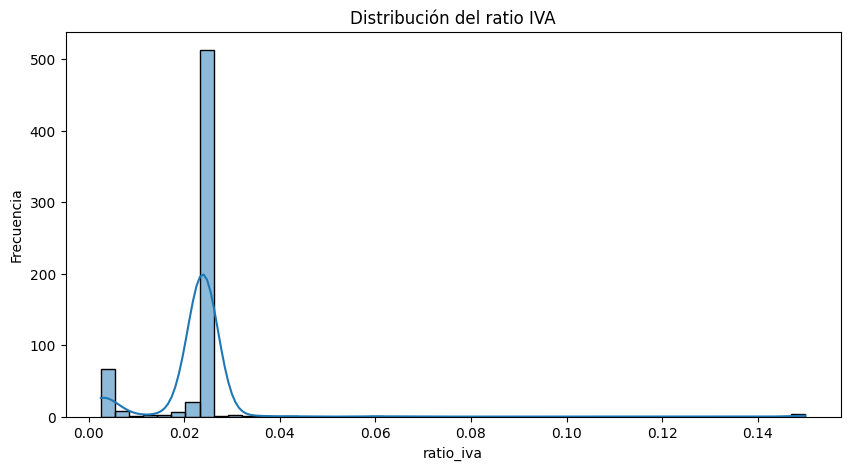

In [ ]:
plt.figure(figsize=(10,5))
sns.histplot(data = df_iva, x = "ratio_iva", bins=50, kde=True)

plt.title("Distribución del ratio IVA")
plt.xlabel("ratio_iva")
plt.ylabel("Frecuencia")
plt.show()

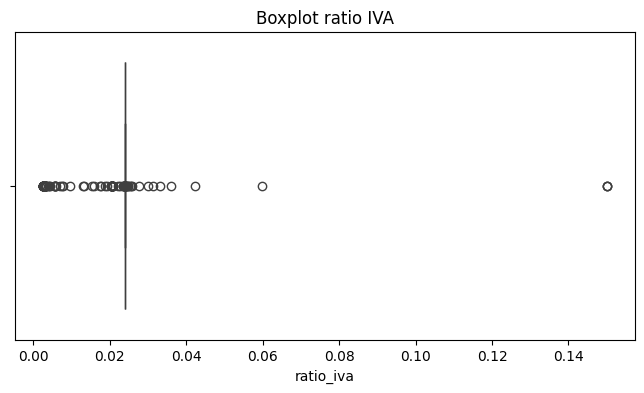

In [ ]:
plt.figure(figsize=(8,4))
sns.boxplot(x=df_iva["ratio_iva"])

plt.title("Boxplot ratio IVA")
plt.show()

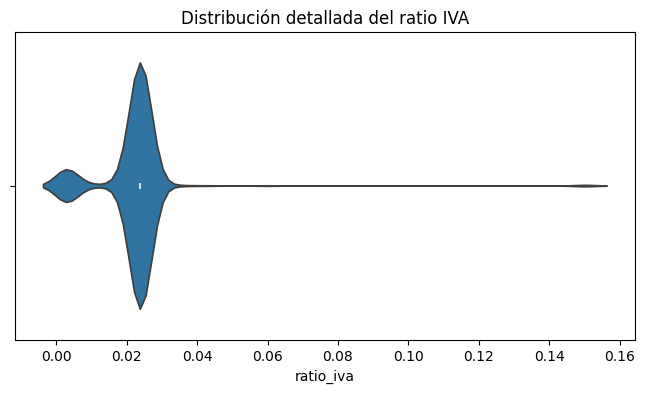

In [ ]:
plt.figure(figsize=(8,4))
sns.violinplot(x=df_iva["ratio_iva"])

plt.title("Distribución detallada del ratio IVA")
plt.show()

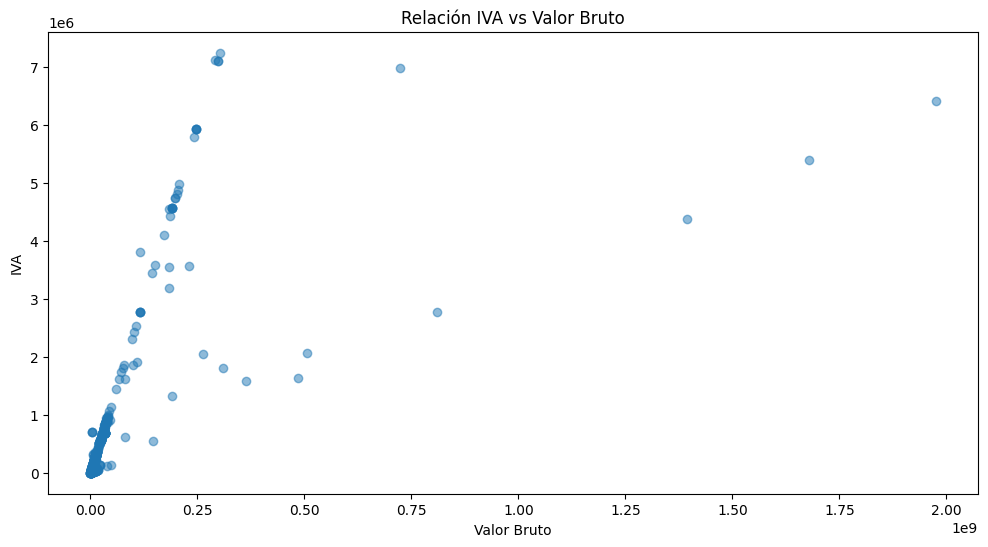

In [ ]:
plt.figure(figsize=(12,6))
plt.scatter(df_iva["Valor Bruto"], df_iva["IVA"], alpha=0.5)

plt.xlabel("Valor Bruto")
plt.ylabel("IVA")
plt.title("Relación IVA vs Valor Bruto")
plt.show()

#### 🚨 Hallazgo

A partir del análisis del campo `ratio_iva` (IVA / Valor Bruto), se identificaron registros con valores atípicos frente a las tarifas estándar del impuesto en Colombia.

En particular:

- Existe una concentración dominante de registros alrededor de un valor cercano a 2.3–2.5%, siendo estos no consistentes con las tarifas comunes de IVA.

Se detectaron:
- 625 Giros con valores significativamente inferiores al rango esperado (5% ó 19%).
- 3 Giros con IVA del 15%

Estos comportamientos indican posibles inconsistencias en la liquidación, registro o clasificación del impuesto.

De acuerdo con la normativa tributaria colombiana (estatuto tributario y reglamentación vigente):

El IVA debe aplicarse conforme a tarifas definidas (ej. 0%, 5%, 19%)
La relación entre IVA y base gravable debe ser consistente y proporcional
Los registros contables deben reflejar correctamente la naturaleza:
- Gravado
- Exento
- Excluido

Se incluirán estos giros tesorales en la muestra

#### ✅ Agregar indices al diccionario de giros

In [ ]:
# 30 aleatorios
df_random = df_iva.sample(n=30, random_state=42)

# 20 más grandes
df_top = df_iva.nlargest(20, 'IVA')

# 20 más pequeños
df_small = df_iva.nlargest(20, 'IVA')

# combinar
df_IVA = pd.concat([df_random, df_top, df_small]).drop_duplicates()

In [ ]:
lista_df.append(df_IVA)

### Análisis de descuentos

#### Inconsistencias relativas de los descuentos

Se presenta cuando un giro no sigue el patrón esperado de su grupo.

- Para ello se evalúa la proporción del valor bruto que va al tota de descuentos.
- Se calcula el Z-Score en base al tipo de gasto. Esto permite comparar los descuentos sin importar la escala.
- Y se filtra tomando 4 desviaciones estándar como casos atípicos. Para disminuir la cantidad de muestra, debido a que tomando 2 desviaciones estándar obtenemos 911 giros tesorales

In [ ]:
df["pct_descuento"] = np.where(
    df["Valor Bruto"] > 0,
    df["Total descuentos"] / df["Valor Bruto"],
    np.nan
)

In [ ]:
df["zscore_grupo_desc"] = (
    df.groupby("Tipo de gasto")["pct_descuento"]
    .transform(lambda x: (x - x.mean()) / x.std())
)

df_pct = df[abs(df["zscore_grupo_desc"]) > 4]
df_pct.sort_values(by="zscore_grupo_desc", ascending= False)

C:\Users\DVadeus\AppData\Local\Temp\ipykernel_15312\3732083056.py:2: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df.groupby("Tipo de gasto")["pct_descuento"]


,Vigencia,Número de orden de pago,ID_Tercero,Fecha Giro,Número de cuenta,Banco,Razon_Social,Tipo de persona,Tipo de gasto,Fecha CRP,...,Total descuentos,Valor Neto,Cuenta contable,Credito,id_unico,año,mes,ratio_iva,pct_descuento,zscore_grupo_desc
2772,2021,5829,79937573,2021-12-16,94457466301,BANCOLOMBIA S A,HUGO PHERNEY SOTELO YAGAMA,NATURAL,SERVICIOS,2021-11-02,...,4700980.0,18699020,1110,18699020,5829_79937573_,2021,12,NaN,0.200897,8.435397
12174,2023,2662,79405054,2023-06-09,20765839275,BANCOLOMBIA S A,LUIS MARTIN LEGUIZAMON CEPEDA,NATURAL,SERVICIOS,2023-03-01,...,2565630.0,11117536,1110,11117536,2662_79405054_,2023,6,0.023950,0.187503,7.753142
2451,2021,5216,28627633,2021-12-07,807039771,BANCO BILBAO VIZCAYA ARGENTARIA COLOMBIA S A,MAGDA CRISTINA MONTAÑA MURILLO,NATURAL,SERVICIOS,2021-04-12,...,998804.0,4542312,1110,4542312,5216_28627633_,2021,12,0.059874,0.180253,7.383873
9812,2022,10153,52710718,2022-12-19,550009900227852,BANCO DAVIVIENDA S.A.,ELENA ROCIO VERASTEGUI NIÑO,NATURAL,SERVICIOS,2022-01-11,...,1502129.0,6899205,1110,6899205,10153_52710718_,2022,12,NaN,0.178796,7.309670
3771,2022,7847,79937573,2022-04-18,94457466301,BANCOLOMBIA S A,HUGO PHERNEY SOTELO YAGAMA,NATURAL,SERVICIOS,2022-07-06,...,2540526.0,13059474,1110,13059474,7847_79937573_,2022,4,NaN,0.162854,6.497609
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2446,2021,5177,40030562,2021-12-07,24093617994,BANCO CAJA SOCIAL S.A.,MARTHA LUCIA HUERTAS MOLANO,NATURAL,SERVICIOS,2021-11-08,...,1271580.0,9830868,1110,9830868,5177_40030562_,2021,12,NaN,0.114531,4.036161
2945,2021,6207,40030562,2021-12-22,24093617994,BANCO CAJA SOCIAL S.A.,MARTHA LUCIA HUERTAS MOLANO,NATURAL,SERVICIOS,2021-11-08,...,1271580.0,9830868,1110,9830868,6207_40030562_,2021,12,NaN,0.114531,4.036161
7407,2022,6527,51999560,2022-10-10,21080712453,BANCOLOMBIA S A,MARIA ROSARIO PINERES ESPINOSA,NATURAL,SERVICIOS,2022-08-31,...,1354506.0,10540974,1110,10540974,6527_51999560_,2022,10,NaN,0.113867,4.002328
5259,2022,3125,51999560,2022-07-07,21080712453,BANCOLOMBIA S A,MARIA ROSARIO PINERES ESPINOSA,NATURAL,SERVICIOS,2022-02-02,...,1354506.0,10540974,1110,10540974,3125_51999560_,2022,7,NaN,0.113867,4.002328


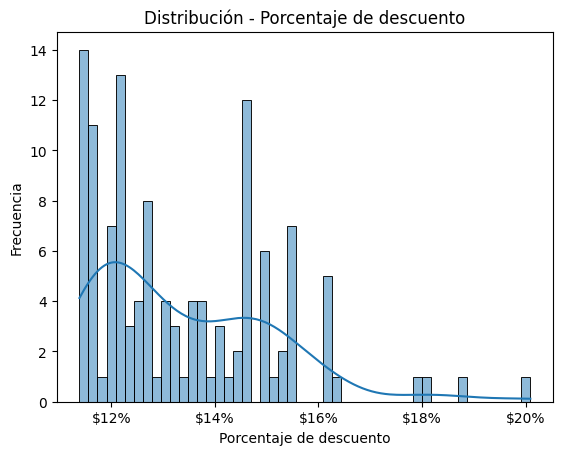

In [ ]:
fig, ax = plt.subplots()

def formato_moneda(x, _):
  return f"${x:.0%}"

ax.xaxis.set_major_formatter(mtick.FuncFormatter(formato_moneda))

sns.histplot(data = df_pct, x = "pct_descuento", bins=50, kde=True)

plt.title("Distribución - Porcentaje de descuento")
plt.xlabel("Porcentaje de descuento")
#plt.xticks(rotation=90)
plt.ylabel("Frecuencia")

plt.show()

#### ✅ Agregar indices al diccionario de giros

In [ ]:
lista_df.append(df_pct.head(30))

Ahora se procede a revisar la composición de los descuentos.

Comparando el ``Total descuentos`` con el ``cálculo de los descuentos``

In [ ]:
componentes = [
    "IVA", "ICA", "ReteFte", "ReteICA", "ReteIVA",
    "Estampilla", "Estampilla Universidad FJC",
    "Adulto mayor", "Otros descuentos"
]

df["suma_componentes"] = df[componentes].sum(axis=1)

df["diff_componentes"] = df["Total descuentos"] - df["suma_componentes"]

# Casos inconsistentes
df_componentes = df[np.abs(df["diff_componentes"]) > 1].sort_values(by = "diff_componentes", ascending = False).head(30)
df_componentes

,Vigencia,Número de orden de pago,ID_Tercero,Fecha Giro,Número de cuenta,Banco,Razon_Social,Tipo de persona,Tipo de gasto,Fecha CRP,...,Cuenta contable,Credito,id_unico,año,mes,ratio_iva,pct_descuento,zscore_grupo_desc,suma_componentes,diff_componentes
14126,2023,7766,45495531,2023-11-10,184150,BANCO DE BOGOTA,ESRI COLOMBIA S.A.S,JURIDICA,SERVICIOS,2023-04-17,...,1110,1098378966,7766_45495531_,2023,11,NaN,0.042900,0.387420,15837038.0,33395496.0
13058,2023,5112,901373456,2023-09-04,79472018,CITIBANK - COLOMBIA S A,UNION TEMPORAL SOFT IG.3,JURIDICA,SERVICIOS,2023-08-28,...,1110,610983628,5112_901373456_,2023,9,NaN,0.042900,0.387420,8809502.0,18576558.0
12846,2023,4680,900105979,2023-08-24,528827753,BANCOLOMBIA S A,BUSINESSMIND COLOMBIA S.A.,JURIDICA,SERVICIOS,2023-08-24,...,1110,608603068,4680_900105979_,2023,8,NaN,0.080660,2.310826,35959840.0,17437080.0
14127,2023,7771,45495531,2023-11-14,528827753,BANCOLOMBIA S A,BUSINESSMIND COLOMBIA S.A.,JURIDICA,SERVICIOS,2023-08-18,...,1110,302849374,7771_45495531_,2023,11,NaN,0.080660,2.310826,17894117.0,8676935.0
15015,2023,9600,860045379,2023-12-28,54009329,ITAÚ CORPBANCA COLOMBIA S A,COMWARE S. A.,JURIDICA,SERVICIOS,2023-10-13,...,1110,229041600,9600_860045379_,2023,12,NaN,0.045660,0.528008,4636800.0,6321600.0
15014,2023,9599,860045379,2023-12-28,54009329,ITAÚ CORPBANCA COLOMBIA S A,COMWARE S. A.,JURIDICA,SERVICIOS,2023-10-13,...,1110,217108246,9599_860045379_,2023,12,NaN,0.045660,0.528008,4395216.0,5992238.0
14098,2023,7661,45495531,2023-11-09,59659635046,BANCOLOMBIA S A,JORGE ELIECER GAITAN TORRES,NATURAL,SERVICIOS,2023-04-04,...,1110,111619009,7661_45495531_,2023,11,NaN,0.149336,5.809028,15979439.0,3615552.0
14957,2023,9488,901719381,2023-12-26,24123102641,BANCO CAJA SOCIAL S.A.,UNION TEMPORAL OMEGA 2023,JURIDICA,SERVICIOS,2023-06-07,...,1110,92864703,9488_901719381_,2023,12,NaN,0.095933,3.088786,7580475.0,2273625.0
14154,2023,7806,45495531,2023-11-15,24123102641,BANCO CAJA SOCIAL S.A.,UNION TEMPORAL OMEGA 2023,JURIDICA,SERVICIOS,2023-06-07,...,1110,88186101,7806_45495531_,2023,11,NaN,0.095933,3.088786,7198565.0,2159078.0
13025,2023,5059,79548029,2023-09-04,59659635046,BANCOLOMBIA S A,JORGE ELIECER GAITAN TORRES,NATURAL,SERVICIOS,2023-04-04,...,1110,47046192,5059_79548029_,2023,9,NaN,0.127514,4.697458,5390007.0,1485801.0


#### 🚨 Hallazgo

Se encuentran 12.935 giros (76.5 %) con diferencias entre ``Total descuentos`` y la suma de estos de manera manual, se ordenan de mayor a menor y se extraen los primeros 20 para la muestra.

#### ✅ Agregar indices al diccionario de giros

In [ ]:
lista_df.append(df_componentes)

Se revisa además los giros con valor bruto superior a $10.000.000 de pesos a los cuales no se les haya aplicado algún descuento.

In [ ]:
giros_sin_descuento = df[(df["Total descuentos"] == 0) & (df["Valor Bruto"] > 10_000_000)].sort_values("Valor Bruto", ascending=False).head(40)   # pagos grandes sin descuento
giros_sin_descuento

,Vigencia,Número de orden de pago,ID_Tercero,Fecha Giro,Número de cuenta,Banco,Razon_Social,Tipo de persona,Tipo de gasto,Fecha CRP,...,Cuenta contable,Credito,id_unico,año,mes,ratio_iva,pct_descuento,zscore_grupo_desc,suma_componentes,diff_componentes
5069,2022,2482,901023218,2022-06-16,833025943,BANCO BILBAO VIZCAYA ARGENTARIA COLOMBIA S A,HQ5 SAS,JURIDICA,CONTRATO,2022-02-26,...,1110,1439307910,2482_901023218_,2022,6,NaN,0.0,-3.520117,0.0,0.0
3896,2022,8226,900062917,2022-10-28,221806300,BANCO DE OCCIDENTE,SERVICIOS POSTALES NACIONALES S A,JURIDICA,SERVICIOS,2022-07-08,...,1110,813074946,8226_900062917_,2022,10,NaN,0.0,-1.797806,0.0,0.0
3179,2021,6776,899999230,2021-12-28,230858938,BANCO DE OCCIDENTE,UNIVERSIDAD DISTRITAL FRANCISCO JOSE DE CALDAS,JURIDICA,SERVICIOS,2021-07-14,...,1110,61880000,6776_899999230_,2021,12,NaN,0.0,-1.797806,0.0,0.0
10956,2023,12774,899999230,2023-11-10,230858938,BANCO DE OCCIDENTE,UNIVERSIDAD DISTRITAL FRANCISCO JOSE DE CALDAS,JURIDICA,SERVICIOS,2023-03-22,...,1110,43680000,12774_899999230_,2023,11,NaN,0.0,-1.797806,0.0,0.0
10833,2023,12403,899999115,2023-04-03,20936029,CITIBANK - COLOMBIA S A,EMPRESA DE TELECOMUNICACIONES DE BOGOTA SA ES...,JURIDICA,SERVICIOS,2023-12-29,...,1110,42927838,12403_899999115_,2023,4,NaN,0.0,-1.797806,0.0,0.0
10869,2023,12455,899999115,2023-04-10,20936029,CITIBANK - COLOMBIA S A,EMPRESA DE TELECOMUNICACIONES DE BOGOTA SA ES...,JURIDICA,SERVICIOS,2023-12-29,...,1110,42925521,12455_899999115_,2023,4,NaN,0.0,-1.797806,0.0,0.0
10870,2023,12456,899999115,2023-04-10,20936029,CITIBANK - COLOMBIA S A,EMPRESA DE TELECOMUNICACIONES DE BOGOTA SA ES...,JURIDICA,SERVICIOS,2023-12-29,...,1110,42874740,12456_899999115_,2023,4,NaN,0.0,-1.797806,0.0,0.0
10934,2023,12718,899999115,2023-09-04,20936029,CITIBANK - COLOMBIA S A,EMPRESA DE TELECOMUNICACIONES DE BOGOTA SA ES...,JURIDICA,SERVICIOS,2023-12-29,...,1110,37856368,12718_899999115_,2023,9,NaN,0.0,-1.797806,0.0,0.0
3902,2022,8253,899999230,2022-12-02,230858938,BANCO DE OCCIDENTE,UNIVERSIDAD DISTRITAL FRANCISCO JOSE DE CALDAS,JURIDICA,SERVICIOS,2022-04-13,...,1110,25491000,8253_899999230_,2022,12,NaN,0.0,-1.797806,0.0,0.0
14378,2023,8268,45495531,2023-12-04,359012929,BANCO DE BOGOTA,INVERSIONES LEE CARDENAS S.A.S,JURIDICA,SERVICIOS,2023-12-01,...,1110,20930955,8268_45495531_,2023,12,NaN,0.0,-1.797806,0.0,0.0


#### ✅ Agregar indices al diccionario de giros

In [ ]:
lista_df.append(giros_sin_descuento)

## Fase 3 - Análisis por Tercero

### Verificación de integridad de datos entre ``ID_Tercero`` y ``Razón Social``

In [ ]:
df_cuentas = (
    df.groupby("ID_Tercero")["Razon_Social"]
    .nunique()
    .reset_index(name="Razón Social")
)

# Filtrar sospechosos
benef_multi_razon = df_cuentas[df_cuentas["Razón Social"] > 1]

benef_multi_razon.sort_values(by="Razón Social", ascending=False).head(20)

,ID_Tercero,Razón Social
307,45495531,392
297,43612348,286
363,52349259,4


In [ ]:
multi_razon = df[df["ID_Tercero"].isin(benef_multi_razon["ID_Tercero"])]
multi_razon

,Vigencia,Número de orden de pago,ID_Tercero,Fecha Giro,Número de cuenta,Banco,Razon_Social,Tipo de persona,Tipo de gasto,Fecha CRP,...,Cuenta contable,Credito,id_unico,año,mes,ratio_iva,pct_descuento,zscore_grupo_desc,suma_componentes,diff_componentes
5940,2022,4287,45495531,2022-08-16,140712258,BANCO DAVIVIENDA S.A.,MARTA PATRICIA PUELLO VEGA,NATURAL,SERVICIOS,2022-07-19,...,1110,1706114,4287_45495531_,2022,8,NaN,0.033000,-0.116839,72339.0,-14115.0
6851,2022,5591,45495531,2022-09-14,140712258,BANCO DAVIVIENDA S.A.,MARTA PATRICIA PUELLO VEGA,NATURAL,SERVICIOS,2022-07-19,...,1110,4267566,5591_45495531_,2022,9,NaN,0.032483,-0.143192,176285.0,-33007.0
7849,2022,7081,45495531,2022-10-20,140712258,BANCO DAVIVIENDA S.A.,MARTA PATRICIA PUELLO VEGA,NATURAL,SERVICIOS,2022-07-19,...,1110,4269309,7081_45495531_,2022,10,NaN,0.032088,-0.163320,172799.0,-31264.0
8913,2022,8679,45495531,2022-11-18,140712258,BANCO DAVIVIENDA S.A.,MARTA PATRICIA PUELLO VEGA,NATURAL,SERVICIOS,2022-07-19,...,1110,4269309,8679_45495531_,2022,11,NaN,0.032088,-0.163320,172799.0,-31264.0
10077,2022,10624,45495531,2022-12-22,140712258,BANCO DAVIVIENDA S.A.,MARTA PATRICIA PUELLO VEGA,NATURAL,SERVICIOS,2022-07-19,...,1110,4269309,10624_45495531_,2022,12,NaN,0.032088,-0.163320,172799.0,-31264.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
16392,2024,1867,45495531,2024-07-16,140712258,BANCO DAVIVIENDA S.A.,MARTA PATRICIA PUELLO VEGA,NATURAL,SERVICIOS,2024-02-05,...,1110,4503291,1867_45495531_,2024,7,NaN,0.027658,-0.388971,140405.0,-12310.0
16508,2024,2320,45495531,2024-08-16,140712258,BANCO DAVIVIENDA S.A.,MARTA PATRICIA PUELLO VEGA,NATURAL,SERVICIOS,2024-02-05,...,1110,4503291,2320_45495531_,2024,8,NaN,0.027658,-0.388971,140405.0,-12310.0
16602,2024,2732,45495531,2024-09-18,140712258,BANCO DAVIVIENDA S.A.,MARTA PATRICIA PUELLO VEGA,NATURAL,SERVICIOS,2024-02-05,...,1110,4503291,2732_45495531_,2024,9,NaN,0.027658,-0.388971,140405.0,-12310.0
16702,2024,3186,45495531,2024-10-18,140712258,BANCO DAVIVIENDA S.A.,MARTA PATRICIA PUELLO VEGA,NATURAL,SERVICIOS,2024-02-05,...,1110,4503291,3186_45495531_,2024,10,NaN,0.027658,-0.388971,140405.0,-12310.0


#### 🚨 Hallazgo

Los ``ID_Tercero`` 45495531, 43612348 y 43612348

Están asociados a:

- Cientos de personas naturales distintas
- Empresas completamente diferentes
- Entidades públicas y privadas
- Uniones temporales
- Operadores de telecomunicaciones y servicios públicos

Afectando a 1194 giros tesorales

Esto supone un problema de integridad crítico, debido a que no es posible confiar en un:

- Un análisis por beneficiario
- Una consolidación de pagos
- Una trazabilidad de giros

Además de esto, existen riesgos en áreas como:

- Dinero asignado a quien no corresponde.
- Imposibilidad de  reconstruir quién recibió qué.
- El uso de identificadores genéricos para dispersar pagos.

El identificador de terceros ``ID_Tercero`` debe ser **único** y representar de manera inequívoca a un beneficiario dentro del sistema.

Por lo tanto, el ``ID_Tercero`` no representa una entidad válida, sino un contenedor de múltiples beneficiarios, lo que evidencia una **falla crítica en la calidad y gestión de los datos**.

Se evalúa a continuación el impacto de los IDs genéricos en el set de datos:

In [ ]:
# Sumatoria de valor neto de los IDs genéricos

total = multi_razon["Valor Neto"].sum()
formatted = f"${total:,.0f}".replace(",", "X").replace(".", ",").replace("X", ".")
print(formatted)

$7.070.076.797


In [ ]:
multi_razon.groupby("Razon_Social")["Valor Neto"].sum().sort_values(ascending=False)

Razon_Social
ESRI COLOMBIA S.A.S                                                        1098378966
BUSINESSMIND COLOMBIA S.A.                                                  302849374
CHALJUB RESTREPO & CIA S.C.A.                                               244984080
UNION TEMPORAL G7                                                           127592500
JORGE ELIECER GAITAN TORRES                                                 111619009
                                                                              ...    
AQUAOCCIDENTE S.A. E.S.P                                                       262040
EMPRESAS PUBLICAS DE ARMENIA E S P                                             177507
ALEJANDRA  TELLEZ CELY                                                         143352
COMUNICACION CELULAR S A COMCEL S A                                            136402
E.S.P. EMPRESA DE OBRAS SANITARIAS DE SANTA ROSA DE CABAL - E.I.C.E.            90603
Name: Valor Neto, Length: 417, dtype: int

En total se encuentran 417 Razones Sociales asociadas a IDs genéricos.

In [ ]:
impacto_ids = (
    df[df["ID_Tercero"].isin(multi_razon["ID_Tercero"])]
    .groupby("ID_Tercero")
    .agg(
        valor_total=("Valor Neto", "sum"),
        num_giros=("id_unico", "count"),
        num_nombres=("Razon_Social", "nunique")
    )
    .reset_index()
)

impacto_ids = impacto_ids.sort_values(by="valor_total", ascending=False)
impacto_ids

,ID_Tercero,valor_total,num_giros,num_nombres
1,45495531,5170631856,814,392
0,43612348,1848952372,372,286
2,52349259,50492569,8,4


#### ⚠️ Por revisar

Para este informe no es posible usar ``ID_Tercero`` como característica de análisis, debido a que no representa una identidad única para cada ``Razón Social``. Se procede a incluir estos giros tesorales a la muestra.

#### ✅ Agregar índices al diccionario de giros

In [ ]:
df_id_dupl = df[df["ID_Tercero"] == 45495531].sample(40, random_state=42)
df_id_dupl

,Vigencia,Número de orden de pago,ID_Tercero,Fecha Giro,Número de cuenta,Banco,Razon_Social,Tipo de persona,Tipo de gasto,Fecha CRP,...,Cuenta contable,Credito,id_unico,año,mes,ratio_iva,pct_descuento,zscore_grupo_desc,suma_componentes,diff_componentes
13987,2023,7424,45495531,2023-11-03,24067508990,BANCO CAJA SOCIAL S.A.,SHIRLEY CASTRILLON VARGAS,NATURAL,SERVICIOS,2023-03-08,...,1110,3196119,7424_45495531_,2023,11,NaN,0.033860,-0.073047,58620.0,53394.0
14346,2023,8223,45495531,2023-12-04,52300022332,BANCOLOMBIA S A,JOSE ANDRES USUGA ARIAS,NATURAL,SERVICIOS,2023-09-01,...,1110,4287813,8223_45495531_,2023,12,NaN,0.027893,-0.377010,25520.0,97511.0
13967,2023,7398,45495531,2023-11-03,455070043225,BANCO DAVIVIENDA S.A.,ALEX ALBERTO ESTUPIÑAN GONZALEZ,NATURAL,SERVICIOS,2023-01-10,...,1110,5221364,7398_45495531_,2023,11,NaN,0.050661,0.782752,194457.0,84179.0
14032,2023,7477,45495531,2023-11-07,30625267844,BANCOLOMBIA S A,TULIA JACQUELINE DELGADO CASAS,NATURAL,SERVICIOS,2023-03-08,...,1110,5681989,7477_45495531_,2023,11,NaN,0.033860,-0.073047,104214.0,94922.0
14296,2023,8126,45495531,2023-12-01,6342064207,SCOTIABANK COLPATRIA,YEIMMY PATRICIA NAVAS CIFUENTES,NATURAL,SERVICIOS,2023-07-25,...,1110,2859759,8126_45495531_,2023,12,NaN,0.027478,-0.398136,14574.0,66227.0
14950,2023,9481,45495531,2023-12-26,57300190709,BANCO DAVIVIENDA S.A.,ALFREDO RAFAEL MARRIAGA MARIMON,NATURAL,SERVICIOS,2023-02-22,...,1110,5002699,9481_45495531_,2023,12,NaN,0.027844,-0.379496,29270.0,114015.0
13937,2023,7356,45495531,2023-11-03,67886563768,BANCOLOMBIA S A,PAULO ROBERTO ALBORNOZ CARREAZO,NATURAL,SERVICIOS,2023-02-20,...,1110,1787067,7356_45495531_,2023,11,NaN,0.027632,-0.390283,9676.0,41108.0
14035,2023,7482,45495531,2023-11-07,23777458,ITAÚ CORPBANCA COLOMBIA S A,IVAN MAURICIO SALAZAR ECHEVERRY,NATURAL,SERVICIOS,2023-04-04,...,1110,11435457,7482_45495531_,2023,11,NaN,0.084973,2.530496,860227.0,201708.0
14196,2023,7962,45495531,2023-11-21,42888909464,BANCOLOMBIA S A,RAFAEL PERDOMO PUENTES,NATURAL,OTROS,2023-11-03,...,1110,109381,7962_45495531_,2023,11,NaN,0.000000,NaN,0.0,0.0
14173,2023,7896,45495531,2023-11-17,3305826773,BANCOLOMBIA S A,GUILLERMO ALBERTO LEON SILVA QUINTERO,NATURAL,SERVICIOS,2023-08-30,...,1110,4982409,7896_45495531_,2023,11,NaN,0.031787,-0.178654,69850.0,93725.0


In [ ]:
lista_df.append(df_id_dupl)

### Beneficiarios con múltiples cuentas bancarias

Se procede a revisar si existen beneficiarios con diferentes cuentas bancarias.

Sin embargo, debido a que no es posible utilizar los 3 ``ID_Tercero`` genéricos, se procede a eliminar los ID genéricos de este análisis y se agruparán con ``Razon_Social``.

In [ ]:
df["Número de cuenta"].astype(str)
df_cuentas = df[~df["ID_Tercero"].isin(benef_multi_razon["ID_Tercero"])]


In [ ]:
df_n_cuentas = (
    df_cuentas
    .groupby(["ID_Tercero", "Razon_Social"])["Número de cuenta"]
    .agg(
        cantidad_cuentas = "nunique",
        lista_cuentas = lambda x: list(x.unique())
    )
    .reset_index()
)

# Filtrar sospechosos
benef_multi_cuentas = df_n_cuentas[df_n_cuentas["cantidad_cuentas"] > 3].sort_values(by="cantidad_cuentas", ascending=False)

benef_multi_cuentas

,ID_Tercero,Razon_Social,cantidad_cuentas,lista_cuentas
16,6805955,CESAR AUGUSTO VARGAS BARRERA,4,"[45391544216, 126300060251, 550126300060251, 1..."
1019,1047382496,MARTIN ALFREDO LAMBIS JARAVA,4,"[91212249021, 8665555241, 550488441372163, 488..."


In [ ]:
benef_multi_cuentas.to_excel("Terceros_con_varias_Cuentas_Bancarias.xlsx")

#### ⚠️ Por revisar

Se han detectado **176** Beneficiarios con más de 2 cuentas bancarias llegando a un máximo de 4 cuentas bancarias. Sin embargo este resultado es sesgado, debido a qué eliminaron del análisis **1194** giros debido a la duplicidad del ``ID_Tercero``

Se procede a agregar los terceros con más de 3 cuentas bancarias a la muestra.

#### ✅ Agregar índices al diccionario de giros

In [ ]:
benef_multi_cuentas = df_n_cuentas[df_n_cuentas["cantidad_cuentas"] >= 3]

df_tercero = df[df["ID_Tercero"].isin(benef_multi_cuentas["ID_Tercero"])]
df_tercero

,Vigencia,Número de orden de pago,ID_Tercero,Fecha Giro,Número de cuenta,Banco,Razon_Social,Tipo de persona,Tipo de gasto,Fecha CRP,...,Cuenta contable,Credito,id_unico,año,mes,ratio_iva,pct_descuento,zscore_grupo_desc,suma_componentes,diff_componentes
448,2021,694,28627633,2021-05-25,807039771,BANCO BILBAO VIZCAYA ARGENTARIA COLOMBIA S A,MAGDA CRISTINA MONTAÑA MURILLO,NATURAL,SERVICIOS,2021-04-12,...,1110,7729642,694_28627633_,2021,5,0.023950,0.070026,1.769147,848564.0,-266532.0
512,2021,946,28627633,2021-06-10,807039771,BANCO BILBAO VIZCAYA ARGENTARIA COLOMBIA S A,MAGDA CRISTINA MONTAÑA MURILLO,NATURAL,SERVICIOS,2021-04-12,...,1110,12378741,946_28627633_,2021,6,0.023950,0.106408,3.622374,1910578.0,-436529.0
617,2021,1406,28627633,2021-07-09,807039771,BANCO BILBAO VIZCAYA ARGENTARIA COLOMBIA S A,MAGDA CRISTINA MONTAÑA MURILLO,NATURAL,SERVICIOS,2021-04-12,...,1110,12497383,1406_28627633_,2021,7,0.023950,0.097844,3.186119,1786809.0,-431402.0
695,2021,1592,900723117,2021-07-13,912033461,BANCO DE BOGOTA,CHALJUB RESTREPO & CIA S.C.A.,JURIDICA,CONTRATO,2021-05-12,...,1110,979271,1592_900723117_,2021,7,0.023949,0.081933,-0.174175,121008.0,-33613.0
696,2021,1594,1151938059,2021-07-13,74143090764,BANCOLOMBIA S A,ANDRES FELIPE MUNERA MORALES,NATURAL,SERVICIOS,2021-06-25,...,1110,225166,1594_1151938059_,2021,7,NaN,0.035001,-0.014913,10500.0,-2333.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
16711,2024,3220,1047441192,2024-10-22,253747521,BANCO BILBAO VIZCAYA ARGENTARIA COLOMBIA S A,NATALIA DE JESUS FRIERI ROMERO,NATURAL,SERVICIOS,2024-01-31,...,1110,5253839,3220_1047441192_,2024,10,NaN,0.027658,-0.388972,163806.0,-14362.0
16764,2024,3609,1047441192,2024-11-14,253747521,BANCO BILBAO VIZCAYA ARGENTARIA COLOMBIA S A,NATALIA DE JESUS FRIERI ROMERO,NATURAL,SERVICIOS,2024-01-31,...,1110,5253839,3609_1047441192_,2024,11,NaN,0.027658,-0.388972,163806.0,-14362.0
16778,2024,3643,1047382496,2024-11-14,488441372163,BANCO DAVIVIENDA S.A.,MARTIN ALFREDO LAMBIS JARAVA,NATURAL,SERVICIOS,2024-02-02,...,1110,900658,3643_1047382496_,2024,11,NaN,0.027658,-0.388971,28081.0,-2462.0
16846,2024,4162,1047441192,2024-12-13,253747521,BANCO BILBAO VIZCAYA ARGENTARIA COLOMBIA S A,NATALIA DE JESUS FRIERI ROMERO,NATURAL,SERVICIOS,2024-01-31,...,1110,5253839,4162_1047441192_,2024,12,NaN,0.027658,-0.388972,163806.0,-14362.0


In [ ]:
lista_df.append(df_tercero)

### Giros sin cuenta bancaria registrada

In [ ]:
sin_cuenta = df[df["Número de cuenta"].isna()]
sin_cuenta

,Vigencia,Número de orden de pago,ID_Tercero,Fecha Giro,Número de cuenta,Banco,Razon_Social,Tipo de persona,Tipo de gasto,Fecha CRP,...,Cuenta contable,Credito,id_unico,año,mes,ratio_iva,pct_descuento,zscore_grupo_desc,suma_componentes,diff_componentes
654,2021,1511,816002019,2021-07-12,<NA>,NaN,EMPRESA DE ENERGIA DE PEREIRA S.A E.S.P,JURIDICA,SERVICIOS,2021-07-12,...,1110,193096,1511_816002019_,2021,7,NaN,0.000000,-1.797806,0.0,0.0
734,2021,1674,901399373,2021-07-14,<NA>,NaN,UNION TEMPORAL DELL EMC,JURIDICA,SERVICIOS,2021-05-28,...,1110,148692,1674_901399373_,2021,7,NaN,0.071035,1.820550,13137.0,-1767.0
744,2021,1688,900651752,2021-07-19,<NA>,NaN,AQUAOCCIDENTE S.A. E.S.P,JURIDICA,SERVICIOS,2021-07-19,...,1110,63660,1688_900651752_,2021,7,NaN,0.000000,-1.797806,0.0,0.0
771,2021,1727,800249860,2021-08-02,<NA>,NaN,CELSIA COLOMBIA S.A E.S.P,JURIDICA,SERVICIOS,2021-07-29,...,1110,263314,1727_800249860_,2021,8,NaN,0.000000,-1.797806,0.0,0.0
828,2021,2006,816002019,2021-08-09,<NA>,NaN,EMPRESA DE ENERGIA DE PEREIRA S.A E.S.P,JURIDICA,SERVICIOS,2021-08-09,...,1110,840875,2006_816002019_,2021,8,NaN,0.000000,-1.797806,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
16349,2024,1734,901394489,2024-07-09,<NA>,NaN,SERVIRED LMA COMUNICACIONES S.A.S.,JURIDICA,SERVICIOS,2024-05-30,...,1110,280279,1734_901394489_,2024,7,NaN,0.000000,-1.797806,0.0,0.0
16365,2024,1800,830114921,2024-07-11,<NA>,NaN,COLOMBIA MOVIL S A E S P,JURIDICA,SERVICIOS,2024-05-30,...,1110,649988,1800_830114921_,2024,7,NaN,0.000000,-1.797806,0.0,0.0
16460,2024,2122,830114921,2024-08-09,<NA>,NaN,COLOMBIA MOVIL S A E S P,JURIDICA,SERVICIOS,2024-05-30,...,1110,649988,2122_830114921_,2024,8,NaN,0.000000,-1.797806,0.0,0.0
16560,2024,2559,830114921,2024-09-06,<NA>,NaN,COLOMBIA MOVIL S A E S P,JURIDICA,SERVICIOS,2024-05-30,...,1110,649988,2559_830114921_,2024,9,NaN,0.000000,-1.797806,0.0,0.0


In [ ]:
sin_cuenta["Valor Neto"].sum()

np.int64(532106484)

#### ⚠️ Por revisar

Un giro sin cuenta bancaria no permite realizar trazabilidad del destino del dinero

Por lo que no es posible verificar si:

- El proveedor es real.
- Cuál es el banco al cuál fue envíado el dinero.
- Verificar si el número de cuenta es del tercero.

Por lo anterior, este caso puede llegar a ser de un riesgo alto ya que da la posibilidad de:

- Sean pagos indebidos.
- Sean registros manipulados.
- Existan fallas en los controles internos de catastro.

Es por ello, que es necesario validar con catastro si el giro fue efectuado por:

- Caja menor
- Pago en efectivo
- Ajustes contables

Sin embargo, según el set de datos. Todos los tipos de giros son **``Transferencia``**

Se procede a agregar estos giros a la muestra.

#### ✅ Agregar índices al diccionario de giros

In [ ]:
lista_df.append(sin_cuenta.head(30))

### Análisis por persona Natural

#### Modelo de detección de riesgo

A continuación se realizará un modelo de riesgo tomando 3 dimensiones clave:

- Concentración del dinero por tercero
- Frecuencias anómalas de giros
- Variabilidad en la consistencias de los montos de los giros

Para ello se buscará caputar los terceros que cumplan las siguientes condiciones:

- Poca actividad mensual: Baja recurrencia
- Alto valor acumulado: Impacto económico
- Alto riesgo: Comportamientos atípicos en los giros

Con esto se podrá evaluar terceros que recibieron mucho dinero en poco tiempo y con patrones anómalos.

Para este análisis serán descartados los 3 ``ID_Tercero`` genéricos. Debido a que ocasionarán ruido sistemático a la detección.

In [ ]:
# Eliminación de los terceros duplicados
df_cuentas_naturales = df_natural[~df_natural["ID_Tercero"].isin(benef_multi_razon["ID_Tercero"])]

Muestra a analizar:

Giros realizados por personas naturales

In [ ]:
df_cuentas_naturales

,Vigencia,Número de orden de pago,ID_Tercero,Fecha Giro,Número de cuenta,Banco,Razon_Social,Tipo de persona,Tipo de gasto,Fecha CRP,...,Adulto mayor,Otros descuentos,Total descuentos,Valor Neto,Cuenta contable,Credito,ID_Soporte,id_unico,año,mes
0,2021,2991,1088259568,2021-02-03,127270151591,BANCO DAVIVIENDA S.A.,YONNY ANDRES CRUZ BENJUMEA,NATURAL,SERVICIOS,2021-04-26,...,37500.0,0.0,63022.0,1499478,1110,1499478,2991,2991_1088259568_,2021,2
1,2021,2992,1088259568,2021-02-03,127270151591,BANCO DAVIVIENDA S.A.,YONNY ANDRES CRUZ BENJUMEA,NATURAL,SERVICIOS,2021-06-21,...,0.0,0.0,0.0,312500,1110,312500,2992,2992_1088259568_,2021,2
2,2021,3001,52539367,2021-02-04,570008870331215,BANCO DAVIVIENDA S.A.,ALEXANDRA VARGAS PINILLA,NATURAL,SERVICIOS,2021-05-12,...,156740.0,0.0,546214.0,7290786,1110,7290786,3001,3001_52539367_,2021,2
3,2021,3047,1094938732,2021-02-08,120237187,BANCOLOMBIA S A,MARIA ALEJANDRA LONDOÑO JIMENEZ,NATURAL,SERVICIOS,2021-06-21,...,30000.0,0.0,52500.0,1447500,1110,1447500,3047,3047_1094938732_,2021,2
4,2021,3053,1093773164,2021-02-08,570457370201248,BANCO DAVIVIENDA S.A.,JURGEN DANIEL TOLOZA DELGADO,NATURAL,SERVICIOS,2021-06-03,...,109680.0,0.0,341099.0,6184861,1110,6184861,3053,3053_1093773164_,2021,2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
16895,2024,4624,1113512793,2024-12-28,85821640704,BANCOLOMBIA S A,MARY YULIANA JARAMILLO,NATURAL,SERVICIOS,2024-02-01,...,138942.0,0.0,189766.0,6757313,1110,6757313,4624,4624_1113512793_,2024,12
16896,2024,4640,1143338180,2024-12-29,78800010080,BANCOLOMBIA S A,YELIZA MERCEDES PEREZ LICONA,NATURAL,SERVICIOS,2024-02-01,...,54033.0,0.0,73423.0,2628219,1110,2628219,4640,4640_1143338180_,2024,12
16897,2024,4641,1047368991,2024-12-29,56600181756,BANCO DAVIVIENDA S.A.,LUISA FERNANDA LARIOS DIAZ,NATURAL,SERVICIOS,2024-01-29,...,54033.0,0.0,74534.0,2627108,1110,2627108,4641,4641_1047368991_,2024,12
16898,2024,4653,64564800,2024-12-30,57700132848,BANCO DAVIVIENDA S.A.,SALMA ELENA CALDAS OTERO,NATURAL,SERVICIOS,2024-02-01,...,0.0,0.0,0.0,2,1110,2,4653,4653_64564800_,2024,12


Se añade la característica ``periodo`` el cuál es el el año y el mes del giro

In [ ]:
df_cuentas_naturales["periodo"] = df_cuentas_naturales["Fecha Giro"].dt.to_period("M")

C:\Users\DVadeus\AppData\Local\Temp\ipykernel_15312\2269863704.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_cuentas_naturales["periodo"] = df_cuentas_naturales["Fecha Giro"].dt.to_period("M")


Se necesitan generar diversas tablas para realizar el modelo de riesgo.

De esas tablas se extraerán las variables aleatorias generadas para consolidarlas en una matriz final.

Generación de tabla de agrupació para el cálculo del **Score** de riesgo

In [ ]:
giros_mes = (
    df_cuentas_naturales.groupby(["ID_Tercero", "Razon_Social", "periodo"])
    .agg(
        num_giros=("id_unico", "count"),
        valor_total=("Valor Neto", "sum"),
        valor_promedio=("Valor Neto", "mean"),
        desviacion=("Valor Neto", "std")
    )
    .reset_index()
).sort_values(by="num_giros", ascending = False)

In [ ]:
giros_mes

,ID_Tercero,Razon_Social,periodo,num_giros,valor_total,valor_promedio,desviacion
4253,79542593,JUAN CARLOS LOZANO MUNEVAR,2022-07,14,374800,2.677143e+04,17854.429684
5028,80211152,JONNATHAN RIGOBERTO POSADA NEIRA,2022-07,12,364500,3.037500e+04,21641.211737
6892,1022923540,DIEGO FERNANDO LOZANO LOZANO,2022-07,12,367500,3.062500e+04,23825.659392
5026,80211152,JONNATHAN RIGOBERTO POSADA NEIRA,2022-05,11,342200,3.110909e+04,25110.533827
102,5638847,LUIS FERNANDO OLARTE GALVIS,2022-07,11,330600,3.005455e+04,20574.176223
...,...,...,...,...,...,...,...
11250,1221980285,JUAN CARLOS CANTILLO LOMANTO,2023-12,1,2501469,2.501469e+06,NaN
11251,1221980285,JUAN CARLOS CANTILLO LOMANTO,2024-02,1,2501469,2.501469e+06,NaN
1563,25181384,MARIA ANDREA VILLALBA YATE,2021-08,1,4866026,4.866026e+06,NaN
11253,1233497236,MAURICIO ALEJANDRO CERON GUALTEROS,2022-08,1,2844549,2.844549e+06,NaN


##### Score de riesgo por mes:

Para la creación de este modelo se crearán dos Score de riesgo, el primero será mensual y el segundo será global.

**Esta granulalidad permite generar una caractéristica de riesgo que alimentará al Score global.**

Se ponderará el riesgo por mes de cada tercero con las siguientes variables:

- Cantidad de giros: 0.4 -> Peso alto
- Valor neto total: 0.4 -> Peso alto
- Coeficiente de Variacion: 0.2 -> Peso medio

In [ ]:
df_riesgo = giros_mes.copy()

df_riesgo["coef_var"] = df_riesgo["desviacion"] / df_riesgo["valor_promedio"]

for col in ["num_giros", "valor_total", "coef_var"]:
    IQR = df_riesgo[col].quantile(0.75) - df_riesgo[col].quantile(0.25)

    if IQR == 0:
        df_riesgo[f"z_{col}"] = 0
    else:    
        df_riesgo[f"z_{col}"] = (df_riesgo[col] - df_riesgo[col].median()) / IQR

df_riesgo["riesgo_score"] = (
    df_riesgo["z_num_giros"] * 0.4 +
    df_riesgo["z_valor_total"] * 0.4 +
    df_riesgo["z_coef_var"] * 0.2
)

df_riesgo.sort_values("riesgo_score", ascending=False)

,ID_Tercero,Razon_Social,periodo,num_giros,valor_total,valor_promedio,desviacion,coef_var,z_num_giros,z_valor_total,z_coef_var,riesgo_score
2152,41520944,MARTHA LUCIA FERNANDEZ SARMIENTO,2021-10,3,93055102,3.101837e+07,3.922048e+06,0.126443,0,27.658960,-0.294514,11.004681
1902,34053651,MARIA GLADIS OCAMPO,2022-12,8,74441066,9.305133e+06,8.408851e+06,0.903679,0,21.860252,0.703027,8.884706
5073,80236543,LEONARDO PALACIO HERNANDEZ,2022-02,6,73443954,1.224066e+07,9.079028e+06,0.741711,0,21.549628,0.495149,8.718881
1892,34053651,MARIA GLADIS OCAMPO,2021-12,3,72120386,2.404013e+07,2.227044e+06,0.092639,0,21.137306,-0.337900,8.387342
1903,34053651,MARIA GLADIS OCAMPO,2023-04,5,55045581,1.100912e+07,9.631331e+06,0.874851,0,15.818104,0.666027,6.460447
...,...,...,...,...,...,...,...,...,...,...,...,...
11250,1221980285,JUAN CARLOS CANTILLO LOMANTO,2023-12,1,2501469,2.501469e+06,NaN,NaN,0,-0.550618,NaN,NaN
11251,1221980285,JUAN CARLOS CANTILLO LOMANTO,2024-02,1,2501469,2.501469e+06,NaN,NaN,0,-0.550618,NaN,NaN
1563,25181384,MARIA ANDREA VILLALBA YATE,2021-08,1,4866026,4.866026e+06,NaN,NaN,0,0.185997,NaN,NaN
11253,1233497236,MAURICIO ALEJANDRO CERON GUALTEROS,2022-08,1,2844549,2.844549e+06,NaN,NaN,0,-0.443740,NaN,NaN


Una vez calculado el riesgo para cada periodo. Se procede a generar la tabla meses activos. Esta tabla contendrá 5 variables aleatorias:

- Número de meses activo
- Valor neto total por tercero
- Giros totales por tercero
- Riesgo máximo por tercero
- Giros por mes

Con estas variables se podrá identificar:

**Terceros con alta actividad, alto valor acumulado y alto riesgo**

In [ ]:
valor_total_tercero = (
    df_riesgo
    .groupby(["ID_Tercero", "Razon_Social"])["valor_total"]
    .sum()
    .reset_index(name = "valor_total_acumulado")
)

In [ ]:
giros_total_tercero = (
    df_riesgo
    .groupby(["ID_Tercero", "Razon_Social"])["num_giros"]
    .sum()
    .reset_index(name = "giros_total_acumulado")
)

In [ ]:
riesgo_max = (
    df_riesgo
    .groupby(["ID_Tercero", "Razon_Social"])["riesgo_score"]
    .max()
    .reset_index(name="riesgo_max")
)

In [ ]:
meses_activos = df_riesgo.groupby(["ID_Tercero", "Razon_Social"])["periodo"].nunique().sort_values(ascending=False).reset_index()
meses_activos

,ID_Tercero,Razon_Social,periodo
0,79864985,EDWUARD ANDRES REYES ALVARADO,36
1,42143060,MONICA ALEXANDRA BLANDON BETANCUR,33
2,1113620936,YURY ALEJANDRA CARVAJAL REINA,30
3,94074087,JOSE MAURICIO MENESES HERNANDEZ,30
4,19497841,CESAR NEY OSORIO ARANGO,30
...,...,...,...
1385,52873558,FRANCI YAZMIN CORTES VEGA,1
1386,52530422,DIANA MARCELA ALBARRACIN NUÑEZ,1
1387,7516912,EVIER DE JESUS DAVILA GUEVARA,1
1388,4516911,ANDRES SAENZ TABORDA,1


In [ ]:
meses_activos = meses_activos.merge(
    valor_total_tercero,
    on=["ID_Tercero", "Razon_Social"],
    how="left"
)
meses_activos = meses_activos.merge(
    giros_total_tercero,
    on=["ID_Tercero", "Razon_Social"],
    how="left"
)
meses_activos = meses_activos.merge(
    riesgo_max,
    on=["ID_Tercero", "Razon_Social"],
    how="left"
)

meses_activos["giros_por_mes"] = (
    meses_activos["giros_total_acumulado"] / meses_activos["periodo"]
)

In [ ]:
meses_activos

,ID_Tercero,Razon_Social,periodo,valor_total_acumulado,giros_total_acumulado,riesgo_max,giros_por_mes
0,79864985,EDWUARD ANDRES REYES ALVARADO,36,291464516,51,2.475441,1.416667
1,42143060,MONICA ALEXANDRA BLANDON BETANCUR,33,167541326,41,1.745435,1.242424
2,1113620936,YURY ALEJANDRA CARVAJAL REINA,30,162253848,36,0.894111,1.200000
3,94074087,JOSE MAURICIO MENESES HERNANDEZ,30,226367580,40,1.433513,1.333333
4,19497841,CESAR NEY OSORIO ARANGO,30,210914680,41,1.459073,1.366667
...,...,...,...,...,...,...,...
1385,52873558,FRANCI YAZMIN CORTES VEGA,1,3441405,1,NaN,1.000000
1386,52530422,DIANA MARCELA ALBARRACIN NUÑEZ,1,8364154,1,NaN,1.000000
1387,7516912,EVIER DE JESUS DAVILA GUEVARA,1,2440750,1,NaN,1.000000
1388,4516911,ANDRES SAENZ TABORDA,1,11190981,3,0.862536,3.000000


##### Score de riesgo global

Con las variables aleatorias generadas, se procede a evaluar el riesgo de cada persona natural de manera global.

Ponderando el riesgo de la siguiente manera:

- valor_total_acumulado: 0.30
- riesgo_max: 0.30
- periodo: 0.10
- giros_total_acumulado: 0.20
- giros_por_mes: 0.10 

Priorizando a los terceros que:

- Reciben más dinero
- En pocos meses
- Con comportamientos irregulares

Evaluando el riesgo por concentración temporal, impacto económico, volumen transaccional y duración.

In [ ]:
df_eval = meses_activos.copy()

def robust_z(col):
    med = col.median()
    iqr = col.quantile(0.75) - col.quantile(0.25)
    if iqr == 0:
        return 0
    return (col - med) / iqr

df_eval["z_valor"] = robust_z(df_eval["valor_total_acumulado"])
df_eval["z_riesgo"] = robust_z(df_eval["riesgo_max"])
df_eval["z_meses"] = robust_z(df_eval["periodo"])
df_eval["z_giros"] = robust_z(df_eval["giros_total_acumulado"])
df_eval["z_giros_mes"] = robust_z(df_eval["giros_por_mes"])

# Invertir meses (pocos meses = más riesgo)
df_eval["z_meses_inv"] = -df_eval["z_meses"]

df_eval["score_evento_concentrado"] = (
    df_eval["z_valor"] * 0.30 +
    df_eval["z_riesgo"] * 0.20 +
    df_eval["z_giros"] * 0.15 +
    df_eval["z_meses_inv"] * 0.20 +
    df_eval["z_giros_mes"] * 0.15
)



df_eval = df_eval.sort_values("score_evento_concentrado", ascending=False)

Debido a que los Z-Score son robustos, estos actúan como rankings relativos más no fijos. 

Por lo que se definirá el riesgo mediante la posición del dato en la distribución mediante percentiles. 

Siendo:

- Alto riesgo: top 5%

In [ ]:
df_eval["percentil"] = df_eval["score_evento_concentrado"].rank(pct=True)

df_eval["categoria_riesgo"] = pd.cut(
    df_eval["percentil"],
    bins=[0, 0.85, 0.95, 1],
    labels=["Bajo", "Medio", "Alto"]
)

In [ ]:
top_5_pct  = df_eval[df_eval["categoria_riesgo"] == "Alto"]
top_5_pct

,ID_Tercero,Razon_Social,periodo,valor_total_acumulado,giros_total_acumulado,riesgo_max,giros_por_mes,z_valor,z_riesgo,z_meses,z_giros,z_giros_mes,z_meses_inv,score_evento_concentrado,percentil,categoria_riesgo
66,34053651,MARIA GLADIS OCAMPO,22,646267273,55,8.884706,2.500000,17.657228,14.163161,2.285714,5.333333,3.194444,-2.285714,8.951825,1.000000,Alto
683,41520944,MARTHA LUCIA FERNANDEZ SARMIENTO,6,194673106,10,11.004681,1.666667,4.877306,17.713075,0.000000,0.333333,1.111111,-0.000000,5.222474,0.999029,Alto
587,80236543,LEONARDO PALACIO HERNANDEZ,7,122125019,15,8.718881,2.142857,2.824226,13.885486,0.142857,0.888889,2.301587,-0.142857,4.074365,0.998058,Alto
30,11312501,RICARDO MAURICIO RODRIGO VALENCIA TOVAR,25,311843773,38,2.682022,1.520000,8.193186,3.776721,2.714286,3.444444,0.744444,-2.714286,3.298776,0.997087,Alto
19,28627633,MAGDA CRISTINA MONTAÑA MURILLO,26,339880071,32,2.614225,1.230769,8.986601,3.663194,2.857143,2.777778,0.021368,-2.857143,3.277062,0.996117,Alto
34,51999560,MARIA ROSARIO PINERES ESPINOSA,24,269557374,37,3.310656,1.541667,6.996499,4.829373,2.571429,3.333333,0.798611,-2.571429,3.170330,0.995146,Alto
7,1111769753,DARLYNG VEGA PANAMEÑO,29,304577174,45,1.967869,1.551724,7.987544,2.580867,3.285714,4.222222,0.823755,-3.285714,3.012190,0.994175,Alto
0,79864985,EDWUARD ANDRES REYES ALVARADO,36,291464516,51,2.475441,1.416667,7.616462,3.430800,4.285714,4.888889,0.486111,-4.285714,2.920206,0.993204,Alto
219,7716810,ALEXANDER MONTEALEGRE TRUJILLO,15,197104915,35,2.628166,2.333333,4.946125,3.686539,1.285714,3.111111,2.777778,-1.285714,2.847336,0.992233,Alto
28,1130628428,JIBER ANTONIO QUINTERO SALAZAR,25,242131968,38,2.570984,1.520000,6.220372,3.590786,2.714286,3.444444,0.744444,-2.714286,2.669745,0.991262,Alto


Se incluye en la matriz el motivo del riesgo de cada tercero y su mayor riesgo.

In [ ]:
def explicar_fila(row):
    razones = []

    if row["z_valor"] > 1:
        razones.append("alto valor total acumulado")

    if row["z_riesgo"] > 1:
        razones.append("comportamiento atípico (alto riesgo_score)")

    if row["z_giros"] > 1:
        razones.append("alto número de giros (posible fraccionamiento)")

    if row["z_meses_inv"] > 1:
        razones.append("concentración en pocos meses")

    if not razones:
        razones.append("combinación moderada de factores de riesgo")

    return ", ".join(razones)

In [ ]:
top_5_pct["explicacion"] = top_5_pct.apply(explicar_fila, axis=1)

C:\Users\DVadeus\AppData\Local\Temp\ipykernel_15312\924549627.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  top_5_pct["explicacion"] = top_5_pct.apply(explicar_fila, axis=1)


In [ ]:
def factor_dominante(row):
    factores = {
        "valor": row["z_valor"],
        "riesgo": row["z_riesgo"],
        "giros": row["z_giros"],
        "meses": row["z_meses_inv"]
    }
    return max(factores.items(), key=lambda x: x[1])[0]

top_5_pct["factor_dominante"] = top_5_pct.apply(factor_dominante, axis=1)

C:\Users\DVadeus\AppData\Local\Temp\ipykernel_15312\1091134119.py:10: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  top_5_pct["factor_dominante"] = top_5_pct.apply(factor_dominante, axis=1)


In [ ]:
top_5_final = top_5_pct[[
    "ID_Tercero",
    "Razon_Social",
    "periodo",
    "valor_total_acumulado",
    "giros_total_acumulado",
    "riesgo_max",
    "score_evento_concentrado",
    "explicacion",
    "factor_dominante"
]].sort_values("score_evento_concentrado", ascending=False)

In [ ]:
top_5_final

,ID_Tercero,Razon_Social,periodo,valor_total_acumulado,giros_total_acumulado,riesgo_max,score_evento_concentrado,explicacion,factor_dominante
66,34053651,MARIA GLADIS OCAMPO,22,646267273,55,8.884706,8.951825,"alto valor total acumulado, comportamiento atí...",valor
683,41520944,MARTHA LUCIA FERNANDEZ SARMIENTO,6,194673106,10,11.004681,5.222474,"alto valor total acumulado, comportamiento atí...",riesgo
587,80236543,LEONARDO PALACIO HERNANDEZ,7,122125019,15,8.718881,4.074365,"alto valor total acumulado, comportamiento atí...",riesgo
30,11312501,RICARDO MAURICIO RODRIGO VALENCIA TOVAR,25,311843773,38,2.682022,3.298776,"alto valor total acumulado, comportamiento atí...",valor
19,28627633,MAGDA CRISTINA MONTAÑA MURILLO,26,339880071,32,2.614225,3.277062,"alto valor total acumulado, comportamiento atí...",valor
34,51999560,MARIA ROSARIO PINERES ESPINOSA,24,269557374,37,3.310656,3.170330,"alto valor total acumulado, comportamiento atí...",valor
7,1111769753,DARLYNG VEGA PANAMEÑO,29,304577174,45,1.967869,3.012190,"alto valor total acumulado, comportamiento atí...",valor
0,79864985,EDWUARD ANDRES REYES ALVARADO,36,291464516,51,2.475441,2.920206,"alto valor total acumulado, comportamiento atí...",valor
219,7716810,ALEXANDER MONTEALEGRE TRUJILLO,15,197104915,35,2.628166,2.847336,"alto valor total acumulado, comportamiento atí...",valor
28,1130628428,JIBER ANTONIO QUINTERO SALAZAR,25,242131968,38,2.570984,2.669745,"alto valor total acumulado, comportamiento atí...",valor


#### Modelo de detección de pagos repetitivos (Fraccionamiento)

In [ ]:
meses_activos.columns

Index(['ID_Tercero', 'Razon_Social', 'periodo', 'valor_total_acumulado',
       'giros_total_acumulado', 'riesgo_max', 'giros_por_mes'],
      dtype='object')

In [ ]:
pagos_repetitivos = giros_mes[
    (giros_mes["periodo"] >= 3) &
    (giros_mes["std_valor"] < giros_mes["promedio_valor"] * 0.3) &
    (giros_mes["std_giros_mes"] < 1)
].sort_values(by="promedio_valor", ascending=False)

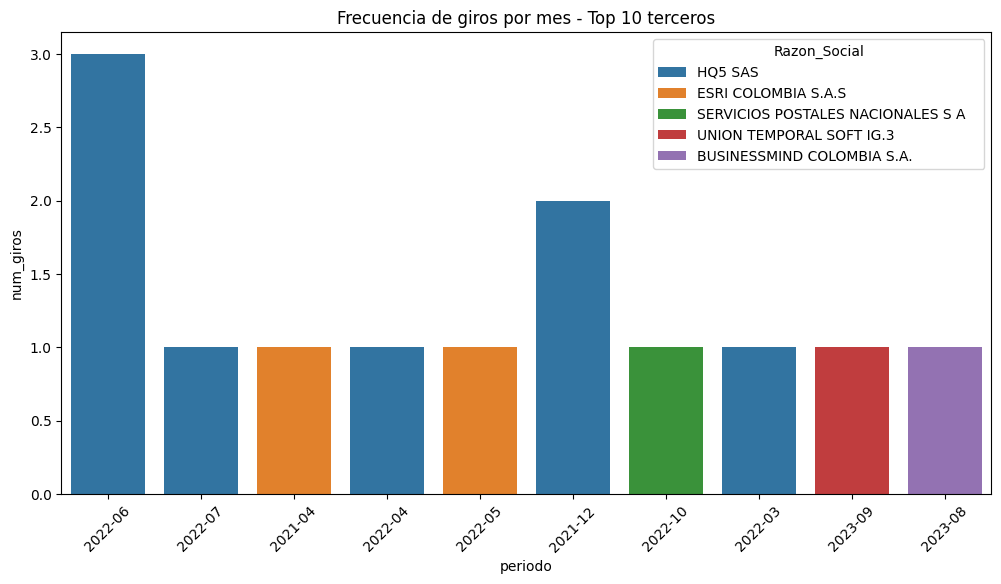

In [ ]:
top = giros_mes.sort_values(by="valor_total", ascending=False).head(10)

plt.figure(figsize=(12,6))
sns.barplot(data=top, x="periodo", y="num_giros", hue="Razon_Social")
plt.xticks(rotation=45)
plt.title("Frecuencia de giros por mes - Top 10 terceros")
plt.show()

Se procede a combinar ambas detecciones: Pagos fraccionados y Pagos Repetitivos.

In [ ]:
df_riesgo = pagos_fraccionados.merge(
    pagos_repetitivos,
    on=["ID_Tercero", "Razon_Social"],
    how="inner"
)

In [ ]:
df_riesgo

,ID_Tercero,Razon_Social,periodo,num_giros,valor_total,valor_promedio,desviacion,coef_variacion,meses_activos,total_giros,promedio_giros_mes,std_giros_mes,promedio_valor,std_valor
0,12747182,RICARDO CESAR TORRES CARVAJAL,2022-12,3,8307511,2.769170e+06,9.611721e+05,0.347097,5,8,1.600000,0.894427,3.901853e+06,1.018819e+06
1,19327055,HENRY RODRÍGUEZ SOSA,2022-10,3,4912636,1.637545e+06,6.004597e+05,0.366683,14,21,1.500000,0.650444,1.924185e+06,3.679091e+05
2,23783928,DIANA GUERRERO RUBIANO,2023-09,3,9490308,3.163436e+06,0.000000e+00,0.000000,11,14,1.272727,0.646670,2.828796e+06,6.062374e+05
3,24720673,MARTA ROCIO GOMEZ GOMEZ,2023-09,3,9585312,3.195104e+06,0.000000e+00,0.000000,14,17,1.214286,0.578934,2.928346e+06,5.731240e+05
4,36180524,ANA VIRGINIA RODRIGUEZ NAVARRO,2022-02,3,3076250,1.025417e+06,2.059643e+05,0.200859,16,19,1.187500,0.543906,2.735382e+06,7.788817e+05
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
64,1130615030,HENRY CHAVEZ LANDAZURI,2023-07,3,10929850,3.643283e+06,1.066419e+06,0.292708,18,26,1.444444,0.921777,3.787794e+06,1.030269e+06
65,1130667505,LUZ ANGELA VIVEROS MESIAS,2022-12,3,7102487,2.367496e+06,1.084102e+06,0.457911,16,22,1.375000,0.619139,3.070592e+06,9.013786e+05
66,1143338180,YELIZA MERCEDES PEREZ LICONA,2024-12,3,7882435,2.627478e+06,6.414361e+02,0.000244,7,11,1.571429,0.786796,2.551974e+06,1.989502e+05
67,1144161103,LUISA MARIA TAGUADO SANDOVAL,2023-07,3,8804130,2.934710e+06,4.527737e+05,0.154282,23,31,1.347826,0.647281,2.783301e+06,7.815099e+05


In [ ]:
df_riesgo.to_excel("pagos_fraccionados_y_repetitivos.xlsx")

### Pagos duplicados

Se procede a analizar si existen pagos repetidos con una diferencia menor o igual a 3 días.

Este resultado será comparado con el percentil 0.9 de ``Valor Neto`` obteniendo de esta manera los casos mas atípicos.

In [ ]:
df_dupl = df_cuentas.sort_values(by=["ID_Tercero", "Valor Neto", "Fecha Giro"])

df_dupl["fecha_anterior"] = df_dupl.groupby(
    ["ID_Tercero", "Valor Neto"]
)["Fecha Giro"].shift(1)

df_dupl["diff_dias"] = (df_dupl["Fecha Giro"] - df_dupl["fecha_anterior"]).dt.days

UMBRAL_DIAS = 3

duplicados = df_dupl[
    (df_dupl["diff_dias"].notna()) &
    (df_dupl["diff_dias"] >= 0) &
    (df_dupl["diff_dias"] <= UMBRAL_DIAS)
]

duplicados_sospechosos = duplicados[
    [
        "ID_Tercero",
        "Razon_Social",
        "Valor Neto",
        "Fecha Giro",
        "fecha_anterior",
        "diff_dias",
        "Número de orden de pago",
        "id_unico"
    ]
].sort_values(by=["ID_Tercero", "Valor Neto", "Fecha Giro"])

In [ ]:
umbral_valor = df["Valor Neto"].quantile(0.9)

duplicados_sospechosos = duplicados_sospechosos[
    duplicados_sospechosos["Valor Neto"] > umbral_valor
]

#### ✅ Agregar índices al diccionario de giros

In [ ]:
duplicados_sospechosos = df[df["id_unico"].isin(duplicados_sospechosos["id_unico"])]
duplicados_sospechosos


,Vigencia,Número de orden de pago,ID_Tercero,Fecha Giro,Número de cuenta,Banco,Razon_Social,Tipo de persona,Tipo de gasto,Fecha CRP,...,Cuenta contable,Credito,id_unico,año,mes,ratio_iva,pct_descuento,zscore_grupo_desc,suma_componentes,diff_componentes
2233,2021,4744,900292243,2021-11-18,4751000060,SCOTIABANK COLPATRIA,ISATECH CORPORATION S.A.S,JURIDICA,SERVICIOS,2021-03-12,...,1110,163015503,4744_900292243_,2021,11,0.023950,0.145513,5.614267,33877931.0,-6117650.0
2581,2021,5485,830047444,2021-12-10,61003099895,BANCOLOMBIA S A,SERVICIOS ESPECIALIZADOS DE TECNOLOGÍA E INFOR...,JURIDICA,SERVICIOS,2021-04-19,...,1110,63221254,5485_830047444_,2021,12,NaN,0.031900,-0.172895,2533813.0,-450601.0
2786,2021,5877,52469447,2021-12-17,22194965862,BANCOLOMBIA S A,MARIA ANDREA ROZO MEDINA,NATURAL,SERVICIOS,2021-02-11,...,1110,10739832,5877_52469447_,2021,12,NaN,0.097150,3.150797,1176727.0,-21079.0
2994,2021,6454,72270429,2021-12-23,50201415801,BANCOOMEVA,JUAN CARLOS ARANA SOSA,NATURAL,SERVICIOS,2021-02-23,...,1110,9470719,6454_72270429_,2021,12,NaN,0.102074,3.401602,1123332.0,-46725.0
2995,2021,6455,72270429,2021-12-23,50201415801,BANCOOMEVA,JUAN CARLOS ARANA SOSA,NATURAL,SERVICIOS,2021-02-23,...,1110,9470719,6455_72270429_,2021,12,NaN,0.102074,3.401602,1123332.0,-46725.0
3062,2021,6631,900431030,2021-12-23,805163078,BANCO COMERCIAL AV VILLAS S.A.,INGENIERIAS Y CONSTRUCCIONES NISSI S.A.S.,JURIDICA,SERVICIOS,2021-05-31,...,1110,8665903,6631_900431030_,2021,12,0.023950,0.145513,5.614265,1800950.0,-325214.0
3245,2022,6863,80236543,2022-02-04,1600093684,BANCO DAVIVIENDA S.A.,LEONARDO PALACIO HERNANDEZ,NATURAL,SERVICIOS,2022-07-07,...,1110,20528640,6863_80236543_,2022,2,NaN,0.161233,6.415040,4162957.0,-216807.0
3375,2022,7191,900431030,2022-02-14,805163078,BANCO COMERCIAL AV VILLAS S.A.,INGENIERIAS Y CONSTRUCCIONES NISSI S.A.S.,JURIDICA,CONTRATO,2022-03-17,...,1110,8665903,7191_900431030_,2022,2,0.023950,0.145513,2.422268,1800950.0,-325214.0
3437,2022,7290,900431030,2022-02-17,805163078,BANCO COMERCIAL AV VILLAS S.A.,INGENIERIAS Y CONSTRUCCIONES NISSI S.A.S.,JURIDICA,CONTRATO,2022-03-17,...,1110,8665903,7290_900431030_,2022,2,0.023950,0.145513,2.422268,1800950.0,-325214.0
3783,2022,7874,900431030,2022-05-19,805163078,BANCO COMERCIAL AV VILLAS S.A.,INGENIERIAS Y CONSTRUCCIONES NISSI S.A.S.,JURIDICA,CONTRATO,2022-03-17,...,1110,8665903,7874_900431030_,2022,5,0.023950,0.145513,2.422268,1800950.0,-325214.0


In [ ]:
lista_df.append(duplicados_sospechosos)

Se realiza un cruce con pagos fraccionados, para así obtener como resultado: Pagos duplicados y Pagos fragmentados para un mismo tercero.

In [ ]:
riesgo_total = duplicados_sospechosos.merge(
    pagos_fraccionados,
    on=["ID_Tercero"],
    how="inner"
)

In [ ]:
riesgo_total

,Vigencia,Número de orden de pago,ID_Tercero,Fecha Giro,Número de cuenta,Banco,Razon_Social_x,Tipo de persona,Tipo de gasto,Fecha CRP,...,zscore_grupo_desc,suma_componentes,diff_componentes,Razon_Social_y,periodo,num_giros,valor_total,valor_promedio,desviacion,coef_variacion
0,2023,5014,19497841,2023-09-04,2800044493,BANCO DAVIVIENDA S.A.,CESAR NEY OSORIO ARANGO,NATURAL,SERVICIOS,2023-02-02,...,1.849008,480424.0,163919.0,CESAR NEY OSORIO ARANGO,2024-04,3,12888225,4296075.0,1.985091e+06,0.462071


#### ✅ Agregar índices al diccionario de giros

In [ ]:
lista_df.append(riesgo_total)

## Muestra

La muestra se tomará mediante un muestreo estratificado y por ponderación, buscando detectar errores materiales, la identificación de anomalías y el cumplimiento de las normas.

La cantidad de muestra será calculada mediante la fórmula clásica de tamaño de muestra y se realizará el ajuste por población finita.

**Fórmula de tamaño de muestra**

$$ n = \frac{Z^2 \cdot p  \cdot (1-p)}{e^2} $$

Donde:

- $n$ = Tamaño de la muestra
- $Z$ = Nivel de confianza
- $p$ = Proporción de error
- $e$ = Margen de error

**Ajuste por población finita**

$$ n_{ajustada} = \frac{n}{1 +{\frac{n-1}{N}}}$$

Donde:

$N$ = Total de giros

Se usarán los siguientes parámetros para el cálculo:

- $n$ = 16900
- $Z$ = 95%
- $p$ = 0.5
- $e$ = 4%

In [ ]:
N = len(df)
Z = 1.96
p = 0.5
e = 0.04

n = (Z**2 * p * (1-p)) / (e**2)
n_ajustada = n / (1 + (n-1)/N)

print(int(n_ajustada))

579


La muestra total es de 517 Giros tesorales

In [ ]:
rows = 0
for fila in lista_df:
    rows += len(fila)

print(rows)

600


In [ ]:
nombres = [
    'Outlier banco',
    'Outlier tipo de gasto',
    'Persona jurídica riesgo',
    'Persona natural riesgo',
    'Orden de pago duplicado',
    'IVA incorrecto',
    'Z-Score descuento > 4',
    'Diferencia en descuento',
    'Giro sin descuento',
    'ID_Tercero duplicado',
    'Tercero multiples cuentas',
    'Tercero sin cuenta',
    'Giros repetidos en menos de 3 días',
    'Giro duplicado y fraccionado'
]

df_final = pd.concat([
    df.assign(origen=nombre)
    for df, nombre in zip(lista_df, nombres)
], ignore_index=True)

C:\Users\DVadeus\AppData\Local\Temp\ipykernel_14300\3824518311.py:18: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  df_final = pd.concat([


In [ ]:
df_final

,Vigencia,Número de orden de pago,ID_Tercero,Fecha Giro,Número de cuenta,Banco,Razon_Social,Tipo de persona,Tipo de gasto,Fecha CRP,...,ID_Soporte,origen,id_unico,año,mes,ratio_iva,pct_descuento,zscore_grupo_desc,suma_componentes,diff_componentes
0,2022,7449,1018424802,3/03/2022,60271178568.0,BANCOLOMBIA S A,LIZ YORLENY RODRIGUEZ GOMEZ,NATURAL,SERVICIOS,NaT,...,7449.0,Outlier banco,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2022,8046,80192761,24/06/2022,24527484262.0,BANCO CAJA SOCIAL S.A.,AGAPITO CASTRO CASTRO,NATURAL,SERVICIOS,NaT,...,8046.0,Outlier banco,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2021,946,28627633,2021-06-10 00:00:00,807039771,BANCO BILBAO VIZCAYA ARGENTARIA COLOMBIA S A,MAGDA CRISTINA MONTAÑA MURILLO,NATURAL,SERVICIOS,2021-04-12,...,946.0,Outlier tipo de gasto,946_28627633_,2021.0,6.0,NaN,NaN,NaN,NaN,NaN
3,2021,1406,28627633,2021-07-09 00:00:00,807039771,BANCO BILBAO VIZCAYA ARGENTARIA COLOMBIA S A,MAGDA CRISTINA MONTAÑA MURILLO,NATURAL,SERVICIOS,2021-04-12,...,1406.0,Outlier tipo de gasto,1406_28627633_,2021.0,7.0,NaN,NaN,NaN,NaN,NaN
4,2021,2050,28627633,2021-08-10 00:00:00,807039771,BANCO BILBAO VIZCAYA ARGENTARIA COLOMBIA S A,MAGDA CRISTINA MONTAÑA MURILLO,NATURAL,SERVICIOS,2021-04-12,...,2050.0,Outlier tipo de gasto,2050_28627633_,2021.0,8.0,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
501,2024,1910,1047382496,2024-07-18 00:00:00,488441372163,BANCO DAVIVIENDA S.A.,MARTIN ALFREDO LAMBIS JARAVA,NATURAL,SERVICIOS,2024-02-02,...,NaN,Giro duplicado y fraccionado,1910_1047382496_,2024.0,7.0,NaN,0.027658,-0.388971,140405.0,-12310.0
502,2024,2363,1047382496,2024-08-21 00:00:00,488441372163,BANCO DAVIVIENDA S.A.,MARTIN ALFREDO LAMBIS JARAVA,NATURAL,SERVICIOS,2024-02-02,...,NaN,Giro duplicado y fraccionado,2363_1047382496_,2024.0,8.0,NaN,0.027658,-0.388971,140405.0,-12310.0
503,2024,2775,1047382496,2024-09-19 00:00:00,488441372163,BANCO DAVIVIENDA S.A.,MARTIN ALFREDO LAMBIS JARAVA,NATURAL,SERVICIOS,2024-02-02,...,NaN,Giro duplicado y fraccionado,2775_1047382496_,2024.0,9.0,NaN,0.027658,-0.388971,140405.0,-12310.0
504,2024,3184,1047382496,2024-10-18 00:00:00,488441372163,BANCO DAVIVIENDA S.A.,MARTIN ALFREDO LAMBIS JARAVA,NATURAL,SERVICIOS,2024-02-02,...,NaN,Giro duplicado y fraccionado,3184_1047382496_,2024.0,10.0,NaN,0.027658,-0.388971,140405.0,-12310.0


In [ ]:
df.columns

Index(['Vigencia', 'Número de orden de pago', 'ID_Tercero', 'Fecha Giro',
       'Número de cuenta', 'Banco', 'Razon_Social', 'Tipo de persona',
       'Tipo de gasto', 'Fecha CRP', 'CRP', 'Fecha CDP', 'CDP', 'Valor Bruto',
       'IVA', 'Actividad gravada IVA', 'Porcentaje ICA', 'ICA',
       'Actividad gravada ICA', 'Porcentaje ReteFte', 'ReteFte', 'ReteICA',
       'ReteIVA', 'Estampilla', 'Estampilla Universidad FJC', 'Adulto mayor',
       'Otros descuentos', 'Total descuentos', 'Valor Neto', 'Cuenta contable',
       'Credito', 'id_unico', 'año', 'mes', 'ratio_iva', 'pct_descuento',
       'zscore_grupo_desc', 'suma_componentes', 'diff_componentes'],
      dtype='object')

In [ ]:
df["Número de cuenta"].dtype

dtype('O')

In [ ]:
df_final.to_excel("muestra.xlsx")

## Revisión adicional

### Números de cuenta sospechosos

In [ ]:
get_len = lambda x: len(x) if x is not pd.NA else 0
df["Longitud_numero_cuenta"] = df["Número de cuenta"].apply(get_len)
numero_de_cuenta_df = df[(df["Longitud_numero_cuenta"] > 0) & (df["Longitud_numero_cuenta"] < 8)].sort_values(by = "Longitud_numero_cuenta")
numero_de_cuenta_df.groupby("Número de cuenta")["ID_Tercero"].sum()

Número de cuenta
1164532      800249860
184150      3365987463
2302370     9013172480
3210        3440038312
5711714       80144979
5718349       53008884
622290     28353505215
678532      6310797591
7540593     1272004272
8818747      317896748
Name: ID_Tercero, dtype: int64

In [ ]:
df[df["ID_Tercero"]==860009578]

,Vigencia,Número de orden de pago,ID_Tercero,Fecha Giro,Número de cuenta,Banco,Razon_Social,Tipo de persona,Tipo de gasto,Fecha CRP,...,Credito,id_unico,año,mes,ratio_iva,pct_descuento,zscore_grupo_desc,suma_componentes,diff_componentes,Longitud_numero_cuenta
7464,2022,6605,860009578,2022-10-11,20712178194,BANCOLOMBIA S A,SEGUROS DEL ESTADO,JURIDICA,SERVICIOS,2022-04-08,...,1743854,6605_860009578_,2022,10,NaN,0.030253,-0.256807,54402.0,0.0,11
10874,2023,12474,860009578,2023-04-11,3210,BANCO DE BOGOTA,SEGUROS DEL ESTADO,JURIDICA,SERVICIOS,2023-04-11,...,354557,12474_860009578_,2023,4,NaN,0.030253,-0.256795,11061.0,0.0,4
10923,2023,12647,860009578,2023-07-12,3210,BANCO DE BOGOTA,SEGUROS DEL ESTADO,JURIDICA,SERVICIOS,2023-04-11,...,3099228,12647_860009578_,2023,7,NaN,0.030252,-0.256835,96683.0,0.0,4
10937,2023,12730,860009578,2023-09-12,3210,BANCO DE BOGOTA,SEGUROS DEL ESTADO,JURIDICA,SERVICIOS,2023-04-11,...,377968,12730_860009578_,2023,9,NaN,0.030255,-0.256712,11792.0,0.0,4
10961,2023,12786,860009578,2023-12-07,3210,BANCO DE BOGOTA,SEGUROS DEL ESTADO,JURIDICA,SERVICIOS,2023-04-11,...,553558,12786_860009578_,2023,12,NaN,0.030253,-0.256809,17269.0,0.0,4
16153,2024,1103,860009578,2024-06-04,20712178194,BANCOLOMBIA S A,SEGUROS DEL ESTADO,JURIDICA,SERVICIOS,2024-05-30,...,470688,1103_860009578_,2024,6,NaN,0.030253,-0.256785,14684.0,0.0,11


415
